# 18 · Rétropropagation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/ch18_backprop/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | 18.Q1 à 18.Q12, 18.R1 à 18.R3, 18.1 à 18.5, 18.9 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | 18.12 | mse_loss : la loss et son gradient | 🔨 | ★ | 10 |
|  | 18.13 | La méthode très lente : combien d'essais pour progresser ? | 🔮 | ★★ | 20 |
|  | 18.14 | Cross-entropies calculées sur les logits (binaire et softmax) | 🔨 | ★★ | 30 |
|  | 18.15 | dense_backward : les trois gradients d'une couche | 🔨 | ★★ | 25 |
|  | 18.16 | gradient_check : vérifier un gradient par différences finies | 🔨 | ★★ | 25 |
|  | 18.17 | Chasse au bug : trois gradients faux démasqués | 🐛 | ★★ | 25 |
| B | 18.18 | mlp_backward : rétropropager à travers tout le réseau | 🔨 | ★★★ | 45 |
|  | 18.19 | Entraîner le réseau 2-4-4-1 à 37 poids sur les lunes | 🔨 | ★★★ | 45 |
|  | 18.20 | La même expérience avec MLPClassifier(solver='sgd') | 📦 | ★★ | 20 |
|  | 18.21 | Reproduire les figures 18.49 à 18.57 (η = 0,5 ; 0,05 ; 0,01) | 🎨 | ★★ | 30 |
| C | 18.22 | Lire des courbes de loss : divergence, lenteur, plateau, bug | 📈 | ★★ | 20 |
|  | 18.23 | Balayage du learning rate sur cinq graines | 🔬 | ★★★ | 40 |
|  | 18.24 | Neurones saturés et ReLU mortes pendant l'entraînement | 🔬 | ★★★ | 45 |
|  | 18.25 | Écrire un test pytest de gradient pour une couche | 🛠️ | ★★ | 25 |
| D | 18.26 | Micro-autograd : la classe Value | 🔨 | ★★★ | 90 |
|  | 18.27 | À la main, Value, mlp_backward, différences finies : quatre gradients identiques ? | 🔮 | ★★ | 20 |
|  | 18.28 | MiniMLP : entraîner un petit réseau fait de Value | 🔨 | ★★★ | 45 |
|  | 18.29 | Défi MNIST : au moins 97 % avec ton MLP NumPy | 🏆 | ★★★★ | 120 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.13 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Calculer à la main les deltas, les gradients et un pas de mise à jour d'un petit réseau, avec et sans activation.
- Écrire et vérifier contre PyTorch les fonctions de `mylearn.nn.backward` (les losses avec leur gradient, `dense_backward`, `mlp_backward`, `gradient_check`) et le micro-autograd `mylearn.autograd_mini` (`Value`, `MiniMLP`).
- Entraîner un MLP from scratch et diagnostiquer le learning rate, les plateaux, la saturation et les neurones morts.

**Rappel express.** $\delta_j = \partial L / \partial z_j$ ; sortie, loss quadratique : $\delta_k = (\hat{y}_k - y_k)\,f'(z_k)$ ; caché : $\delta_j = f'(z_j) \sum_k w_{jk}\,\delta_k$ ; $\partial L / \partial w_{ij} = a_i\,\delta_j$, $\partial L / \partial b_j = \delta_j$ ; $w \leftarrow w - \eta\,\partial L / \partial w$. En matrices : $\boldsymbol{\Delta} = \mathbf{G} \odot f'(\mathbf{Z})$, $d\mathbf{W} = \mathbf{A}_{\text{prev}}^\top\boldsymbol{\Delta}$, $d\mathbf{b} = \mathbf{1}^\top\boldsymbol{\Delta}$, $\mathbf{G}_{\text{prev}} = \boldsymbol{\Delta}\mathbf{W}^\top$. Cross-entropy sur les logits : $(\mathbf{P} - \mathbf{Y})/n$ ; binaire : $(\sigma(\mathbf{z}) - \mathbf{y})/n$. Vérification : $\frac{L(w + \varepsilon) - L(w - \varepsilon)}{2\varepsilon}$, erreur relative $\frac{|a - n|}{\max(|a| + |n|, 10^{-12})}$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ 18.1 à 18.5 et 🧮 18.9)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un sens : `+1` (monter) ou `-1` (baisser) ; un choix : la lettre seule, entre guillemets (`"E"`) ; plusieurs choix ou une suite : les lettres collées, dans l'ordre demandé (`"CADB"`) ; plusieurs nombres : une liste (`[4, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », les preuves ∂ 18.6 à 18.8, la réflexion (🗣️ 18.10, 📄 18.11) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math

import numpy as np
from scipy import special


def sigma(z):
    return special.expit(z)


# 18.3: L(w) = (a/2)(w - w*)^2 with a = 4, w* = 1, from w0 = 3
A_183, WSTAR_183, W0_183 = 4.0, 1.0, 3.0


def w_183(eta, t, curvature=A_183):
    return WSTAR_183 + (1 - eta * curvature) ** t * (W0_183 - WSTAR_183)


# 18.4 and 18.5: the tiny network X, Y -> A, B -> C, D (no bias), one example, label (1, 0)
X_184 = np.array([1.0, 2.0])
W1_184 = np.array([[0.5, 1.0], [-0.5, 0.25]])     # rows X, Y; columns A, B
W2_184 = np.array([[1.0, -1.0], [0.5, 0.5]])      # rows A, B; columns C, D
Y_184 = np.array([1.0, 0.0])


def tiny_184(W1, W2, f=lambda z: z, df=lambda z: np.ones_like(z)):
    """Forward and backward pass of the tiny network, loss 1/2 sum (out - y)^2, linear outputs."""
    z1 = X_184 @ W1
    a1 = f(z1)
    out = a1 @ W2
    loss = 0.5 * float(np.sum((out - Y_184) ** 2))
    d2 = out - Y_184
    d1 = (W2 @ d2) * df(z1)
    return dict(z1=z1, a1=a1, out=out, loss=loss, d2=d2, d1=d1, g1=np.outer(X_184, d1), g2=np.outer(a1, d2))


LIN_184 = tiny_184(W1_184, W2_184)
SIG_185 = tiny_184(W1_184, W2_184, f=sigma, df=lambda z: sigma(z) * (1 - sigma(z)))
GRAD2_184 = float(np.sum(LIN_184["g1"] ** 2) + np.sum(LIN_184["g2"] ** 2))

# 18.9: a 784-256-128-10 MLP on MNIST
SIZES_189 = [784, 256, 128, 10]
P_189 = sum(a * b + b for a, b in zip(SIZES_189[:-1], SIZES_189[1:]))
F_189 = sum(a * b for a, b in zip(SIZES_189[:-1], SIZES_189[1:]))      # multiplications of one forward pass

**18.Q1 — Pourquoi apprendre la rétropropagation si PyTorch la fait pour toi ?**

In [3]:
wb.record("18.Q1a", False, mistakes={"relis le §18.1 : qui calcule les gradients dans un projet réel ?": True})
wb.record("18.Q1b", "D", mistakes={"relis les quatre raisons du livre : la littérature et les échanges en font partie": "A",
          "relis les quatre raisons du livre : le diagnostic d'un réseau qui apprend mal en fait partie": "B",
          "relis les quatre raisons du livre : les idées qui s'appuient sur elle en font partie": "C"})
wb.record("18.Q1c", False, mistakes={"relis le début du §18.1 : un réseau n'est qu'un assemblage de petits calculs": True})

WB_ANSWER {"hash": "9b7f7c47efaa74b5b98ca4629b5e0996f562d0417676bd724e5e471443397f8c", "id": "18.Q1a", "kind": "bool", "mistakes": {"1f8101e1f4c9cd4ee7f0f4067f6ae19889d1a09dfbe50c9cc9ed44bdeac344e4": "relis le §18.1 : qui calcule les gradients dans un projet réel ?"}}
📝 Ex 18.Q1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "f3f8d71b1c00a47424ec67f66cc84c3187e26853e2acafc21999654eb92d93bc", "id": "18.Q1b", "kind": "str", "mistakes": {"1af49ad69063de92d16743b72efe2d6e4d85040c46f17742fe6f4807fd503088": "relis les quatre raisons du livre : la littérature et les échanges en font partie", "8e467704b2c46aeaac027edb2312bdf86c5924c0ed43324117de89cc8f0b388b": "relis les quatre raisons du livre : les idées qui s'appuient sur elle en font partie", "f752469192d4550de2e75be04d525519661f22615f838289cf21b8cfa1a596f9": "relis les quatre raisons du livre : le diagnostic d'un réseau qui apprend mal en fait partie"}}
📝 Ex 18.Q1b : réponse enregistrée (str).
WB_ANSWER {"hash": "c502dd7a9f4710c4076abeb

**18.Q2 — Perturber un poids au hasard : pourquoi est-ce si lent ?**

In [4]:
wb.record("18.Q2a", 1_000_000, mistakes={"un essai par poids, une passe avant par essai : la passe de départ ne compte pas ici": 1_000_001,
          "un seul essai par poids, et une seule passe avant par essai": 2_000_000,
          "combien de poids faut-il essayer, chacun une fois ?": 1})
wb.record("18.Q2b", 0.5, decimals=2, mistakes={"deux sens possibles, tirés au hasard : lequel fait baisser l'erreur ?": 0.25,
          "une proportion entre 0 et 1 : combien de sens possibles, et combien de bons ?": 1.0})
wb.record("18.Q2c", True, mistakes={"relis la p. 714 : un poids sert à tous les exemples": False})
wb.record("18.Q2d", "B", mistakes={"relis la fin du §18.2.1 : l'astuce du biais du ch. 10": "A",
          "le biais aussi doit être appris": "C", "c'est l'entrée du biais qui vaut 1, pas le biais lui-même": "D"})

WB_ANSWER {"hash": "0195adc408e3595b7bc3424f331f39398ebe0c2310af0072cfc6acbc86d0a037", "id": "18.Q2a", "kind": "int", "magnitude": 6, "mistakes": {"5b75f37ea49a9550c6fa1f7dc29d9d0af577bb6e9d0dce80e0ce689e8e13d4b4": "combien de poids faut-il essayer, chacun une fois ?", "bcc66320858eabd63883b021faa9a6846b103c74513a9546b61529bebf6c5116": "un essai par poids, une passe avant par essai : la passe de départ ne compte pas ici", "edbd478231a02989c0eaaab221f54f0d352ee3d8e578c4a960a02ba2a4cb5f60": "un seul essai par poids, et une seule passe avant par essai"}, "sign": 1}
📝 Ex 18.Q2a : réponse enregistrée (int).
WB_ANSWER {"decimals": 2, "hash": "ad1273df52e78f96fbf254c4464fe40a583155c4392a857ad7f92c24704d5daa", "hash_coarse": "41e83d51cab5ea3c0ee47e3570c2ca65cf9a7b611cae17d10416e373c8a2db8a", "id": "18.Q2b", "kind": "float", "magnitude": -1, "mistakes": {"ab150b30f65c84999a04526af9d0b2bb1fa6142af63b98fa1d6ec7e662387859": "deux sens possibles, tirés au hasard : lequel fait baisser l'erreur ?", "

**18.Q3 — Ce que le gradient dit à chaque poids, et le cas du biais**

In [5]:
wb.record("18.Q3a", 1, mistakes={"une pente négative : que fait l'erreur quand le poids augmente ?": -1,
          "il faut choisir un sens : +1 ou −1": 0})
wb.record("18.Q3b", -1, mistakes={"une pente positive : que fait l'erreur quand le poids augmente ?": 1,
          "il faut choisir un sens : +1 ou −1": 0})
wb.record("18.Q3c", True, mistakes={"relis la fin du §18.2.2 : c'est justement le pari du livre, à petits pas": False})
wb.record("18.Q3d", "B", mistakes={"les activations usuelles ont une dérivée (presque) partout": "A",
          "le livre remet les activations au §18.10": "C", "relis le ch. 17 : un réseau sans activation s'effondre": "D"})

WB_ANSWER {"hash": "a8038e804bc47c7b29f220bd9197d75a4d2696ae878fd883373bfd90c3e83fab", "id": "18.Q3a", "kind": "int", "magnitude": 0, "mistakes": {"4f350b7c62b2d6e441e3fbc50fb377bc02e12c04a4fd72210ce50d422026033b": "il faut choisir un sens : +1 ou −1", "cb1b9cfc19d48db012729038cfd5151e9f40c6d696bfee4ec49dbb57cf65ea79": "une pente négative : que fait l'erreur quand le poids augmente ?"}, "sign": 1}
📝 Ex 18.Q3a : réponse enregistrée (int).
WB_ANSWER {"hash": "fb720b2f1364c25fbefa23784de276a74365d3f03952338ba3a741ce80b404ed", "id": "18.Q3b", "kind": "int", "magnitude": 0, "mistakes": {"be8c96ed32859ff7f4297859f7e688bfe3345557f962c59db8af7b0799aa91e6": "une pente positive : que fait l'erreur quand le poids augmente ?", "ddfb70aa35f5120b5134f3b32be727a10ed8743e123ff0c0cdf3a3079743b85d": "il faut choisir un sens : +1 ou −1"}, "sign": -1}
📝 Ex 18.Q3b : réponse enregistrée (int).
WB_ANSWER {"hash": "188d958c6179f96d2e02111e44c08f17da5550163396499efa7b37426c9aea4f", "id": "18.Q3c", "kind": "boo

**18.Q4 — Le delta d'un neurone : signe et effet sur l'erreur**

In [6]:
wb.record("18.Q4a", "A", mistakes={"le produit de deux nombres de même signe est positif : l'erreur change dans quel sens ?": "B",
          "le delta est le facteur entre les deux changements : l'erreur bouge": "C"})
wb.record("18.Q4b", 1, mistakes={"il faut un changement de signe opposé à celui du delta": -1,
          "il faut choisir un sens : +1 ou −1": 0})
wb.record("18.Q4c", False, mistakes={"relis le §18.4.1 : de 7 à 7,5 ou de 700 à 700,5, l'effet est-il différent ?": True})
wb.record("18.Q4d", 0.4 * -2.5, decimals=2, mistakes={"le delta multiplie le changement de la sortie, pas sa nouvelle valeur": -2501.0,
          "le changement de la sortie est 1 000,4 − 1 000": -0.25})
wb.record("18.Q4e", True, mistakes={"relis le §18.4 : deux étapes, dont une seule est la rétropropagation au sens strict": False})

WB_ANSWER {"hash": "f145f8f6db9fd6f6294899d0beb19205a34bb529f8fd0b641c1b7d0f8470e56d", "id": "18.Q4a", "kind": "str", "mistakes": {"90da0430bc0677185576da988a25b6297a79df7d6b383fae73f61b98e6507cdf": "le delta est le facteur entre les deux changements : l'erreur bouge", "9c03e3d0595f8a3b7914a77a9e32aa4576990fb06bfe8bca04f9a1efee36f8d8": "le produit de deux nombres de même signe est positif : l'erreur change dans quel sens ?"}}
📝 Ex 18.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "60b8f00a221c0ef2fd9fddd4778c41e28c8fceb2dd3a800a3ca2de3d7d2da44a", "id": "18.Q4b", "kind": "int", "magnitude": 0, "mistakes": {"6a7674016a6b5ad02bae683125f3735c3486d12dbd995df54eee6a97ff70b841": "il faut choisir un sens : +1 ou −1", "901524d0ebf8f509b575fb8d13d3b80cb2064663394ecc6c0f70a9f3e2a2fc2d": "il faut un changement de signe opposé à celui du delta"}, "sign": 1}
📝 Ex 18.Q4b : réponse enregistrée (int).
WB_ANSWER {"hash": "8a96bd3cefa5129257dd58dda453697ba18fe51da5d41367376075e593cfbbe2", "id": "18.

**18.Q5 — Le réseau minuscule : couches, poids et leurs noms**

In [7]:
wb.record("18.Q5a", 8, mistakes={"le réseau minuscule n'a pas de biais": 12, "compte les fils : chaque entrée va à A et à B, chaque caché à C et à D": 4,
          "compte les fils entre les couches, pas les neurones": 6})
wb.record("18.Q5b", "A", mistakes={"le neurone de départ vient en premier dans le nom": "B", "c'est la notation d'un delta": "C",
          "c'est la notation d'une sortie": "D"})
wb.record("18.Q5c", 2, mistakes={"la couche d'entrée ne calcule rien et ne compte pas": 3, "une couche cachée et une couche de sortie": 1})
wb.record("18.Q5d", "B", mistakes={"le réseau prédit la plus grande des deux sorties": "A",
          "ce ne sont pas des probabilités, mais la plus grande sortie désigne quand même une classe": "C"})
wb.record("18.Q5e", [0, 0, 1, 0], mistakes={"les indices commencent à 0 : l'indice 2 est la troisième case": [0, 1, 0, 0],
          "quatre classes d'indices 0 à 3 : où est l'indice 2 ?": [0, 0, 0, 1]})

WB_ANSWER {"hash": "58601e530e78d5a2d11bef83b7d2f15e88322ee134ced8d46cb89dfa6e518f21", "id": "18.Q5a", "kind": "int", "magnitude": 0, "mistakes": {"1e64ba9f29e4f77dab24eb86c807ae9c9242c946ed6ac72fbe0a8eeb16e56137": "compte les fils entre les couches, pas les neurones", "e7b47c22371eab6e198484933f555b7ea55dc3715a1de52651b465ea726064eb": "le réseau minuscule n'a pas de biais", "e93b9bb6d8b286c710bec700f5f96cddb9c0020a3fed54e0125667c566af1785": "compte les fils : chaque entrée va à A et à B, chaque caché à C et à D"}, "sign": 1}
📝 Ex 18.Q5a : réponse enregistrée (int).
WB_ANSWER {"hash": "b203fa11e816d84e408ed189583d7f2d40bf9957bfdc8baeee6f7c05df410be7", "id": "18.Q5b", "kind": "str", "mistakes": {"6e009b78d2c980528b68c6a2932467b166401ed9ddedfe6eb53feb1c01074836": "le neurone de départ vient en premier dans le nom", "91d1fc6ca66335f1d80072e74cc35b84146ab1d065d655a491b27dfe0cb3d65a": "c'est la notation d'une sortie", "9e5eb368d9fa642ff4f96f424208dc48ab8962fa8f72469b8d33d6c0f0cb2a23": "c'es

**18.Q6 — Delta de sortie, delta caché, mise à jour d'un poids**

In [8]:
wb.record("18.Q6a", "A", mistakes={"un petit changement du poids est multiplié par a avant d'arriver au neurone": "B",
          "relis le §18.7 : la sortie de départ multiplie, elle ne divise pas": "C",
          "c'est le facteur d'un chemin dans le delta d'un neurone caché": "D"})
wb.record("18.Q6b", 1 - 0.1 * 2 * -0.5, decimals=2, mistakes={"δ est négatif : retirer η a δ fait monter le poids": 0.9,
          "as-tu multiplié par la sortie a ?": 1.05, "as-tu multiplié par η ?": 2.0})
wb.record("18.Q6c", 0.5 * 2 + -1 * 3, decimals=2, mistakes={"le poids −1 garde son signe": 4.0, "il manque un des deux chemins": 1.0,
          "chaque delta est multiplié par le poids de son fil, puis on additionne": 2.5})
wb.record("18.Q6d", True, mistakes={"relis le §18.8 : les couches plus lointaines interviennent-elles directement ?": False})

WB_ANSWER {"hash": "416eac938f68759a37eb254df549cdec64ccd3ee343b99842bf56010a909f797", "id": "18.Q6a", "kind": "str", "mistakes": {"13e3074590d1f5df98f608696e23ff7e76ea7bfd522d5e270d83c818cb49d8ab": "relis le §18.7 : la sortie de départ multiplie, elle ne divise pas", "d7681ba707977ac8d46a6b5e97d932004101a8e674fd791704e1edf5b7d151b5": "c'est le facteur d'un chemin dans le delta d'un neurone caché", "fdeeefc44e455d6abae6a09622141425fffa065d8f3fbe98d03b64586edc7aea": "un petit changement du poids est multiplié par a avant d'arriver au neurone"}}
📝 Ex 18.Q6a : réponse enregistrée (str).
WB_ANSWER {"decimals": 2, "hash": "d4d93f4ab6db3ab249761c8bdcce5bb3aee7e89aa47a3b2944eeb522d3117d30", "hash_coarse": "2e4cba4c8d98db1ecbd0dba62256e86f5f5e83d2352179b137921639053096f0", "id": "18.Q6b", "kind": "float", "magnitude": 0, "mistakes": {"3fa89e79341ea34400ee91abb3687f1e74d83198f54f38a6f586b91daddea460": "δ est négatif : retirer η a δ fait monter le poids", "5e8af365a77560224eeb102b3e925ea79cc70d7

**18.Q7 — Rétropropager couche par couche, puis avec une activation**

In [9]:
wb.record("18.Q7a", "D", mistakes={"les deltas partent de la fin du réseau": "A", "relis le §18.9 : où l'erreur est-elle connue directement ?": "B",
          "relis le §18.9 : quelle couche n'a pas de couche suivante ?": "C"})
wb.record("18.Q7b", 3, mistakes={"on recule d'une seule couche depuis la sortie": 4, "on recule d'une couche, pas jusqu'au début": 2})
wb.record("18.Q7c", "B", mistakes={"c'est la valeur de l'activation, pas sa pente": "A", "les dérivées du ch. 17 se prennent en z": "C",
          "une pente forte amplifie : on multiplie par la pente": "D"})
wb.record("18.Q7d", 0.25, decimals=2, mistakes={"c'est σ(0) ; le facteur est la dérivée": 0.5, "σ′(z) = σ(z)(1 − σ(z))": 1.0})
wb.record("18.Q7e", True, mistakes={"la dérivée de l'identité vaut 1 : que change la multiplication ?": False})

WB_ANSWER {"hash": "b5fb33aac26c432b4542b33d10955eebcc87140f5081d4c2cca0d61f6e34b954", "id": "18.Q7a", "kind": "str", "mistakes": {"117617877d0313fc7cce2a09d8551527d1bc93809e91f8fbe694d9cf269f26a5": "les deltas partent de la fin du réseau", "1c4a4f6cd83ab47c676cf7b9aa9b06a3445d00bc3f72f5c85c68decb50ebffc3": "relis le §18.9 : quelle couche n'a pas de couche suivante ?", "2bb2ed8302c54e3a2a36cfeb19bd69f22307f2827908ab61c715d6d4084b7ff7": "relis le §18.9 : où l'erreur est-elle connue directement ?"}}
📝 Ex 18.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "3acdfe00ff506103c2e69fcb5d2d3d718244b20d65c80921e1c42b9cd0cee5f6", "id": "18.Q7b", "kind": "int", "magnitude": 0, "mistakes": {"6c6a1d0a58b12e18f53dcee2c24a4af84cc71fef67379a8c35aab813ef662c56": "on recule d'une couche, pas jusqu'au début", "a53fdf2494e8d0c9052faaedb5c684422b546b3a77b5c68f03e77dcdff2aebdd": "on recule d'une seule couche depuis la sortie"}, "sign": 1}
📝 Ex 18.Q7b : réponse enregistrée (int).
WB_ANSWER {"hash": "db123

**18.Q8 — Learning rate trop grand ou trop petit : reconnaître les symptômes**

In [10]:
wb.record("18.Q8a", "A", mistakes={"des poids qui sautent d'un bord à l'autre : des pas trop courts ou trop longs ?": "B",
          "une loss qui ne baisse jamais n'est pas un bon réglage": "C",
          "relis le §18.11.1 : le symptôme vient du pas, les données sont les mêmes": "D"})
wb.record("18.Q8b", "B", mistakes={"une loss qui baisse régulièrement ne diverge pas": "A", "bien choisi, il irait plus vite": "C",
          "la loss baisse : les données ne sont pas en cause": "D"})
wb.record("18.Q8c", True, mistakes={"deux classes équilibrées : quelle accuracy pour un réseau qui répond toujours pareil ?": False})
wb.record("18.Q8d", "B", mistakes={"relis la p. 785 : le livre, d'après Dauphin et coll., penche pour une autre explication": "A",
          "le réseau finit par repartir : rien n'est cassé": "C", "c'est un comportement de la surface de la loss": "D"})
wb.record("18.Q8e", True, mistakes={"η multiplie chaque correction : que vaut-elle pour η = 0 ?": False})

WB_ANSWER {"hash": "d0bc49b0366a7301b5b4965f868959bb7149b3c5c3f32ddf6fbc705848829199", "id": "18.Q8a", "kind": "str", "mistakes": {"65d398e8d7172618cec132b2d2ad5eb0f51fea275f6dad027ba9f0626c393496": "une loss qui ne baisse jamais n'est pas un bon réglage", "8f29c9fd9323a180ca0069ab87c5271a8c0dbd3ee1d2e0cc482ee5e49dcc57f4": "relis le §18.11.1 : le symptôme vient du pas, les données sont les mêmes", "924e34bb00f40020ce4e612b374c6510869edbc48802cf33d0bda0220e6c119b": "des poids qui sautent d'un bord à l'autre : des pas trop courts ou trop longs ?"}}
📝 Ex 18.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "58f4f5b1091906ece25e61f1171f540857063b9ebf2942d30c3f02cab750899e", "id": "18.Q8b", "kind": "str", "mistakes": {"0ab617e862f0efd9e713bcb98c283a7a5c43d6a3d07607652a7d63c8c617b02a": "la loss baisse : les données ne sont pas en cause", "1ed32df745335f356585e31b1d2d5604295bac1e9b9d92997d370f6ad9311cde": "une loss qui baisse régulièrement ne diverge pas", "399b859636bf0e68da3c4cd772b6e2011

**18.Q9 — Ce que la rétropropagation propage vraiment**

In [11]:
wb.record("18.Q9a", False, mistakes={"relis le §18.12.2 : l'erreur sert-elle ailleurs qu'au départ ?": True})
wb.record("18.Q9b", "B", mistakes={"relis le §18.12.3 : un delta est un taux de variation": "A", "un delta est porté par un neurone, pas par un fil": "C",
          "la sortie et le delta sont deux nombres différents": "D"})
wb.record("18.Q9c", "BDCA", mistakes={"les deltas se calculent de la sortie vers l'entrée": "BCDA", "il faut d'abord une passe avant": "DBCA",
          "les poids ne changent qu'une fois tous les deltas connus": "BDAC"})
wb.record("18.Q9d", False, mistakes={"qui fixe la taille du pas : la rétropropagation ou le learning rate ?": True})

WB_ANSWER {"hash": "4e06108ef65b03178d2b36bcc7c62732c672601379e5014d4ad73e6522e1100b", "id": "18.Q9a", "kind": "bool", "mistakes": {"dda8ecca745506612d9ad92944b8ec365a3148957059ab91e5d5f029aa322477": "relis le §18.12.2 : l'erreur sert-elle ailleurs qu'au départ ?"}}
📝 Ex 18.Q9a : réponse enregistrée (bool).
WB_ANSWER {"hash": "27379a13387b4dc13c3e307c2c8818b490b631225f22092d2f1e4427df824c55", "id": "18.Q9b", "kind": "str", "mistakes": {"283853303e772ce65e9fa728ca0c766bb1002c9e4187a0eab6d27c3e2e50cbee": "un delta est porté par un neurone, pas par un fil", "2bec98a82b42e578694a03d097053497bba879b3732f4f9624d73dbe9995efeb": "relis le §18.12.3 : un delta est un taux de variation", "f5ab690cd74a99d24fc15eba2d856cc5c0b13811674fe01dd7bf4b505da33406": "la sortie et le delta sont deux nombres différents"}}
📝 Ex 18.Q9b : réponse enregistrée (str).
WB_ANSWER {"hash": "1298c6e00d4c49e1d81b75b9748a96f1bf314489c705930cb735d76469b7270e", "id": "18.Q9c", "kind": "str", "mistakes": {"08248c966030f33b1e

**18.Q10 — Neurones saturés et ReLU mortes**

In [12]:
wb.record("18.Q10a", True, mistakes={"σ′(15) = σ(15)(1 − σ(15)) et 1 − σ(15) ≈ e^(−15)": False})
wb.record("18.Q10b", 0.0, decimals=2, mistakes={"la pente 1 de ReLU ne vaut que pour z > 0": 1.0, "la pente de ReLU n'est jamais négative": -1.0,
          "c'est σ′(0), la dérivée de la sigmoïde ; on demande celle de ReLU": 0.25, "c'est σ(0) ; on demande la dérivée de ReLU": 0.5})
wb.record("18.Q10c", "ACD", mistakes={"il en manque une : relis les remèdes du §18.12.4": "AC", "il en manque une : relis la fin du §18.12.4": "CD",
          "il en manque une : relis les remèdes proposés par le livre et par la fiche": "AD",
          "un grand learning rate pousse les poids loin de 0": "ABCD", "plus de sigmoïdes, c'est plus de neurones qui peuvent saturer": "ACDE"})
wb.record("18.Q10d", True, mistakes={"pour z > 0, la pente de ReLU vaut 1 : y a-t-il un plateau ?": False})

WB_ANSWER {"hash": "6d445ed93844549efac25012c6fb94d222e625b987fc2dae881da0b7f21a5e1f", "id": "18.Q10a", "kind": "bool", "mistakes": {"9cb892e4aceb7345e785c1084d2d6459b44d4dfe7a4fca28254e9a3ee43a7d56": "σ′(15) = σ(15)(1 − σ(15)) et 1 − σ(15) ≈ e^(−15)"}}
📝 Ex 18.Q10a : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "0208a0a14a74e5f17e002c394e0f0609d36a77b2795310880bcb3e11dd0fa884", "hash_coarse": "d4a47b6462d6b3c0c39df51df9fa11becf5eed24c5ffc05c1364f91a0546a9fa", "id": "18.Q10b", "kind": "float", "magnitude": null, "mistakes": {"23445dca059bfc9cff6fb0fabc9311e275f6eda095171a0b64a7d3a76607355f": "c'est σ′(0), la dérivée de la sigmoïde ; on demande celle de ReLU", "263f0820095ad63e8f691cf4ade1c7c967c7928f0c06f763dca3480e0815fe1a": "c'est σ(0) ; on demande la dérivée de ReLU", "50ca0fe751873592ed54a604cc825431b2191ffd8d724ad9fab2555403f37311": "la pente de ReLU n'est jamais négative", "fc73b28f81486472e84f87bf0680d280828fe19d608b65f0a90dcb2d968633d3": "la pente 1 de ReLU ne 

**18.Q11 — Mini-batches, mises à jour parallèles et coût du backward**

In [13]:
wb.record("18.Q11a", 6400 // 32, mistakes={"une mise à jour par mini-batch, pas par exemple": 6400, "c'est la taille du mini-batch": 32,
          "6 400 / 32": 199})
wb.record("18.Q11b", False, mistakes={"relis le §18.12.5 : quand se fait la mise à jour ?": True})
wb.record("18.Q11c", "B", mistakes={"les deltas coûtent une passe avant ; et les gradients des poids ?": "A", "c'est l'ordre de grandeur des différences finies, pas de la rétropropagation": "C",
          "le coût reste proportionnel au nombre de poids": "D"})
wb.record("18.Q11d", True, mistakes={"relis le §18.12.6 : de quoi dépend la mise à jour d'un poids ?": False})

WB_ANSWER {"hash": "559b893edf979c8c5ff8147944efb30f7537ee449165353067e9ff666fedcfed", "id": "18.Q11a", "kind": "int", "magnitude": 2, "mistakes": {"1b3cab684b4f2dfb0d38329d4d11bf83f203206268fbcb79d00819367e095fed": "c'est la taille du mini-batch", "4ea131426a611034aeca909dd086c77b7b8f8ba74a3b69c9ba903245c1539c48": "6 400 / 32", "f15b774cfdf052512a9feb46bc6146dd5643d5750bcb9c93c5869e9e1a7d71cb": "une mise à jour par mini-batch, pas par exemple"}, "sign": 1}
📝 Ex 18.Q11a : réponse enregistrée (int).
WB_ANSWER {"hash": "3249f6dd7b0e4e4e04067ccf2feb018ae1df52975cb04beb177f1b7123ac2705", "id": "18.Q11b", "kind": "bool", "mistakes": {"10a368179e94cbef1b6668382f5436cef51075583253191a718898ec5588027e": "relis le §18.12.5 : quand se fait la mise à jour ?"}}
📝 Ex 18.Q11b : réponse enregistrée (bool).
WB_ANSWER {"hash": "66342e1c14e38a2293060aebf419655af84eea14034c08b231b66bdf5d29d56a", "id": "18.Q11c", "kind": "str", "mistakes": {"a7818e273f31b76070f14b529fec48c3540d6254b897e841f1855b0ac7c7813d

**18.Q12 — Aucune garantie, une longue histoire, des équations à apprivoiser**

In [14]:
wb.record("18.Q12a", False, mistakes={"relis le §18.12.8 : le perceptron a une preuve, la rétropropagation non": True})
wb.record("18.Q12b", "B", mistakes={"relis le §18.12.8 : on commence par calmer les choses": "A", "relis le §18.12.8 : le réseau vient en second": "C",
          "relis le §18.12.8 : le premier réflexe porte sur un réglage": "D"})
wb.record("18.Q12c", 1970, mistakes={"c'est l'année de sa publication en anglais ; on demande le mémoire": 1976, "c'est la thèse de Werbos": 1974,
          "c'est l'article de Rumelhart, Hinton et Williams": 1986, "c'est la date des travaux d'Ostrowski": 1971})
wb.record("18.Q12d", 1986, mistakes={"c'est la publication de Werbos sur les réseaux": 1982, "c'est le mémoire de Linnainmaa": 1970})
wb.record("18.Q12e", "B", mistakes={"vérifie les formes : (n, n_out) fois (n_in, n_out) ne se multiplie pas": "A",
          "aucune inverse : on transporte des gradients": "C", "relis le §18.12.10 : un seul produit par une matrice de poids": "D"})

WB_ANSWER {"hash": "d5de9569fc7730e88b5dc08a401dd40e69bba48b3096dbaeb2a98d2c99fe29d7", "id": "18.Q12a", "kind": "bool", "mistakes": {"4f5db0bb510e2e64102a63962151d553bdc0e92f374432dd6d45fb87ec761c0b": "relis le §18.12.8 : le perceptron a une preuve, la rétropropagation non"}}
📝 Ex 18.Q12a : réponse enregistrée (bool).
WB_ANSWER {"hash": "6ce745624cf81e95e27a3d3627a299dadb2d8d1b9d3117fcd7ba072caf5eb3b5", "id": "18.Q12b", "kind": "str", "mistakes": {"3b5b3f4118e6f4235b0efc0f1a7e449df6778a10ff7de06fa603b97b69665f20": "relis le §18.12.8 : le premier réflexe porte sur un réglage", "b232edabb44c53d5f11d95bca7d1bcf01d371a4cc4e4c0948ed28fbeada9f016": "relis le §18.12.8 : le réseau vient en second", "facc34fea1535ff4e8995c1b0135de1f2cb7c3bf70c43177dcd405db4b6af7db": "relis le §18.12.8 : on commence par calmer les choses"}}
📝 Ex 18.Q12b : réponse enregistrée (str).
WB_ANSWER {"hash": "d30db4b345d3b6132ebe51a21f1a4820b9680946acbea7f6cb9242e2b91bf664", "id": "18.Q12c", "kind": "int", "magnitude": 

**18.R1 — La dérivée de la sigmoïde à partir de sa sortie**

In [15]:
wb.record("18.R1a", 0.8 * 0.2, decimals=2, mistakes={"σ′ = σ(1 − σ), avec σ = 0,8": 0.2, "c'est la formule de tanh′": 0.36})
wb.record("18.R1b", 0.5 * 0.5, decimals=2, mistakes={"σ′ = σ(1 − σ), avec σ = 0,5": 0.5})
wb.record("18.R1c", 1 - 0.6 ** 2, decimals=2, mistakes={"tanh′ = 1 − tanh², pas 1 − tanh": 0.4, "c'est la formule de la sigmoïde": 0.24, "c'est tanh²(z), pas encore la dérivée : revois la formule de tanh′ au ch. 17": 0.36})
wb.record("18.R1d", True, mistakes={"σ′ s'écrit avec σ seul : a(1 − a)": False})
wb.record("18.R1e", 0.0, decimals=2, mistakes={"la pente 1 de ReLU ne vaut que pour z > 0": 1.0, "c'est z ; on demande la pente de ReLU en z": -0.3,
          "c'est σ′(−0,3), la dérivée de la sigmoïde ; on demande celle de ReLU": float(sigma(-0.3) * (1 - sigma(-0.3))),
          "c'est σ(−0,3) ; on demande la dérivée de ReLU": float(sigma(-0.3))})

WB_ANSWER {"decimals": 2, "hash": "ee05b26c3dc3ba3c573ac101c6bdfa0b016ae6281f5a3038a78002606d962dc6", "hash_coarse": "3fc1cdf3e4e8d9c15ea57785a130df0721eabe30c9ff9ab3fda073c05dbe3323", "id": "18.R1a", "kind": "float", "magnitude": -1, "mistakes": {"2f7005e57aae7bce4800e2c3a41a9bf7e5257b07e92f4379febb334fb7023f7a": "σ′ = σ(1 − σ), avec σ = 0,8", "3c90b42e5e617088fb2be1dc40149e22c4d1fa133fa79b21ddf6e9fd0b4887ce": "c'est la formule de tanh′"}, "sign": 1}
📝 Ex 18.R1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"alt_coarse": ["b7cb75487d91b3204de766df096f13d4f7f5fcf7c0ee221ec21cc386cf3d8726"], "decimals": 2, "hash": "59fa889cfebaf93068f17a0ecd6eabf5c5eac360a8c519560e4e8dd26b1dc89f", "hash_coarse": "18b10e97766c1886dfe9798a6b524b2e110961d383586bacc8af738925c6d381", "id": "18.R1b", "kind": "float", "magnitude": -1, "mistakes": {"02ff8a58526d9e699a54ed27e0078e930f554fa7a223550887b0bd5ad270c0a0": "σ′ = σ(1 − σ), avec σ = 0,5"}, "sign": 1}
📝 Ex 18.R1b : réponse enregistrée (float, 2

**18.R2 — Chercher le meilleur learning rate par recherche en grille**

In [16]:
wb.record("18.R2a", 4 * 5 + 1, mistakes={"refit=True réentraîne une fois de plus sur tout l'entraînement": 20, "chaque valeur est testée sur chacun des 5 folds": 5,
          "chaque valeur est testée sur 5 folds, puis le meilleur réglage est réentraîné": 4})
wb.record("18.R2b", "A", mistakes={"scikit-learn accepte n'importe quelle liste de valeurs": "B", "il y a autant de valeurs que dans une grille linéaire de même taille": "C",
          "GridSearchCV fait la validation croisée dans tous les cas": "D"})
wb.record("18.R2c", "A", mistakes={"ce sont les poids appris, pas le réglage": "B", "c'est le premier réglage essayé": "C", "c'est une méthode qui note un modèle": "D"})
wb.record("18.R2d", True, mistakes={"relis la documentation de MLPClassifier : le solveur lbfgs a-t-il un learning rate ?": False})

WB_ANSWER {"hash": "0682fbf46918509fd59da8da885d88c22b0802cda0daea5d59d3550889b4795b", "id": "18.R2a", "kind": "int", "magnitude": 1, "mistakes": {"a39ae5ced9f95a75fd8d678554b2f8d0b27af77ccede5869679abad5fabc4f0f": "chaque valeur est testée sur 5 folds, puis le meilleur réglage est réentraîné", "b3f47a39d09d566118ccda81a2194bd7201f64fc75329a18ed19a6c9d5a86770": "chaque valeur est testée sur chacun des 5 folds", "be61c31fbf1ec5e9a1beac294990a8f15d85f3be2da1bbf283ea13c151089af9": "refit=True réentraîne une fois de plus sur tout l'entraînement"}, "sign": 1}
📝 Ex 18.R2a : réponse enregistrée (int).
WB_ANSWER {"hash": "882d1a9366957b49111b3cbfce9270cac0454dc03c3f08310714eb108490a461", "id": "18.R2b", "kind": "str", "mistakes": {"13cae763ec2de9c7fe2de157391a0a276a5e26d31e327bc66fb658f77dbf5272": "scikit-learn accepte n'importe quelle liste de valeurs", "4d89e75d3297dac57e96fe72389c2c458f48e189e3cc5fd060fcee29f348c43a": "il y a autant de valeurs que dans une grille linéaire de même taille", "

**18.R3 — Représentation, évaluation, optimisation dans un MLP**

In [17]:
wb.record("18.R3a", "B", mistakes={"la loss ne dit pas ce que le modèle peut exprimer": "A", "la loss est ce qu'on minimise, pas la méthode": "C"})
wb.record("18.R3b", "C", mistakes={"la descente ne change pas ce que le modèle peut exprimer": "A", "elle ne juge pas une solution, elle en cherche une": "B"})
wb.record("18.R3c", "A", mistakes={"l'architecture ne juge pas une solution": "B", "l'architecture ne cherche rien : elle fixe ce qui est possible": "C"})
wb.record("18.R3d", True, mistakes={"ce qu'une représentation ne peut pas exprimer peut-il s'apprendre ? (ch. 11)": False})

WB_ANSWER {"hash": "aca4d921d75ce082019e9efc7d8e70a0fa95f29c6c72a6a2b9e9bc9121d6894f", "id": "18.R3a", "kind": "str", "mistakes": {"2dd9c86ca35e7f472a60e7860f16dd1c53399281ec6f5c15eef19f124869c246": "la loss ne dit pas ce que le modèle peut exprimer", "a66585a2c3ec56689992a2a54c721d411846d01a8143ee7cf228ef702cab27b0": "la loss est ce qu'on minimise, pas la méthode"}}
📝 Ex 18.R3a : réponse enregistrée (str).
WB_ANSWER {"hash": "c9fde66a4062922049058f59d3292d6f4bb4972cd83e57e6b1c2aa13e1b5e4e4", "id": "18.R3b", "kind": "str", "mistakes": {"08dcca68c819b30f9b4be0abf32511e198c9ca77508861163a48c958903f5914": "elle ne juge pas une solution, elle en cherche une", "43de19e08e95a0fed00416f2f083f14673d4a5e2e213ce7525627dd8b9c35db6": "la descente ne change pas ce que le modèle peut exprimer"}}
📝 Ex 18.R3b : réponse enregistrée (str).
WB_ANSWER {"hash": "186b442ce85adb0f31f31c1203a8312e0d93c062caade87c13fe3c07b38b1bba", "id": "18.R3c", "kind": "str", "mistakes": {"2452ed617b63289fe472ceffb002a3ad51

**Ex 18.1 — Le delta, amplificateur de changement**

In [18]:
wb.record("18.1a", -3 * 0.3, decimals=2, mistakes={"le delta multiplie le changement de la sortie, pas sa nouvelle valeur": -4.5,
          "le changement de la sortie est 1,5 − 1,2": -0.3})
wb.record("18.1b", 0.5 * -0.4, decimals=2, mistakes={"le delta multiplie le changement de la sortie, pas sa nouvelle valeur": 1.8,
          "le changement de la sortie est 3,6 − 4": -0.4})
wb.record("18.1c", -0.06 / -1.5, decimals=2, mistakes={"un delta négatif : pour faire baisser l'erreur, la sortie doit-elle monter ou baisser ?": -0.04,
          "ΔE = δ × Δo : pour trouver Δo, divise": 0.09})
wb.record("18.1d", 2.0 * (3 - 2), decimals=1, mistakes={"la dérivée de (o − 2)² est 2(o − 2)": 1.0, "c'est la dérivée de o − 2 seul ; on dérive un carré": 0.5})
wb.record("18.1e", 2 * 0.1, decimals=2, mistakes={"multiplie le delta par le changement de la sortie, 0,1": 2.0, "relis la question : on demande la prévision par le delta": 0.21})
wb.record("18.1f", (3.1 - 2) ** 2 - (3 - 2) ** 2, decimals=2, mistakes={"relis la question : on demande le vrai changement, E(3,1) − E(3)": 0.2,
          "c'est E(3,1) ; on demande le changement depuis E(3)": 1.21})
wb.record("18.1g", False, mistakes={"le delta est une pente : que dit son signe ?": True})

WB_ANSWER {"decimals": 2, "hash": "4337d4251f958e00563fa3abb8e95d8a639ef72f7a6880d099552a9c29572ae6", "hash_coarse": "42f28d0851f67c05ea08978040f058beb3d48139494ca35f061fe51bd5a68530", "id": "18.1a", "kind": "float", "magnitude": -1, "mistakes": {"3bb5feb432099a2da8d8dc817db8163a226ef06ed9625443590531785139fa8a": "le delta multiplie le changement de la sortie, pas sa nouvelle valeur", "74f82927afab5cecb7abc957b13787f2af97198efc39f22b6534a0ad0754230a": "le changement de la sortie est 1,5 − 1,2"}, "sign": -1}
📝 Ex 18.1a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "2b0d892d4661c256d5dbf8e6a4f92f896ecef5f62645dc194979cb19427b9ae5", "hash_coarse": "9e28cd2b34b98b39cae49de790b541ea93d5aade98c2142b4b0d56a9536ee5ad", "id": "18.1b", "kind": "float", "magnitude": -1, "mistakes": {"2066fb15149adc50131b925d4772527ef7418589239903a9ba04a9d326471ba6": "le delta multiplie le changement de la sortie, pas sa nouvelle valeur", "b967a992f898b22a2252306c3b04587434070010b

**Ex 18.2 — Deltas de sortie avec l'erreur quadratique : attention au signe**

In [19]:
wb.record("18.2a", 0.5 * (0.6 ** 2 + 1.2 ** 2), decimals=2, mistakes={"n'oublie pas le facteur ½": 1.8, "relis le label : y = (0 ; 1)": 0.2})
wb.record("18.2b", 0.6 - 0, decimals=2, mistakes={"δ = ŷ − y, pas y − ŷ": -0.6, "avec le ½, la dérivée de ½(ŷ − y)² est ŷ − y": 1.2})
wb.record("18.2c", -0.2 - 1, decimals=2, mistakes={"δ = ŷ − y, pas y − ŷ": 1.2, "avec le ½, la dérivée de ½(ŷ − y)² est ŷ − y": -2.4})
wb.record("18.2d", -1.2 * 0.01, decimals=3, mistakes={"un delta négatif et une sortie qui monte : l'erreur monte-t-elle ?": 0.012,
          "multiplie le delta par le changement, 0,01": -1.2})
wb.record("18.2e", 0.5 * ((0.6 - 0.5 * 0.6) ** 2 + (-0.2 + 0.5 * 1.2 - 1) ** 2), decimals=3, mistakes={"n'oublie pas le facteur ½": 0.45, "ŷ ← ŷ − 0,5 δ : le second delta est négatif, ŷ₂ monte": 0.5 * ((0.6 - 0.5 * 0.6) ** 2 + (-0.2 - 0.5 * 1.2 - 1) ** 2)})
wb.record("18.2f", 0.5 * ((0.6 + 0.5 * 0.6) ** 2 + (-0.2 - 0.5 * 1.2 - 1) ** 2), decimals=3, mistakes={"n'oublie pas le facteur ½": 4.05, "relis la question : on prend δ′ = y − ŷ": 0.225})
wb.record("18.2g", 2 * 0.6, decimals=2, mistakes={"sans le ½, la dérivée de (ŷ − y)² double": 0.6, "δ = ŷ − y, pas y − ŷ": -1.2})

WB_ANSWER {"decimals": 2, "hash": "640920bd5e1cd91991b4ca8a339efea8fd243e8ce62578d772419b4d2cd0bef2", "hash_coarse": "6fd30f163688c3dcaa01c38f12289919280f1d93d213074556627d1b5fc43281", "id": "18.2a", "kind": "float", "magnitude": -1, "mistakes": {"84fa2110b96025a34f9807e0f965a454bc45f7fae02ea401c61b725c8f68dfc0": "relis le label : y = (0 ; 1)", "ce043f6f2f45eae3a64c4cdfc3a82c381837856ba94527a6f7b926b34667dd3a": "n'oublie pas le facteur ½"}, "sign": 1}
📝 Ex 18.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "a71e61df7973740f995b26b0ec794bbf3e19ec3111bd943dc0e95ace6e344a0e", "hash_coarse": "d183a2227d61f2c455da2c36a31ea6aa6080bde74c9935d178d7fba12eb90e3b", "id": "18.2b", "kind": "float", "magnitude": -1, "mistakes": {"4addda7bbcdc6f223ee3636a17ab17f11490bc6ce90ba65d2d12596c29a1b1ed": "avec le ½, la dérivée de ½(ŷ − y)² est ŷ − y", "5615fe40f7d3d82d52101e410df8f2139a8cf2270fa2d27f395a9ed97433f43e": "δ = ŷ − y, pas y − ŷ"}, "sign": 1}
📝 Ex 18.2b : réponse

**Ex 18.3 — Descente sur une parabole : quel learning rate ?**

In [20]:
wb.record("18.3a", 1 - 0.1 * A_183, decimals=2, mistakes={"c'est ηa ; le facteur du pas est 1 − ηa": 0.4, "la courbure a = 4 intervient dans le facteur": 0.9})
wb.record("18.3b", w_183(0.1, 1), decimals=2, mistakes={"c'est l'écart w₁ − w* ; on demande w₁": 1.2, "le facteur multiplie l'écart au minimum, pas w₀": 1.8,
          "un pas : w₁ = w₀ − η L′(w₀), avec L′(w) = 4(w − 1)": 2.6})
wb.record("18.3c", w_183(0.1, 3), decimals=3, mistakes={"c'est l'écart w₃ − w* ; on demande w₃": 0.432, "le facteur multiplie l'écart au minimum, pas w₀": 0.648})
wb.record("18.3d", 1 / A_183, decimals=3, mistakes={"relis la question : on demande d'atteindre w* en un seul pas": 0.5,
          "un pas qui atteint w* annule le facteur 1 − ηa": 4.0, "le facteur 1 − ηa doit valoir 0": 1.0})
wb.record("18.3e", 2 / A_183, decimals=3, mistakes={"relis la question : on demande la limite au-delà de laquelle la descente diverge": 0.25,
          "la condition porte sur le facteur : |1 − ηa| < 1": 1.0, "le facteur doit rester au-dessus de −1": 0.125})
wb.record("18.3f", w_183(0.4, 2), decimals=2, mistakes={"relis la question : on demande w₂": -0.2, "le facteur 1 − ηa est négatif : son carré est positif": 0.28})
wb.record("18.3g", 2 / 0.1, decimals=1, mistakes={"la limite dépend de la courbure a = 0,1": 0.5, "relis la question : la limite de convergence, pas le pas qui atteint le minimum": 10.0,
          "a = 0,1 : refais la condition |1 − ηa| < 1": 2.0,
          "a est le double du coefficient : 0,05 (w − 1)² = (a/2)(w − 1)² avec a = 0,1": 40.0})
wb.record("18.3h", math.ceil(math.log(0.01 / 2) / math.log(0.6)), mistakes={"vérifie l'écart après le nombre de pas trouvé : il part de 2 et doit passer SOUS 0,01": 10,
          "l'écart de départ vaut |3 − 1| = 2, et le nombre de pas s'arrondit à l'entier supérieur": 9,
          "l'écart est multiplié par 0,6 à chaque pas, pas diminué de 0,6": 4},
          fractional="compte des pas entiers : le premier t pour lequel l'écart passe sous 0,01")

WB_ANSWER {"decimals": 2, "hash": "2c18f91a9d8a9c9b0b77018509e4ccd84cfab9782177823c7ceb280755dddc46", "hash_coarse": "d2b0d53c9402046fc8fd7c9f75566a1a2825ecb0668ca930aba4760b3c62b960", "id": "18.3a", "kind": "float", "magnitude": -1, "mistakes": {"71902e7270d598943818cb89a03cc95c61db0fabc839b66566dd143dd07b62bc": "la courbure a = 4 intervient dans le facteur", "ee74857ed98f9a1b9178d6682f07200f69102303e858c4474866f915c0432a60": "c'est ηa ; le facteur du pas est 1 − ηa"}, "sign": 1}
📝 Ex 18.3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 2, "hash": "a3acfd850320da35c521a4136514ee0f3b4cfaa9382d5f47e70535999e8bf266", "hash_coarse": "f16e5b8c18827c06aa3da5292f9ca14e2d84304a795b11ba427212572cccaa9c", "id": "18.3b", "kind": "float", "magnitude": 0, "mistakes": {"42b72d3f54f09ab84cf85b49e74113f77702f30c8b6c7d431bae4f8a1e0aa95c": "c'est l'écart w₁ − w* ; on demande w₁", "91f42f7c6fde58366e0a78afc575aa718647a5d5c48d9da3840467f387a246e4": "un pas : w₁ = w₀ − η L′(w₀), avec

**Ex 18.4 — Rétropropagation complète du réseau minuscule, sans activation**

In [21]:
wb.record("18.4a", LIN_184['z1'].tolist(), decimals=3, mistakes={"une colonne de W₁ par neurone caché : A reçoit XA et YA": [2.5, 0.0]})
wb.record("18.4b", LIN_184['out'].tolist(), decimals=3, mistakes={"une colonne de W₂ par neurone de sortie : C reçoit AC et BC": [-2.0, 0.5]})
wb.record("18.4c", LIN_184['loss'], decimals=4, mistakes={"n'oublie pas le facteur ½": 2.125})
wb.record("18.4d", LIN_184['d2'].tolist(), decimals=3, mistakes={"δ = ŷ − y, pas y − ŷ": [0.75, -1.25]})
wb.record("18.4e", LIN_184['d1'].tolist(), decimals=3, mistakes={"le delta de A suit les fils qui PARTENT de A : AC vers C et AD vers D": [-0.125, 1.375],
          "il manque le chemin par D": [-0.75, -0.375], "δ = ŷ − y en sortie, pas y − ŷ": [2.0, -0.25]})
wb.record("18.4f", LIN_184['g2'].ravel().tolist(), decimals=3, mistakes={"le gradient d'un poids multiplie la SORTIE du neurone de départ par le delta d'arrivée": [-0.75, -1.25, -0.375, 0.625],
          "l'ordre est celui de W₂ ligne par ligne : AC, AD, BC, BD": [0.375, -1.125, -0.625, 1.875]})
wb.record("18.4g", LIN_184['g1'].ravel().tolist(), decimals=3, mistakes={"un poids de la première couche reçoit le delta du neurone CACHÉ qu'il alimente": [-0.75, 1.25, -1.5, 2.5],
          "l'ordre est celui de W₁ ligne par ligne : XA, XB, YA, YB": [-2.0, -4.0, 0.25, 0.5]})
wb.record("18.4h", -0.1 * GRAD2_184, decimals=4, mistakes={"multiplie par η = 0,1": -25.625, "les gradients se mettent au carré": 0.475,
          "le pas retire η g à chaque poids : la loss baisse": 2.5625})
wb.record("18.4i", tiny_184(W1_184 - 0.1 * LIN_184['g1'], W2_184 - 0.1 * LIN_184['g2'])['loss'], decimals=4, mistakes={"on retire η × gradient : w ← w − η g": tiny_184(W1_184 + 0.1 * LIN_184['g1'], W2_184 + 0.1 * LIN_184['g2'])['loss'],
          "la prévision h) ne vaut que pour de petits pas : refais la passe avant avec les nouveaux poids": 1.0625 - 2.5625})

WB_ANSWER {"decimals": 3, "element_coarse": [["2153dea31a751718cfd5a488e26267269637701920eb396818abc4f209511002"], ["a27ea159c95b4dadadab1da087454fc24d10a4113cd0d83a931137d372d2ed30"]], "element_hashes": ["cd0e741282477e3c87c24c7d79b10c95ae3e3f25252be1277ce33ac4f8887d4f", "025e9f900f26f9aeb3f3137d1ca69ce9a65a8bda70d06934f3b7f1a71d2dbdff"], "hash": "b46893c5c8ef6d4aec9e2c67c7bffc84257ad211b7c0521872f6d67795d2ba09", "id": "18.4a", "kind": "array", "mistakes": {"75334adb4d71bc659c232de0988d83d0fab880c6ecc3b170de42911da5d9666d": "une colonne de W₁ par neurone caché : A reçoit XA et YA"}, "shape": [2]}
📝 Ex 18.4a : réponse enregistrée (array, 3 décimale(s)).
WB_ANSWER {"decimals": 3, "element_coarse": [["452b1b4c5486ed6f2d8d03c39bc8a28f3f06db7fceffaf7ed5e59d8c0ef5591a"], ["29d0f42c090c80eca7c0790ce726697bd6e096c825984cf7973b893121331907"]], "element_hashes": ["3cc5677a2c5f107b2c67b10d34a457dc1067d2112f5cceb13869f507dc370dbd", "7f661f11a46df34d7a610df9a011a74eb59ba8236e29ff6f6aae0fb74796cd7a

**Ex 18.5 — Le même réseau avec une sigmoïde cachée : le facteur σ'(z)**

In [22]:
wb.record("18.5a", SIG_185['a1'][0], decimals=4, mistakes={"c'est z_A ; applique la sigmoïde": -0.5, "relis la question : on demande la sortie σ(z_A), pas sa dérivée": SIG_185['a1'][0] * (1 - SIG_185['a1'][0])})
wb.record("18.5b", SIG_185['a1'][1], decimals=4, mistakes={"c'est z_B ; applique la sigmoïde": 1.5})
wb.record("18.5c", SIG_185['out'][0], decimals=4, mistakes={"relis l'énoncé : les neurones cachés ont maintenant une sigmoïde": 0.25,
          "les sorties restent sans activation : C_o = A_o AC + B_o BC": float(sigma(SIG_185['out'][0]))})
wb.record("18.5d", SIG_185['d2'][0], decimals=4, mistakes={"δ = ŷ − y, pas y − ŷ": -SIG_185['d2'][0], "la sortie C n'a pas d'activation : pas de facteur σ′ en sortie": SIG_185['d2'][0] * float(sigma(SIG_185['out'][0]) * (1 - sigma(SIG_185['out'][0]))),
          "tu as gardé la sortie C_o du réseau sans activation : avec la sigmoïde cachée, A_o et B_o changent, donc C_o aussi": LIN_184['d2'][0]})
wb.record("18.5e", float(sigma(-0.5) * (1 - sigma(-0.5))), decimals=4, mistakes={"σ′ se prend en z_A (ou σ(1 − σ) avec la sortie), pas en A_o": float(sigma(SIG_185['a1'][0]) * (1 - sigma(SIG_185['a1'][0]))),
          "σ′(z) = σ(z)(1 − σ(z)), pas σ(z)": float(sigma(-0.5))})
wb.record("18.5f", SIG_185['d1'][0], decimals=4, mistakes={"il manque le facteur σ′(z_A)": float(W2_184[0] @ SIG_185['d2']),
          "les deltas de sortie ne sont plus ceux de l'exercice 18.4 : refais la passe avant avec la sigmoïde": float(LIN_184['d1'][0] * sigma(-0.5) * (1 - sigma(-0.5))),
          "le facteur σ′ se prend en z_A, pas en A_o": float(W2_184[0] @ SIG_185['d2']) * float(sigma(SIG_185['a1'][0]) * (1 - sigma(SIG_185['a1'][0])))})
wb.record("18.5g", SIG_185['d1'][1], decimals=4, mistakes={"il manque le facteur σ′(z_B)": float(W2_184[1] @ SIG_185['d2'])})
wb.record("18.5h", SIG_185['g1'][1, 0], decimals=4, mistakes={"le poids YA part de Y : quelle entrée multiplie le delta ?": SIG_185['g1'][0, 0],
          "le poids YA arrive dans A : quel delta ?": SIG_185['g1'][1, 1]})

WB_ANSWER {"decimals": 4, "hash": "3c7c471a08a9b333864a987be29c29f64cf5301d57f6af4b45328af2bbf60a43", "hash_coarse": "a80b85849737c92a52462830da9bbb77aa552560b9e452eabcb822e5f0d31e91", "id": "18.5a", "kind": "float", "magnitude": -1, "mistakes": {"46acc9cea2b8aeaa293b0fe2a11a01d7c141fa62efa9e52c23bd8bddb1e6c60e": "relis la question : on demande la sortie σ(z_A), pas sa dérivée", "f7359310ba1339e0337572fc1537868b6915ccf6d20b7264e5400e24e49f5dc7": "c'est z_A ; applique la sigmoïde"}, "sign": 1}
📝 Ex 18.5a : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4, "hash": "32147826511a728aec1ce4ea9b05e0c5e13239cc688180342714113e4aa17c14", "hash_coarse": "dffaa16cb57b7ef730ae8adccac95172b4cb1511ec745d759cfb6311f6618a08", "id": "18.5b", "kind": "float", "magnitude": -1, "mistakes": {"27fd81674a35535e24effb1ff361f4b2b2a2be04b69f9e88d26a20e721e97e52": "c'est z_B ; applique la sigmoïde"}, "sign": 1}
📝 Ex 18.5b : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 4,

**Ex 18.9 — Fermi : rétropropagation contre force brute**

In [23]:
wb.record("18.9a", P_189, mistakes={"les biais sont des paramètres aussi": F_189, "compte aussi la dernière couche, 128 × 10 + 10": P_189 - 1290})
wb.record("18.9b", round(F_189 / 1000), mistakes={"en milliers : divise par 1 000": F_189, "une multiplication par poids, pour UNE image": round(F_189 * 60000 / 1000)})
wb.record("18.9c", 2 * P_189, mistakes={"en différence centrée, deux passes par paramètre": P_189, "deux passes par paramètre, biais compris": 2 * F_189})
wb.record("18.9d", round(2 * P_189 / 3 / 1000), mistakes={"la rétropropagation complète coûte une passe avant ET une passe arrière (deux passes avant)": round(2 * P_189 / 1000),
          "une passe arrière vaut deux passes avant, et il faut aussi la passe avant": round(2 * P_189 / 2 / 1000),
          "en milliers : divise par 1 000": round(2 * P_189 / 3)})
wb.record("18.9e", round(3 * F_189 * 60000 / 1e12 * 1000), mistakes={"compte la passe avant ET la passe arrière (deux passes avant)": round(F_189 * 60000 / 1e12 * 1000),
          "la passe arrière vaut deux passes avant : trois en tout": round(2 * F_189 * 60000 / 1e12 * 1000),
          "en millisecondes : 1 s = 1 000 ms": round(3 * F_189 * 60000 / 1e12 * 1e6)})
wb.record("18.9f", 2 * P_189 * F_189 * 60000 / 1e12 / 3600, decimals=1, mistakes={"en différence centrée, deux passes avant par paramètre": P_189 * F_189 * 60000 / 1e12 / 3600,
          "en heures : 1 h = 3 600 s": 2 * P_189 * F_189 * 60000 / 1e12 / 60})

WB_ANSWER {"hash": "51bcb45618ede13a543cf0b28cb824176aa28e303a33c9b040ce9749a02a035b", "id": "18.9a", "kind": "int", "magnitude": 5, "mistakes": {"a9a8f6d09ff0217499bc99afe171343ee5d43af50b422920762a959be2a5e7e7": "les biais sont des paramètres aussi", "e4b846dcc114ca43587816a1808fc2656ac01ff2363916b8edaac4c299baf486": "compte aussi la dernière couche, 128 × 10 + 10"}, "sign": 1}


📝 Ex 18.9a : réponse enregistrée (int).
WB_ANSWER {"hash": "95bcfcf9448a8e200a44aa93f51346e5180ebaa97670a0dea052e705e0dca409", "id": "18.9b", "kind": "int", "magnitude": 2, "mistakes": {"62ba180c5dea2b95ee3c2d76a035630b99699c10cc694f836d917fece813e3f1": "en milliers : divise par 1 000", "a0251129c207aa0c58e47f54f2ad83c2d6a9a74bdb9a6b7c4fb1cf88a5c70009": "une multiplication par poids, pour UNE image"}, "sign": 1}
📝 Ex 18.9b : réponse enregistrée (int).
WB_ANSWER {"hash": "4fa0dcaac70a442e4a62c9b7cae7ef120df52cef5c30ff60eecf249c3d4a92de", "id": "18.9c", "kind": "int", "magnitude": 5, "mistakes": {"3db08cc3ee5abad44750b844e43055921230099b2930e887f210f1e0bd895f8d": "en différence centrée, deux passes par paramètre", "9f0c8a79b0fe3227b1a6f184839c2c72f62f382251b64ba875eba6fd4b6788b5": "deux passes par paramètre, biais compris"}, "sign": 1}
📝 Ex 18.9c : réponse enregistrée (int).
WB_ANSWER {"hash": "143c76a6f97e20dc6b30afa6ba8bf818c41800a42cd9c0bfcf0537e698faeb74", "id": "18.9d", "kind": "in

## Partie A · Les losses et la passe arrière d'une couche

Écrire les losses de ta librairie avec leur gradient (18.12, 18.14), mesurer ce que coûte vraiment la méthode très lente du livre (18.13), écrire la passe arrière d'une couche dense (18.15), puis l'outil qui vérifie tout gradient (18.16) et t'en servir pour démasquer trois gradients faux (18.17). La cellule suivante définit les outils des parties A à D. Ne recopie jamais un nombre à la main : chaque réponse est calculée par ton code, et pas arrondie.

In [24]:
# Tools for the notebook exercises (parts A to D)
import contextlib
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import special
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from wb.errors import MylearnMissingError

try:
    import torch
except ImportError:                       # the comparisons with PyTorch are then left to the tests
    torch = None


def verdict(ex_id, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message."""
    print(f"✅ Ex {ex_id} : {success}" if ok else f"❌ Ex {ex_id} : {failure}")


def filled(*values):
    """True when none of the values is still `...` (or None): the answer has been written."""
    return all(value is not ... and value is not None for value in values)


def print_answer(ex_id, value, **_):
    """Solutions notebook: show the value that the exercise notebook checks with wb.check."""
    try:
        shown = np.round(np.asarray(value, dtype=float), 4).tolist() if isinstance(value, (np.ndarray, list, tuple)) else value
    except (TypeError, ValueError):
        shown = value
    print(f"{ex_id}:", shown)


@contextlib.contextmanager
def checked(ex_id):
    """Like wb.attempt (⏳ while the code is not written yet), but any other error raised by YOUR code becomes one ❌
    line instead of stopping the cell, so that the tests run after it can say more."""
    with wb.attempt(ex_id):
        try:
            yield
        except (NotImplementedError, ImportError, MylearnMissingError):
            raise
        except Exception as exc:                              # a bug in the learner's code: report it, go on
            if isinstance(exc, TypeError) and "NoneType" in str(exc):
                raise                                         # wb.attempt explains the forgotten return
            print(f"❌ Ex {ex_id} : ton code lève {type(exc).__name__} : {str(exc)[:300]}")


def written(probe):
    """False while probe() stops on code not written yet (NotImplementedError, or no mylearn at all); True otherwise,
    even when it raises another error (the tests then say which)."""
    try:
        probe()
    except (NotImplementedError, ImportError, MylearnMissingError):
        return False
    except Exception:
        return True
    return True


def same(ex_id, label, got, want, rtol=1e-9, atol=1e-12):
    """✅ if `got` is an array equal to `want` up to rounding, ❌ with both values otherwise; returns the verdict."""
    if got is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
        return False
    try:
        arr = np.asarray(got, dtype=float)
    except (TypeError, ValueError):
        print(f"❌ Ex {ex_id} : {label} : attendu un tableau de nombres, reçu un objet {type(got).__name__}.")
        return False
    want = np.asarray(want, dtype=float)
    if arr.shape != want.shape:
        print(f"❌ Ex {ex_id} : {label} : attendu la forme {want.shape}, reçu la forme {arr.shape}.")
        return False
    ok = bool(np.allclose(arr, want, rtol=rtol, atol=atol, equal_nan=True))
    shown = np.round(arr, 8).tolist() if arr.size <= 6 else f"un tableau {arr.shape}"
    verdict(ex_id, ok, f"{label} : {shown}, comme attendu.",
            f"{label} : attendu {np.round(want, 8).tolist() if want.size <= 6 else 'autre chose'}, reçu {shown}"
            + ("" if want.size <= 6 else f" (plus grand écart {np.nanmax(np.abs(arr - want)):.3g})") + ".")
    return ok


def pair(ex_id, label, result):
    """Unpack a (loss, grad) result: (float, array) or None with a ❌ line when the shape of the result is wrong."""
    if result is None:
        print(f"❌ Ex {ex_id} : {label} renvoie None : as-tu oublié le return ?")
        return None
    if not isinstance(result, tuple) or len(result) != 2:
        print(f"❌ Ex {ex_id} : {label} doit rendre un tuple (loss, grad), reçu {type(result).__name__}.")
        return None
    loss, grad = result
    if not isinstance(loss, float):
        print(f"❌ Ex {ex_id} : {label} : la loss doit être un float Python, reçu {type(loss).__name__} "
              "(convertis avec float(...)).")
        return None
    return loss, np.asarray(grad, dtype=float)


def refuses(ex_id, label, call, error=ValueError):
    """✅ if call() raises `error`, ❌ otherwise (the error raised, or nothing)."""
    try:
        call()
    except error as exc:
        print(f"✅ Ex {ex_id} : {label} : {error.__name__} levée ({str(exc)[:120]}).")
        return True
    except (NotImplementedError, MylearnMissingError):
        raise
    except Exception as exc:
        print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, reçu {type(exc).__name__} : {str(exc)[:160]}")
        return False
    print(f"❌ Ex {ex_id} : {label} : attendu {error.__name__}, mais rien n'a été levé.")
    return False


def numeric_grad(f, array, eps=1e-6):
    """Central finite differences of the scalar function f() with respect to every entry of `array` (changed in place,
    then restored). The oracle of the checks: it does not use your gradient_check."""
    grad = np.zeros_like(array, dtype=float)
    for idx in np.ndindex(array.shape):
        old = array[idx]
        array[idx] = old + eps
        plus = f()
        array[idx] = old - eps
        minus = f()
        array[idx] = old
        grad[idx] = (plus - minus) / (2 * eps)
    return grad


def relative_error(a, b):
    """max |a - b| / max(|a| + |b|, 1e-12), entry by entry (the measure of gradient_check)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    return float(np.max(np.abs(a - b) / np.maximum(np.abs(a) + np.abs(b), 1e-12)))


def moons_18(n=1500, seed=1819):
    """The moons of the book's experiment (§18.11.1): about 1 500 points, standardized."""
    X, y = wb.synth.make_moons(n=n, noise=0.1, seed=seed)
    return (X - X.mean(axis=0)) / X.std(axis=0), y


TEST_FILES = {"backward": "tests/test_ch18_backward.py", "autograd_mini": "tests/test_ch18_autograd_mini.py"}


def run_mylearn_tests(module, keyword, impl="learner"):
    """Run the tests of mylearn (nn/backward.py or autograd_mini.py) selected by `keyword` (on YOUR code by default)."""
    test_file = TEST_FILES[module]
    command = [sys.executable, "-m", "pytest", test_file, "-k", keyword, "-q", "-p", "no:cacheprovider",
               "--color=no", "-rf", "--tb=no"]
    if impl != "learner":
        command.append(f"--impl={impl}")
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000"})   # long lines: the reason of each failure
    lines = result.stdout.strip().splitlines()
    failed = [line for line in lines if line.startswith("FAILED ")]
    for line in failed[:8]:                                  # the test, then the reason of its failure
        name, _, reason = line.removeprefix(f"FAILED {test_file}::").partition(" - ")
        print(f"❌ {name}\n   {reason[:800]}")
    if len(failed) > 8:
        print(f"   ... and {len(failed) - 8} other failed test(s)")
    print("pytest:", lines[-1] if lines else result.stderr.strip()[-300:])


print("tools ready · PyTorch", "available" if torch is not None else "absent (the tests will compare with SciPy)")

tools ready · PyTorch available


### Ex 18.12 — mse_loss : la loss et son gradient 🔨 ★ ⏱️ 10 min
**Objectif :** écrire l'erreur quadratique moyenne et son gradient, sans diffusion entre prédiction et cible.  
**Prérequis :** ch. 9 (erreur quadratique moyenne) · fiche §18.6, section sur les losses calculées sur les logits · **Fil rouge :** synth · **mylearn :** `nn/backward.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/backward.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_backward.py -q` les lance tous dans un terminal.

**Contrat commun des losses** (les docstrings, plus ces précisions que vérifient les tests) : chaque loss rend un couple `(loss, grad)`, la loss **moyenne** du batch en un `float` Python, en nats (logarithme népérien), et son gradient par rapport au premier argument dans un **nouveau** tableau `float64` de la même forme ; les entrées (des listes sont acceptées) ne sont jamais modifiées ; **aucune diffusion** entre prédiction et cible : des formes différentes, même `(3,)` contre `(3, 1)`, lèvent `ValueError`.

Écris `mse_loss(y_pred, y_true)`. **Contrat** propre à cette loss : la moyenne porte sur **toutes** les cases du tableau, $L = \frac{1}{m}\sum (\hat{y} - y)^2$ avec $m$ le nombre de cases (et non le nombre de lignes), et le gradient vaut $\frac{2}{m}(\hat{\mathbf{y}} - \mathbf{y})$, comme `torch.nn.functional.mse_loss` avec `reduction="mean"`.

La vérification essaie l'exemple de la docstring, compare la loss et le gradient d'un tableau $(4, 3)$ à NumPy, vérifie que les entrées sont intactes et qu'une prédiction $(3,)$ contre une cible $(3, 1)$ est refusée, puis lance les tests de l'exercice (`-k test_mse_loss_`).

Dans tes notes : que calculerait `np.mean((y_pred - y_true) ** 2)` pour une prédiction de forme $(3,)$ et une cible de forme $(3, 1)$, si l'on ne vérifiait pas les formes ?

In [25]:
if True:
    B = mylearn.nn.backward
    got_12 = pair("18.12", "mse_loss([1, 2], [0, 0])", B.mse_loss([1.0, 2.0], [0.0, 0.0]))
    if got_12 is not None:
        verdict("18.12", abs(got_12[0] - 2.5) < 1e-12, "mse_loss([1, 2], [0, 0]) : loss 2,5, comme la docstring.",
                f"mse_loss([1, 2], [0, 0]) : loss {got_12[0]!r}, attendu 2,5 (la moyenne de 1² et 2²).")
        same("18.12", "son gradient", got_12[1], [1.0, 2.0])
if True:
    B = mylearn.nn.backward
    rng_12 = np.random.default_rng(1812)
    pred_12, target_12 = rng_12.normal(size=(4, 3)), rng_12.normal(size=(4, 3))
    before_12 = (pred_12.copy(), target_12.copy())
    got_12 = pair("18.12", "mse_loss sur un tableau (4, 3)", B.mse_loss(pred_12, target_12))
    if got_12 is not None:
        same("18.12", "la loss d'un tableau (4, 3), comme np.mean((ŷ - y) ** 2)", got_12[0], np.mean((before_12[0] - before_12[1]) ** 2))
        same("18.12", "le gradient d'un tableau (4, 3), comme 2 (ŷ - y) / 12", got_12[1], 2 * (before_12[0] - before_12[1]) / 12)
        verdict("18.12", np.array_equal(pred_12, before_12[0]) and np.array_equal(target_12, before_12[1]),
                "les entrées sont intactes.", "mse_loss a modifié une de ses entrées : calcule dans de nouveaux tableaux.")
    refuses("18.12", "une prédiction (3,) et une cible (3, 1)", lambda: B.mse_loss(np.zeros(3), np.zeros((3, 1))))
if written(lambda: mylearn.nn.backward.mse_loss([1.0], [0.0])):
    run_mylearn_tests(impl="ref", module="backward", keyword="test_mse_loss_")
else:
    print("⏳ Ex 18.12 : les tests attendent ta fonction.")

✅ Ex 18.12 : mse_loss([1, 2], [0, 0]) : loss 2,5, comme la docstring.
✅ Ex 18.12 : son gradient : [1.0, 2.0], comme attendu.
✅ Ex 18.12 : la loss d'un tableau (4, 3), comme np.mean((ŷ - y) ** 2) : 2.51115677, comme attendu.
✅ Ex 18.12 : le gradient d'un tableau (4, 3), comme 2 (ŷ - y) / 12 : un tableau (4, 3), comme attendu.
✅ Ex 18.12 : les entrées sont intactes.
✅ Ex 18.12 : une prédiction (3,) et une cible (3, 1) : ValueError levée (y_pred has shape (3,) but y_true has shape (3, 1): they must be equal (no broadcasting)).


pytest: 18 passed, 115 deselected in 2.49s


💡 Avec une prédiction $(3,)$ et une cible $(3, 1)$, NumPy **diffuse** la soustraction : `y_pred - y_true` a la forme $(3, 3)$, chaque prédiction étant comparée à chaque cible, et la moyenne porte sur 9 écarts au lieu de 3. Aucune erreur, aucun avertissement : une loss fausse, et un gradient de la mauvaise forme. C'est pourquoi PyTorch avertit (« *Using a target size that is different to the input size* ») et pourquoi ta fonction refuse des formes différentes.

### Ex 18.13 — La méthode très lente : combien d'essais pour progresser ? 🔮 ★★ ⏱️ 20 min
**Objectif :** mesurer ce que coûte la méthode « essayer un poids au hasard » du livre, face à la descente de gradient, sur un petit et sur un gros réseau.  
**Prérequis :** ch. 16 (passe avant d'un MLP) · fiche §18.2.1, §18.2.2 · **Fil rouge :** synth · **Parcours :** C

Sur les 1 500 points de lunes standardisés du livre (§18.11.1), deux réseaux à couches cachées ReLU et sortie linéaire (le logit), entraînés avec la cross-entropy binaire : le réseau du livre, 2-4-4-1 (37 paramètres), et un réseau plus gros, 2-32-32-1 (1 185 paramètres). La cellule suivante définit la **méthode très lente** du §18.2.1 (`slow_method_13` : à chaque essai, un seul paramètre tiré au hasard change de $m \sim \mathcal{N}(0 ;\ 0{,}1^2)$, et le changement n'est gardé que si la loss de tout l'entraînement baisse : une passe avant par essai), et la descente de gradient sur tout le batch (`gradient_descent_13`, $\eta = 0{,}5$ : un pas coûte environ trois passes avant). Les deux partent des mêmes poids.

Prédis, **avant** d'exécuter l'expérience :
a) `accepted_13` : pour le réseau 2-4-4-1, la part des 3 000 essais acceptés : (A) moins de 25 % ; (B) de 25 % à 45 % ; (C) de 45 % à 55 % ; (D) plus de 55 % ;
b) `small_beats_13` : pour le réseau 2-4-4-1, la loss après 3 000 essais de la méthode lente est-elle plus basse que la loss après 30 pas de gradient ? (`True` ou `False`) ;
c) `ratio_13` : pour le réseau 2-32-32-1, à coût à peu près égal (3 000 essais contre 1 000 pas de gradient), la loss de la méthode lente divisée par celle de la descente de gradient : (A) moins de 1 ; (B) de 1 à 10 ; (C) de 10 à 100 ; (D) plus de 100.

Puis exécute l'expérience : elle affiche les losses, trace les deux méthodes en fonction de leur coût en passes avant, et vérifie tes prédictions.

In [26]:
X_13, y_13 = moons_18()
Y_13 = y_13[:, None].astype(float)


def init_13(sizes, seed):
    """He initialization (chapter 16), biases at 0: the list of [W, b] of an MLP with ReLU hidden layers."""
    rng = np.random.default_rng(seed)
    return [[rng.normal(0.0, np.sqrt(2 / a), (a, b)), np.zeros(b)] for a, b in zip(sizes[:-1], sizes[1:])]


def forward_13(params):
    """Forward pass on the 1 500 moons: ReLU hidden layers, a linear output (the logit); returns (logit, cache)."""
    a, cache = X_13, []
    for layer, (W, b) in enumerate(params):
        z = a @ W + b
        cache.append((a, z))
        a = np.maximum(z, 0.0) if layer < len(params) - 1 else z
    return a, cache


def loss_13(params):
    """Mean binary cross-entropy computed on the logits (one forward pass)."""
    z, _ = forward_13(params)
    return float(np.mean(np.maximum(z, 0) - Y_13 * z + np.log1p(np.exp(-np.abs(z)))))


def gradient_13(params):
    """The gradient of loss_13 by backpropagation (written for you here; you will write it in 18.18)."""
    z, cache = forward_13(params)
    g = (special.expit(z) - Y_13) / len(X_13)
    grads = [None] * len(params)
    for layer in range(len(params) - 1, -1, -1):
        a, z_l = cache[layer]
        delta = g if layer == len(params) - 1 else g * (z_l > 0)
        grads[layer] = (a.T @ delta, delta.sum(axis=0))
        g = delta @ params[layer][0].T
    return grads


def slow_method_13(params, trials, seed, scale=0.1):
    """The very slow method of §18.2.1: change ONE random weight (or bias) by m ~ N(0, scale**2), keep it if the loss
    went down. Returns (fraction of accepted trials, loss after each trial)."""
    rng = np.random.default_rng(seed)
    params = [[W.copy(), b.copy()] for W, b in params]
    arrays = [array for layer in params for array in layer]
    total = sum(array.size for array in arrays)
    current, accepted, history = loss_13(params), 0, []
    for _ in range(trials):
        k = int(rng.integers(total))
        for array in arrays:                        # find the array that holds the k-th parameter
            if k < array.size:
                break
            k -= array.size
        flat = array.reshape(-1)
        old = flat[k]
        flat[k] = old + rng.normal(0.0, scale)
        new = loss_13(params)                       # one forward pass per trial
        if new < current:
            current, accepted = new, accepted + 1
        else:
            flat[k] = old
        history.append(current)
    return accepted / trials, history


def gradient_descent_13(params, steps, lr=0.5):
    """Full-batch gradient descent (each step: one forward and one backward pass, about three forward passes)."""
    params = [[W.copy(), b.copy()] for W, b in params]
    history = [loss_13(params)]
    for _ in range(steps):
        grads = gradient_13(params)
        params = [[W - lr * dW, b - lr * db] for (W, b), (dW, db) in zip(params, grads)]
        history.append(loss_13(params))
    return history


SMALL_13, LARGE_13 = [2, 4, 4, 1], [2, 32, 32, 1]
print("parameters:", {str(s): sum(a * b + b for a, b in zip(s[:-1], s[1:])) for s in (SMALL_13, LARGE_13)})

parameters: {'[2, 4, 4, 1]': 37, '[2, 32, 32, 1]': 1185}


In [27]:
accepted_13, small_beats_13, ratio_13 = "B", True, "D"   # the answers, for the record

In [28]:
wb.record("18.13a", "B", mistakes={"un sens tiré au hasard : la moitié des essais, si la loss ne dépendait que du sens. Mais la taille du pas compte aussi : regarde la part affichée": "C",
                                   "une part sous 25 % voudrait dire qu'un essai sur quatre à peine aide : relis les nombres affichés": "A",
                                   "plus d'un essai sur deux accepté : c'est plus que ce que permet le hasard du sens": "D"})
wb.record("18.13b", True, mistakes={"compare les deux nombres affichés : 3 000 passes avant contre 30 pas, soit environ 90 passes": False})
wb.record("18.13c", "D", mistakes={"à coût égal, la descente de gradient fait-elle vraiment moins bien sur 1 185 paramètres ?": "A",
                                   "regarde l'échelle logarithmique : combien de décades séparent les deux courbes à la fin ?": "B",
                                   "regarde l'échelle logarithmique : compte les décades qui séparent les deux courbes à la fin": "C"})

WB_ANSWER {"hash": "868f1d1e5b7dd4e251e9fc113e28297871cb9efbbae20c318f5cd14b7a82568e", "id": "18.13a", "kind": "str", "mistakes": {"0c8a7d9a7317c0a14727fe53e741741cd0190b6e48e5b361c6c5ee230d5b73a8": "plus d'un essai sur deux accepté : c'est plus que ce que permet le hasard du sens", "584e5195d1c0e7e02a299bb9621b086eafed808c7f7b8f5e6a00598506f347cd": "un sens tiré au hasard : la moitié des essais, si la loss ne dépendait que du sens. Mais la taille du pas compte aussi : regarde la part affichée", "9da5ec3dd370b95dd4af289f6877cefa2e63736ca3742de9ce758e7261511dd8": "une part sous 25 % voudrait dire qu'un essai sur quatre à peine aide : relis les nombres affichés"}}
📝 Ex 18.13a : réponse enregistrée (str).
WB_ANSWER {"hash": "aabf152b3dad342af7b70fdb4acd698efc917daecfd51dbdf6ecff7c0a115b83", "id": "18.13b", "kind": "bool", "mistakes": {"7b7f0a1f4f6d61156b453ffe757efafa23f815278034367bd9483a7dc8b9042d": "compare les deux nombres affichés : 3 000 passes avant contre 30 pas, soit environ 90 p

[2, 4, 4, 1]   accepted 36.5% · loss at start 0.8098 · slow, 3 000 trials 0.0002 · 30 gradient steps 0.2380 · 1 000 gradient steps 0.0015


[2, 32, 32, 1] accepted 42.8% · loss at start 0.8323 · slow, 3 000 trials 0.1829 · 30 gradient steps 0.1869 · 1 000 gradient steps 0.0010


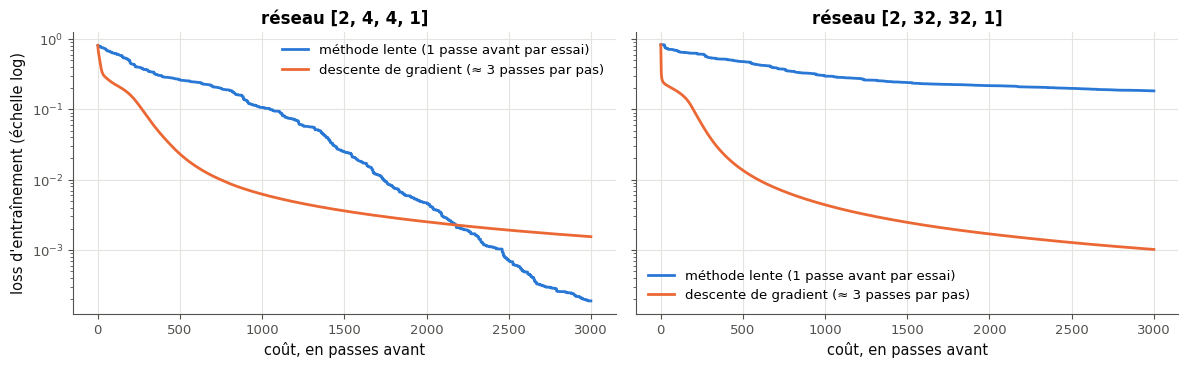

✅ Ex 18.13a : C'est ça !
✅ Ex 18.13b : Parfait !
✅ Ex 18.13c : Bravo !


In [29]:
if any(answer is ... or answer is None for answer in [accepted_13, small_beats_13, ratio_13]):
    print("⏳ Ex 18.13 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    results_13 = {}
    for sizes_13 in (SMALL_13, LARGE_13):
        start_13 = init_13(sizes_13, seed=1813)
        rate_13, slow_curve_13 = slow_method_13(start_13, trials=3000, seed=18131)
        gd_curve_13 = gradient_descent_13(start_13, steps=1000)
        results_13[str(sizes_13)] = (rate_13, slow_curve_13, gd_curve_13)
        print(f"{str(sizes_13):14s} accepted {rate_13:.1%} · loss at start {gd_curve_13[0]:.4f} · slow, 3 000 trials "
              f"{slow_curve_13[-1]:.4f} · 30 gradient steps {gd_curve_13[30]:.4f} · 1 000 gradient steps {gd_curve_13[1000]:.4f}")
    fig_13, axes_13 = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
    for ax, (name_13, (rate_13, slow_curve_13, gd_curve_13)) in zip(axes_13, results_13.items()):
        ax.plot(np.arange(1, 3001), slow_curve_13, label="méthode lente (1 passe avant par essai)")
        ax.plot(3 * np.arange(1001), gd_curve_13, label="descente de gradient (≈ 3 passes par pas)")
        ax.set_yscale("log")
        ax.set_xlabel("coût, en passes avant")
        ax.set_title(f"réseau {name_13}")
        ax.legend()
    axes_13[0].set_ylabel("loss d'entraînement (échelle log)")
    plt.tight_layout()
    plt.show()
    wb.check("18.13a", accepted_13)
    wb.check("18.13b", small_beats_13)
    wb.check("18.13c", ratio_13)

Dans tes notes : compare la part d'essais acceptés à 50 %, et explique l'écart (ou l'accord). Combien d'essais faudrait-il, au moins, pour toucher une fois chacun des 1 185 paramètres du gros réseau, et pour un réseau d'un million de paramètres ? Qu'est-ce qui, dans le coût d'un pas de gradient, ne dépend pas du nombre de paramètres ?

💡 Sur le réseau 2-4-4-1, 36,5 % des essais sont acceptés, pas la moitié : près d'un minimum, la loss monte dans les **deux** sens dès que le pas $m$ est trop grand, et un essai qui part dans le bon sens peut dépasser le creux. Avec seulement 37 paramètres, la méthode lente n'est pas ridicule : après 3 000 essais, sa loss (0,0002) est bien plus basse qu'après 30 pas de gradient (0,238), et même, avec cette graine, qu'après 1 000 pas (0,0015) ; ce dernier point dépend de la graine (sur la graine 1815, c'est l'inverse). Sur le réseau 2-32-32-1, tout change : 3 000 essais touchent chaque paramètre deux ou trois fois seulement, et la loss reste à 0,18, contre 0,0010 après 1 000 pas de gradient, à coût à peu près égal : un rapport de 180 (de 150 à 180 sur cinq graines). Le coût d'un pas de gradient est de trois passes avant **quel que soit** le nombre de paramètres ; celui de la méthode lente grandit avec lui : il faut au moins un essai par paramètre, un million d'essais pour un million de paramètres.

### Ex 18.14 — Cross-entropies calculées sur les logits (binaire et softmax) 🔨 ★★ ⏱️ 30 min
**Objectif :** écrire les deux cross-entropies directement sur les logits, sans débordement, avec leur gradient si simple.  
**Prérequis :** Ex 18.12 · ch. 17 (`sigmoid`, `log_softmax`) · ch. 6 (cross-entropy) · fiche, section sur les losses calculées sur les logits · **Fil rouge :** synth · **mylearn :** `nn/backward.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/backward.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_backward.py -q` les lance tous dans un terminal.

**Contrat commun des losses** (les docstrings, plus ces précisions que vérifient les tests) : chaque loss rend un couple `(loss, grad)`, la loss **moyenne** du batch en un `float` Python, en nats (logarithme népérien), et son gradient par rapport au premier argument dans un **nouveau** tableau `float64` de la même forme ; les entrées (des listes sont acceptées) ne sont jamais modifiées ; **aucune diffusion** entre prédiction et cible : des formes différentes, même `(3,)` contre `(3, 1)`, lèvent `ValueError`.

Écris `binary_cross_entropy_with_logits(logits, y_true)` et `softmax_cross_entropy(logits, y_true)`. **Contrat** propre à ces losses :
- la cross-entropy binaire accepte des logits de forme $(n,)$ ou $(n, 1)$ et des cibles de la même forme, **dans** $[0, 1]$ (une cible hors de cet intervalle lève `ValueError`) ; elle reste finie, sans `RuntimeWarning`, pour des logits de $\pm 1\,000$ ; son gradient vaut $(\sigma(\mathbf{z}) - \mathbf{y})/n$ ;
- la cross-entropy softmax reçoit des logits de forme $(n, K)$ et, au choix, des **labels** entiers de forme $(n,)$ (des flottants entiers comme `2.0` sont acceptés ; un label égal à $K$ ou à $-1$ lève `ValueError`, car NumPy prendrait sans rien dire la dernière colonne pour $-1$) ou des **probabilités cibles** de forme $(n, K)$ (une cible $(1, K)$, qui se diffuserait, est refusée) ; elle reste finie pour des logits de $10^4$ ; son gradient vaut $(\mathbf{P} - \mathbf{Y})/n$, avec $\mathbf{Y}$ le one-hot des labels ou les probabilités données.

Tu peux réutiliser `sigmoid` et `log_softmax` de ton `nn/activations.py` du ch. 17 (`from .activations import sigmoid, log_softmax` ; s'il te manque, la référence le remplace).

La vérification essaie les exemples des docstrings, compare les losses et les gradients à des calculs SciPy, essaie des logits extrêmes et des cibles invalides, puis lance les tests des deux fonctions.

Dans tes notes : pour $z = 40$ et une cible $y = 0$, que donne le calcul naïf $-\log(1 - \sigma(z))$ en `float64` ? Et la forme stable de la fiche ?

In [30]:
if True:
    B = mylearn.nn.backward
    got_14 = pair("18.14", "binary_cross_entropy_with_logits([0, 0], [1, 0])",
                  B.binary_cross_entropy_with_logits([0.0, 0.0], [1.0, 0.0]))
    if got_14 is not None:
        same("18.14", "sa loss (log 2)", got_14[0], np.log(2.0))
        same("18.14", "son gradient", got_14[1], [-0.25, 0.25])
    got_14 = pair("18.14", "softmax_cross_entropy([[0, 0]], [[0.25, 0.75]])",
                  B.softmax_cross_entropy([[0.0, 0.0]], [[0.25, 0.75]]))
    if got_14 is not None:
        same("18.14", "sa loss (log 2)", got_14[0], np.log(2.0))
        same("18.14", "son gradient", got_14[1], [[0.25, -0.25]])
if True:
    B = mylearn.nn.backward
    rng_14 = np.random.default_rng(1814)
    z_14, t_14 = rng_14.normal(size=(5, 1)) * 3, rng_14.random((5, 1))
    got_14 = pair("18.14", "BCE sur 5 logits", B.binary_cross_entropy_with_logits(z_14, t_14))
    if got_14 is not None:
        same("18.14", "loss BCE, comme -mean(t log σ(z) + (1 - t) log(1 - σ(z)))", got_14[0],
             -np.mean(t_14 * special.log_expit(z_14) + (1 - t_14) * special.log_expit(-z_14)))
        same("18.14", "gradient BCE, comme (σ(z) - t) / 5", got_14[1], (special.expit(z_14) - t_14) / 5)
    with warnings.catch_warnings(record=True) as caught_14, np.errstate(over="warn", invalid="warn", divide="warn", under="ignore"):
        warnings.simplefilter("always")
        extreme_14 = pair("18.14", "BCE de logits ±1000", B.binary_cross_entropy_with_logits([1000.0, -1000.0], [0.0, 0.0]))
    if extreme_14 is not None:
        verdict("18.14", np.isfinite(extreme_14[0]) and not caught_14 and abs(extreme_14[0] - 500.0) < 1e-9,
                "BCE de logits ±1000 : 500, finie et sans avertissement.",
                f"BCE de logits ±1000 : {extreme_14[0]!r}" + (f", avertissement « {caught_14[0].message} »" if caught_14 else "")
                + " (attendu 500 : la forme stable de la fiche n'exponentie que -|z|).")
    logits_14, labels_14 = rng_14.normal(size=(6, 4)) * 2, np.array([0, 3, 1, 1, 2, 0])
    got_14 = pair("18.14", "softmax_cross_entropy avec des labels", B.softmax_cross_entropy(logits_14, labels_14))
    if got_14 is not None:
        logp_14 = special.log_softmax(logits_14, axis=1)
        onehot_14 = np.eye(4)[labels_14]
        same("18.14", "loss avec labels, comme -mean(log p[label])", got_14[0], -logp_14[np.arange(6), labels_14].mean())
        same("18.14", "gradient avec labels, comme (P - Y) / 6", got_14[1], (np.exp(logp_14) - onehot_14) / 6)
        again_14 = pair("18.14", "softmax_cross_entropy avec les mêmes labels en one-hot", B.softmax_cross_entropy(logits_14, onehot_14))
        if again_14 is not None:
            same("18.14", "loss avec la cible one-hot (la même)", again_14[0], got_14[0])
    big_14 = pair("18.14", "softmax_cross_entropy de logits 1e4", B.softmax_cross_entropy([[1e4, 0.0, -1e4]], [2]))
    if big_14 is not None:
        verdict("18.14", np.isfinite(big_14[0]) and abs(big_14[0] - 2e4) < 1e-6, "logits de 1e4 : loss 2e4, finie.",
                f"logits de 1e4 : loss {big_14[0]!r}, attendu 2e4 (calcule log p avec log_softmax, jamais log(softmax)).")
    refuses("18.14", "un label égal à -1", lambda: B.softmax_cross_entropy(np.zeros((2, 3)), np.array([0, -1])))
    refuses("18.14", "une cible (1, 3) pour des logits (2, 3)", lambda: B.softmax_cross_entropy(np.zeros((2, 3)), np.full((1, 3), 1 / 3)))
    refuses("18.14", "une cible BCE égale à 1,5", lambda: B.binary_cross_entropy_with_logits([0.0], [1.5]))
if written(lambda: mylearn.nn.backward.binary_cross_entropy_with_logits([0.0], [1.0])):
    run_mylearn_tests(impl="ref", module="backward", keyword="test_binary_cross_entropy or test_softmax_cross_entropy")
else:
    print("⏳ Ex 18.14 : les tests attendent tes fonctions.")

✅ Ex 18.14 : sa loss (log 2) : 0.69314718, comme attendu.
✅ Ex 18.14 : son gradient : [-0.25, 0.25], comme attendu.
✅ Ex 18.14 : sa loss (log 2) : 0.69314718, comme attendu.
✅ Ex 18.14 : son gradient : [[0.25, -0.25]], comme attendu.
✅ Ex 18.14 : loss BCE, comme -mean(t log σ(z) + (1 - t) log(1 - σ(z))) : 2.20861121, comme attendu.
✅ Ex 18.14 : gradient BCE, comme (σ(z) - t) / 5 : [[-0.08762512], [0.0794626], [0.15833033], [0.13620796], [0.16052482]], comme attendu.
✅ Ex 18.14 : BCE de logits ±1000 : 500, finie et sans avertissement.
✅ Ex 18.14 : loss avec labels, comme -mean(log p[label]) : 2.64292574, comme attendu.
✅ Ex 18.14 : gradient avec labels, comme (P - Y) / 6 : un tableau (6, 4), comme attendu.
✅ Ex 18.14 : loss avec la cible one-hot (la même) : 2.64292574, comme attendu.
✅ Ex 18.14 : logits de 1e4 : loss 2e4, finie.
✅ Ex 18.14 : un label égal à -1 : ValueError levée (every label must lie in [0, 3), got values from -1 to 0).
✅ Ex 18.14 : une cible (1, 3) pour des logits (2, 

pytest: 49 passed, 84 deselected in 2.26s


💡 En `float64`, $\sigma(40) = 1 - 4{,}2 \times 10^{-18}$ s'arrondit à 1 exactement : $1 - \sigma(40) = 0$ et $-\log 0 = +\infty$ (avec un `RuntimeWarning` « divide by zero »). La forme stable $\max(z, 0) - y\,z + \log(1 + e^{-|z|})$ donne $40 + \log(1 + e^{-40}) \approx 40$, la bonne valeur. C'est le même principe que `log_softmax` : on ne calcule jamais une probabilité pour en prendre le logarithme ensuite.

### Ex 18.15 — dense_backward : les trois gradients d'une couche 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire la passe arrière d'une couche dense pour un mini-batch, et la vérifier contre des différences finies.  
**Prérequis :** Ex 18.12 · ch. 16 (`dense_forward`, formes) · fiche §18.7, §18.8, §18.12.1, encadré sur les gradients matriciels · **Fil rouge :** synth · **mylearn :** `nn/backward.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/backward.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_backward.py -q` les lance tous dans un terminal.

Écris `dense_backward(dout, x, W)`, la passe arrière de la couche $\mathbf{z} = \mathbf{x}\mathbf{W} + \mathbf{b}$ : elle reçoit `dout` $= \partial L / \partial \mathbf{z}$, de forme $(n, n_{out})$, l'entrée `x` de forme $(n, n_{in})$ et les poids `W` de forme $(n_{in}, n_{out})$, et rend le tuple `(dx, dW, db)` des gradients de la loss par rapport à l'entrée, aux poids et au biais. **Contrat** (la docstring, plus ces précisions que vérifient les tests) : trois **nouveaux** tableaux `float64`, de formes $(n, n_{in})$, $(n_{in}, n_{out})$ et $(n_{out},)$ ; le biais n'est pas un argument (son gradient n'en dépend pas) ; des tableaux qui ne sont pas à deux dimensions ou dont les formes ne s'accordent pas lèvent `ValueError` ; aucune entrée n'est modifiée. Pas de $\frac{1}{n}$ ici : la moyenne du batch est déjà dans `dout`, rendu par la loss.

La vérification essaie l'exemple de la docstring, compare tes trois gradients à des différences finies centrées d'une loss $L = \sum \mathbf{G} \odot \mathbf{z}$ (dont le gradient en $\mathbf{z}$ vaut exactement $\mathbf{G}$), essaie des formes incompatibles, puis lance les tests (`-k test_dense_backward_`).

Dans tes notes : pour $n = 5$, $n_{in} = 3$ et $n_{out} = 4$, écris les formes des six tableaux en jeu, et montre qu'il n'y a qu'une seule façon de les multiplier pour obtenir `dW` et `dx`.

In [31]:
def triple_15(ex_id, result):
    """Unpack (dx, dW, db), or None with a ❌ line."""
    if result is None:
        print(f"❌ Ex {ex_id} : dense_backward renvoie None : as-tu oublié le return ?")
        return None
    if not isinstance(result, tuple) or len(result) != 3:
        print(f"❌ Ex {ex_id} : dense_backward doit rendre un tuple (dx, dW, db), reçu {type(result).__name__}.")
        return None
    return result


if True:
    B = mylearn.nn.backward
    got_15 = triple_15("18.15", B.dense_backward(np.array([[1.0, -1.0]]), np.array([[1.0, 2.0]]),
                                                  np.array([[1.0, 0.0], [0.0, 1.0]])))
    if got_15 is not None:
        same("18.15", "dx de l'exemple de la docstring", got_15[0], [[1.0, -1.0]])
        same("18.15", "dW de l'exemple de la docstring", got_15[1], [[1.0, -1.0], [2.0, -2.0]])
        same("18.15", "db de l'exemple de la docstring", got_15[2], [1.0, -1.0])
if True:
    B = mylearn.nn.backward
    rng_15 = np.random.default_rng(1815)
    x_15, W_15, b_15 = rng_15.normal(size=(5, 3)), rng_15.normal(size=(3, 4)), rng_15.normal(size=4)
    G_15 = rng_15.normal(size=(5, 4))                 # the gradient that arrives on z

    def loss_15():
        return float(np.sum(G_15 * (x_15 @ W_15 + b_15)))   # a loss whose gradient on z is exactly G_15

    got_15 = triple_15("18.15", B.dense_backward(G_15.copy(), x_15.copy(), W_15.copy()))
    if got_15 is not None:
        same("18.15", "dx contre les différences finies", got_15[0], numeric_grad(loss_15, x_15), rtol=1e-6, atol=1e-8)
        same("18.15", "dW contre les différences finies", got_15[1], numeric_grad(loss_15, W_15), rtol=1e-6, atol=1e-8)
        same("18.15", "db contre les différences finies", got_15[2], numeric_grad(loss_15, b_15), rtol=1e-6, atol=1e-8)
    refuses("18.15", "dout (5, 4) avec x (6, 3)", lambda: B.dense_backward(G_15, np.zeros((6, 3)), W_15))
if written(lambda: mylearn.nn.backward.dense_backward(np.ones((1, 1)), np.ones((1, 1)), np.ones((1, 1)))):
    run_mylearn_tests(impl="ref", module="backward", keyword="test_dense_backward_")
else:
    print("⏳ Ex 18.15 : les tests attendent ta fonction.")

✅ Ex 18.15 : dx de l'exemple de la docstring : [[1.0, -1.0]], comme attendu.
✅ Ex 18.15 : dW de l'exemple de la docstring : [[1.0, -1.0], [2.0, -2.0]], comme attendu.
✅ Ex 18.15 : db de l'exemple de la docstring : [1.0, -1.0], comme attendu.
✅ Ex 18.15 : dx contre les différences finies : un tableau (5, 3), comme attendu.
✅ Ex 18.15 : dW contre les différences finies : un tableau (3, 4), comme attendu.
✅ Ex 18.15 : db contre les différences finies : [4.57382669, -0.58148345, 5.77364509, -1.01612162], comme attendu.
✅ Ex 18.15 : dout (5, 4) avec x (6, 3) : ValueError levée (x has 6 rows but dout has 5: one row per sample in both).


pytest: 15 passed, 118 deselected in 2.47s


💡 `dW` doit avoir la forme $(3, 4)$ de `W` : à partir de `x` $(5, 3)$ et `dout` $(5, 4)$, le seul produit qui fait disparaître la dimension 5 des exemples est `x.T @ dout` $(3, 5) \times (5, 4)$. `dx` doit avoir la forme $(5, 3)$ de `x` : `dout @ W.T`, $(5, 4) \times (4, 3)$. `db`, de forme $(4,)$, est la somme des lignes de `dout`. La règle « le gradient a la forme du tableau » retrouve les trois formules.

### Ex 18.16 — gradient_check : vérifier un gradient par différences finies 🔨 ★★ ⏱️ 25 min
**Objectif :** écrire l'outil qui compare un gradient analytique aux différences finies centrées, sans abîmer les paramètres.  
**Prérequis :** Ex 18.15 · ch. 5 (dérivée numérique, choix du pas) · fiche, section sur la vérification d'un gradient · **Fil rouge :** synth · **mylearn :** `nn/backward.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/backward.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_backward.py -q` les lance tous dans un terminal.

Écris `gradient_check(f, param, analytic_grad, eps=1e-6, n_checks=None, rng=None)` : `f` est une fonction **sans argument** qui recalcule la loss en lisant `param` ; `gradient_check` modifie `param` **sur place**, une case à la fois, et rend la plus grande erreur relative $|a - n| / \max(|a| + |n|, 10^{-12})$ entre le gradient analytique $a$ et le gradient numérique $n$ des cases vérifiées. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- différence **centrée**, avec le pas `eps` donné : $n = \frac{f(w + \varepsilon) - f(w - \varepsilon)}{2\varepsilon}$, une seule case perturbée à la fois ;
- chaque case est remise **bit à bit** à sa valeur d'origine (garde l'ancienne valeur et remets-la : `old + eps - eps` n'est pas toujours `old`), même si `f` lève une erreur ;
- avec `n_checks=None`, toutes les cases ; sinon `n_checks` cases **distinctes** tirées par `np.random.default_rng(rng)` (sans remise), ou toutes s'il y en a moins ;
- `param` doit être un tableau NumPy de **flottants** (sinon `ValueError` : une case entière ne peut pas recevoir $w + 10^{-6}$), et `analytic_grad` doit avoir sa forme (sinon `ValueError`) ;
- la valeur rendue est un `float` Python.

La vérification essaie les exemples de la docstring, vérifie le gradient exact d'une couche dense, puis le même gradient multiplié par 2, contrôle que `param` revient bit à bit, puis lance les tests (`-k test_gradient_check_`).

Dans tes notes : pourquoi un gradient deux fois trop grand donne-t-il **exactement** $\frac13$, quelles que soient les valeurs ? Et un signe faux ?

In [32]:
if True:
    B = mylearn.nn.backward
    w_16 = np.array([1.0, -2.0, 3.0])
    err_16 = B.gradient_check(lambda: float(np.sum(w_16 ** 2)), w_16, 2 * w_16)
    if not isinstance(err_16, float):
        print(f"❌ Ex 18.16 : gradient_check doit rendre un float Python, reçu {type(err_16).__name__} (convertis avec float(...)).")
    else:
        verdict("18.16", err_16 < 1e-7, f"gradient juste de Σw² : erreur relative {err_16:.1e} (< 1e-7).",
                f"gradient juste de Σw² : erreur relative {err_16:.3g}, attendu moins de 1e-7.")
        err_16 = float(B.gradient_check(lambda: float(np.sum(w_16 ** 2)), w_16, -2 * w_16))
        verdict("18.16", err_16 > 0.9, f"signe faux : erreur relative {err_16:.3f} (proche de 1).",
                f"signe faux : erreur relative {err_16:.3g}, attendu une valeur proche de 1.")
    gap_16 = float(np.max(np.abs(w_16 - np.array([1.0, -2.0, 3.0]))))
    verdict("18.16", w_16.tobytes() == np.array([1.0, -2.0, 3.0]).tobytes(), "w remis bit à bit après les deux vérifications.",
            f"w n'est pas remis bit à bit (plus grand écart {gap_16:.1e}) : garde l'ancienne valeur et remets-la (jamais old + eps − eps).")
if True:
    B = mylearn.nn.backward
    rng_16 = np.random.default_rng(1816)
    x_16, W_16, G_16 = rng_16.normal(size=(5, 3)), rng_16.normal(size=(3, 4)), rng_16.normal(size=(5, 4))
    loss_16 = lambda: float(np.sum(G_16 * (x_16 @ W_16)))          # dL/dW = x.T @ G
    exact_16 = x_16.T @ G_16
    saved_16 = W_16.copy()
    err_16 = float(B.gradient_check(loss_16, W_16, exact_16))
    verdict("18.16", err_16 < 1e-7, f"dW exact d'une couche dense : erreur relative {err_16:.1e}.",
            f"dW exact d'une couche dense : erreur relative {err_16:.3g}, attendu moins de 1e-7.")
    err_16 = float(B.gradient_check(loss_16, W_16, 2 * exact_16))
    verdict("18.16", abs(err_16 - 1 / 3) < 1e-6, f"facteur 2 en trop : erreur relative {err_16:.4f} (1/3).",
            f"facteur 2 en trop : erreur relative {err_16:.4g}, attendu 1/3 : |2g − g| / (|2g| + |g|).")
    err_16 = float(B.gradient_check(loss_16, W_16, exact_16, n_checks=3, rng=np.random.default_rng(0)))
    verdict("18.16", err_16 < 1e-7, "n_checks=3 avec un générateur : accepté.", f"n_checks=3 : erreur {err_16!r}.")
    verdict("18.16", W_16.tobytes() == saved_16.tobytes(), "W remis bit à bit après toutes les vérifications.",
            "W n'est pas remis bit à bit : garde l'ancienne valeur et remets-la (jamais old + eps − eps).")
    refuses("18.16", "un param d'entiers", lambda: B.gradient_check(lambda: 0.0, np.array([1, 2]), np.array([0.0, 0.0])))
if written(lambda: mylearn.nn.backward.gradient_check(lambda: 0.0, np.zeros(1), np.zeros(1))):
    run_mylearn_tests(impl="ref", module="backward", keyword="test_gradient_check_")
else:
    print("⏳ Ex 18.16 : les tests attendent ta fonction.")

✅ Ex 18.16 : gradient juste de Σw² : erreur relative 7.0e-11 (< 1e-7).
✅ Ex 18.16 : signe faux : erreur relative 1.000 (proche de 1).
✅ Ex 18.16 : w remis bit à bit après les deux vérifications.
✅ Ex 18.16 : dW exact d'une couche dense : erreur relative 1.7e-09.
✅ Ex 18.16 : facteur 2 en trop : erreur relative 0.3333 (1/3).
✅ Ex 18.16 : n_checks=3 avec un générateur : accepté.
✅ Ex 18.16 : W remis bit à bit après toutes les vérifications.
✅ Ex 18.16 : un param d'entiers : ValueError levée (param must be a NumPy array of floats (it is modified in place)).


pytest: 17 passed, 116 deselected in 2.25s


💡 Pour $a = 2n$ : $\frac{|2n - n|}{|2n| + |n|} = \frac{|n|}{3|n|} = \frac13$, quel que soit $n \ne 0$. Pour un signe faux, $a = -n$ : $\frac{|{-n} - n|}{|n| + |n|} = 1$. L'erreur relative ne dépend que du **rapport** $a/n$ : c'est ce qui la rend lisible d'un réseau à l'autre, et ce qui permet de reconnaître un facteur oublié à sa valeur ($\frac{k - 1}{k + 1}$ pour un facteur $k$).

### Ex 18.17 — Chasse au bug : trois gradients faux démasqués 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver, avec ton gradient_check, trois erreurs dans la passe arrière d'un petit réseau qui tourne sans planter.  
**Prérequis :** Ex 18.16 · fiche §18.10, §18.12.5, section sur la vérification d'un gradient · **Parcours :** C

Un collègue a écrit `grads_17`, la passe arrière d'un petit réseau (4 entrées, 5 neurones cachés tanh, 3 classes, cross-entropy softmax **moyenne** sur 6 exemples). Elle tourne, rend des tableaux de la bonne forme, et l'entraînement « marche à peu près » : il y a pourtant **trois** erreurs.

a) Avec **ton** `gradient_check` (Ex 18.16), mesure l'erreur relative de son `dW2` (la fonction d'origine) : perturbe `W2` d'une copie de `PARAMS_17`, et recalcule `loss_17`. Range la valeur, sans l'arrondir, dans `err_17`.

b) Écris `grads_fixed_17`, la version corrigée (copie le code, puis corrige-le ; même signature, mêmes formes). Ton `gradient_check` sur chacun des quatre gradients est le meilleur guide.

La vérification contrôle trois points, dans l'ordre où les erreurs se masquent (un point ne se teste que si les précédents passent) : 1) `dW2` et `db2` ; 2) `dW1` ; 3) `db1`, chacun contre des différences finies calculées indépendamment de ton code. Cet exercice se corrige aussi avec `05_solutions.md`.

Dans tes notes : pour chaque erreur, l'erreur relative qu'elle produit et pourquoi elle a cette valeur ; laquelle de ces erreurs l'entraînement aurait-il le plus de mal à « absorber » ?

In [33]:
rng_17 = np.random.default_rng(1817)
X_17 = rng_17.normal(size=(6, 4))                    # 6 examples, 4 features
LABELS_17 = np.array([0, 2, 1, 1, 0, 2])             # 3 classes
PARAMS_17 = [(rng_17.normal(0, 0.5, size=(4, 5)), rng_17.normal(0, 0.1, size=5)),   # hidden layer, tanh
             (rng_17.normal(0, 0.5, size=(5, 3)), rng_17.normal(0, 0.1, size=3))]   # output layer, logits


def loss_17(params):
    """Mean softmax cross-entropy of the network tanh(x W1 + b1) W2 + b2 on (X_17, LABELS_17)."""
    (W1, b1), (W2, b2) = params
    logits = np.tanh(X_17 @ W1 + b1) @ W2 + b2
    return float(-special.log_softmax(logits, axis=1)[np.arange(len(X_17)), LABELS_17].mean())


def grads_17(params):
    """A colleague's backward pass for loss_17: returns [(dW1, db1), (dW2, db2)]. It runs, but some gradients are wrong."""
    (W1, b1), (W2, b2) = params
    n = len(X_17)
    z1 = X_17 @ W1 + b1
    a1 = np.tanh(z1)
    logits = a1 @ W2 + b2
    P = special.softmax(logits, axis=1)
    Y = np.eye(3)[LABELS_17]
    delta2 = P - Y
    dW2, db2 = a1.T @ delta2, delta2.sum(axis=0)
    delta1 = (delta2 @ W2.T) * (1 - np.tanh(a1) ** 2)
    dW1, db1 = X_17.T @ delta1, delta1.mean(axis=0)
    return [(dW1, db1), (dW2, db2)]

In [34]:
B = mylearn.nn.backward
check_params_17 = [(W.copy(), b.copy()) for W, b in PARAMS_17]
err_17 = B.gradient_check(lambda: loss_17(check_params_17), check_params_17[1][0], grads_17(check_params_17)[1][0])
print("relative error of the colleague's dW2:", err_17)


def grads_fixed_17(params):
    """The corrected backward pass: copy the code of grads_17 here, then fix it (same signature, same result shape)."""
    (W1, b1), (W2, b2) = params
    n = len(X_17)
    z1 = X_17 @ W1 + b1
    a1 = np.tanh(z1)
    logits = a1 @ W2 + b2
    P = special.softmax(logits, axis=1)
    Y = np.eye(3)[LABELS_17]
    delta2 = (P - Y) / n                              # 1) the loss is a MEAN: the 1/n belongs to delta2
    dW2, db2 = a1.T @ delta2, delta2.sum(axis=0)
    delta1 = (delta2 @ W2.T) * (1 - a1 ** 2)          # 2) tanh'(z1) = 1 - tanh(z1)**2 = 1 - a1**2, not 1 - tanh(a1)**2
    dW1, db1 = X_17.T @ delta1, delta1.sum(axis=0)    # 3) the gradient of a bias is the SUM of its deltas
    return [(dW1, db1), (dW2, db2)]
def oracle_17(params):
    """The exact gradients of loss_17, by central differences (this check does not use your gradient_check)."""
    copy = [(W.copy(), b.copy()) for W, b in params]
    return [tuple(numeric_grad(lambda: loss_17(copy), array) for array in layer) for layer in copy]


EXACT_17 = oracle_17(PARAMS_17)
with wb.attempt("18.17"):
    print_answer("18.17a", err_17)
with checked("18.17"):
    got_17 = grads_fixed_17([(W.copy(), b.copy()) for W, b in PARAMS_17])
    shapes_17 = [[np.shape(g) for g in layer] for layer in got_17] if isinstance(got_17, (list, tuple)) else None
    if shapes_17 != [[(4, 5), (5,)], [(5, 3), (3,)]]:
        print(f"❌ Ex 18.17 : grads_fixed_17 doit rendre [(dW1, db1), (dW2, db2)] de formes [(4, 5), (5,)], [(5, 3), (3,)] ; "
              f"reçu {shapes_17 if shapes_17 is not None else type(got_17).__name__}.")
    else:
        points_17 = [("1) dW2 et db2 (la couche de sortie)", [got_17[1][0], got_17[1][1]], [EXACT_17[1][0], EXACT_17[1][1]]),
                     ("2) dW1 (la couche cachée)", [got_17[0][0]], [EXACT_17[0][0]]),
                     ("3) db1 (les biais cachés)", [got_17[0][1]], [EXACT_17[0][1]])]
        for k_17, (label_17, mine_17, exact_17) in enumerate(points_17):
            worst_17 = max(relative_error(m, e) for m, e in zip(mine_17, exact_17))
            if worst_17 >= 1e-6:
                print(f"❌ Ex 18.17 : point {label_17} : erreur relative {worst_17:.3g} contre les différences finies. "
                      "Mesure-la avec ton gradient_check, puis cherche la ligne qui la produit.")
                for later_17 in points_17[k_17 + 1:]:
                    print(f"⏳ Ex 18.17 : point {later_17[0]} : corrige d'abord le point {label_17[:2]}")
                break
            print(f"✅ Ex 18.17 : point {label_17} : juste (erreur relative {worst_17:.1e}).")

relative error of the colleague's dW2: 0.7142857158384845
18.17a: 0.7142857158384845
✅ Ex 18.17 : point 1) dW2 et db2 (la couche de sortie) : juste (erreur relative 5.3e-08).
✅ Ex 18.17 : point 2) dW1 (la couche cachée) : juste (erreur relative 4.5e-09).
✅ Ex 18.17 : point 3) db1 (les biais cachés) : juste (erreur relative 2.6e-09).


In [35]:
wb.record("18.17a", err_17, decimals=4, mistakes={"c'est l'erreur relative de db1 : la question porte sur dW2, en perturbant W2": float(relative_error(grads_17(PARAMS_17)[0][1], EXACT_17[0][1])),
                                   "c'est l'erreur relative de dW1 : la question porte sur dW2, en perturbant W2": float(relative_error(grads_17(PARAMS_17)[0][0], EXACT_17[0][0])),
                                   "c'est l'erreur d'un gradient juste : la question porte sur le dW2 du collègue (grads_17, avant correction)": 0.0})

WB_ANSWER {"decimals": 4, "hash": "c28045f239a4ba63f1aad104cce3fa690592c04d973e9864a978c512e00104b8", "hash_coarse": "0ee9f5a40ce5663b1fe27e4c9492cdd4a1d8156878efde1ac722d4e3b644bce6", "id": "18.17a", "kind": "float", "magnitude": -1, "mistakes": {"0353a31035318fb9c92f49465edc0528605ccb2abc0be32a0f83b7aed206df3a": "c'est l'erreur relative de db1 : la question porte sur dW2, en perturbant W2", "5a1fa21f9c633640ed4e1b00ad88e1e13e565ea854f7ce267ad9397463153597": "c'est l'erreur d'un gradient juste : la question porte sur le dW2 du collègue (grads_17, avant correction)", "a259e80fedc854628f05979a6a436fc35ef1857bb5258de4e89c05410fbfe59a": "c'est l'erreur relative de dW1 : la question porte sur dW2, en perturbant W2"}, "sign": 1}
📝 Ex 18.17a : réponse enregistrée (float, 4 décimale(s)).


💡 Les trois erreurs : `delta2 = P - Y` oublie le $\frac{1}{n}$ de la loss **moyenne** : tous les gradients sont 6 fois trop grands, et l'erreur relative de `dW2` vaut exactement $\frac{6 - 1}{6 + 1} = \frac57 \approx 0{,}7143$ ; `1 - np.tanh(a1) ** 2` prend la dérivée en la **sortie** $a_1 = \tanh(z_1)$, au lieu de $1 - a_1^2$ ; `delta1.mean(axis=0)` divise une seconde fois par $n$ le gradient du biais, qui est la **somme** des deltas. La première est la plus « absorbable » : elle ne change que l'échelle du gradient, comme un learning rate 6 fois plus grand ; les deux autres changent sa direction.

## Partie B · Rétropropager tout un réseau, puis l'entraîner

Écrire la rétropropagation de tout un MLP (18.18), puis entraîner le réseau 2-4-4-1 du livre sur les lunes avec trois learning rates (18.19), refaire l'expérience avec scikit-learn (18.20) et tracer ce que le livre montre dans ses figures 18.49 à 18.57 (18.21). La cellule suivante crée les 1 500 lunes standardisées et fixe le nombre d'epochs.

In [36]:
X_MOONS, y_MOONS = moons_18()                     # the 1 500 standardized moons of the book's experiment
EPOCHS_19 = 40
print("moons:", X_MOONS.shape, "· classes:", np.bincount(y_MOONS).tolist())

moons: (1500, 2) · classes: [750, 750]


### Ex 18.18 — mlp_backward : rétropropager à travers tout le réseau 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire la passe arrière d'un MLP entier à partir du cache de sa passe avant.  
**Prérequis :** Ex 18.15 · ch. 16 (`mlp_forward` et son cache) · ch. 17 (dérivées en $z$) · fiche §18.8 à §18.10, §18.12.1 · **Fil rouge :** synth · **mylearn :** `nn/backward.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/nn/backward.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_backward.py -q` les lance tous dans un terminal.

Écris `mlp_backward(dout, cache, params, activation_derivative=None, output_activation_derivative=None, return_input_grad=False)`. Elle reçoit `dout` $= \partial L / \partial$ (sortie du réseau), de forme $(n, n_L)$ (le gradient rendu par une loss calculée sur les logits), le `cache` de ton `mlp_forward(..., return_cache=True)` du ch. 16 (un couple `(a_prev, z)` par couche) et la liste `params` des `(W, b)` de la passe avant. **Contrat** (la docstring, plus ces précisions que vérifient les tests) :
- elle rend la liste des `(dW, db)`, dans l'ordre et avec les formes de `params` ; avec `return_input_grad=True`, le tuple `(grads, dx)`, `dx` ayant la forme de l'entrée du réseau ;
- les dérivées sont celles du ch. 17, qui prennent la **pré-activation** : `activation_derivative` est appelée **une fois par couche cachée**, sur le `z` du cache ; `output_activation_derivative` s'applique au `z` de la dernière couche (`None` : sortie linéaire, le cas d'une loss sur les logits) ; `None` pour l'une ou l'autre veut dire l'identité ;
- `dout`, le cache et les paramètres ne sont jamais modifiés (calcule `delta = grad * f'(z)` dans un nouveau tableau, jamais avec `*=`) ;
- un cache et des paramètres de longueurs différentes, ou un `dout` de la mauvaise forme, lèvent `ValueError`.

La vérification essaie l'exemple de la docstring, compare tous les gradients d'un réseau 3-5-4-2 (tanh cachées, sortie sigmoïde) à des différences finies, compte les appels de la dérivée cachée, puis lance les tests (`-k test_mlp_backward_`).

Dans tes notes : pourquoi la dérivée doit-elle être évaluée en $z$ (gardé par le cache) et non en $a$ ? Que changerait un `*=` sur `dout` pour l'appelant ?

In [37]:
def grads_of_18(ex_id, result, params, with_dx=False):
    """Unpack the result of mlp_backward (a list of (dW, db), or (grads, dx)), or None with a ❌ line."""
    if result is None:
        print(f"❌ Ex {ex_id} : mlp_backward renvoie None : as-tu oublié le return ?")
        return None
    if with_dx:
        if not isinstance(result, tuple) or len(result) != 2:
            print(f"❌ Ex {ex_id} : avec return_input_grad=True, mlp_backward doit rendre le tuple (grads, dx).")
            return None
        result = result[0]
    if not isinstance(result, list) or len(result) != len(params) or not all(isinstance(g, tuple) and len(g) == 2 for g in result):
        inner = f"une liste de {type(result[0]).__name__}" if isinstance(result, list) and result else type(result).__name__
        print(f"❌ Ex {ex_id} : mlp_backward doit rendre une liste de {len(params)} tuples (dW, db), reçu {inner}.")
        return None
    return result


if True:
    B = mylearn.nn.backward
    x_18 = np.array([[1.0, 1.0]])
    params_18 = [(np.array([[1.0, -1.0], [0.5, -2.0]]), np.array([0.0, 1.0])), (np.array([[2.0], [1.0]]), np.array([0.5]))]
    cache_18 = [(x_18, np.array([[1.5, -2.0]])), (np.array([[1.5, 0.0]]), np.array([[3.5]]))]
    relu_derivative_18 = lambda z: (z > 0).astype(float)
    result_18 = B.mlp_backward(np.array([[1.0]]), cache_18, params_18, activation_derivative=relu_derivative_18,
                               return_input_grad=True)
    grads_18 = grads_of_18("18.18", result_18, params_18, with_dx=True)
    if grads_18 is not None:
        same("18.18", "dW de la couche 0 (exemple de la docstring)", grads_18[0][0], [[2.0, 0.0], [2.0, 0.0]])
        same("18.18", "dW de la couche 1", grads_18[1][0], [[1.5], [0.0]])
        same("18.18", "dx", result_18[1], [[2.0, 1.0]])
if True:
    B = mylearn.nn.backward
    rng_18 = np.random.default_rng(1818)
    sizes_18 = [3, 5, 4, 2]
    params_18 = [(rng_18.normal(0, 0.7, (a, b)), rng_18.normal(0, 0.3, b)) for a, b in zip(sizes_18[:-1], sizes_18[1:])]
    x_18, G_18 = rng_18.normal(size=(6, 3)), rng_18.normal(size=(6, 2))

    def forward_18(params, x):
        """Our own forward pass: tanh hidden layers, sigmoid output; returns (output, cache in the mlp_forward format)."""
        a, cache = x, []
        for layer, (W, b) in enumerate(params):
            z = a @ W + b
            cache.append((a, z))
            a = np.tanh(z) if layer < len(params) - 1 else special.expit(z)
        return a, cache

    def loss_18():
        return float(np.sum(G_18 * forward_18(params_18, x_18)[0]))     # dL/d(output) = G_18

    _, cache_18 = forward_18(params_18, x_18)
    calls_18 = []

    def tanh_derivative_18(z):
        calls_18.append(z)
        return 1 - np.tanh(z) ** 2

    sigmoid_derivative_18 = lambda z: special.expit(z) * (1 - special.expit(z))
    result_18 = B.mlp_backward(G_18.copy(), cache_18, params_18, activation_derivative=tanh_derivative_18,
                               output_activation_derivative=sigmoid_derivative_18, return_input_grad=True)
    grads_18 = grads_of_18("18.18", result_18, params_18, with_dx=True)
    if grads_18 is not None:
        for layer_18, ((W_18, b_18), (dW_18, db_18)) in enumerate(zip(params_18, grads_18)):
            same("18.18", f"dW de la couche {layer_18} (tanh cachées, sortie sigmoïde) contre les différences finies", dW_18,
                 numeric_grad(loss_18, W_18), rtol=1e-6, atol=1e-8)
            same("18.18", f"db de la couche {layer_18} contre les différences finies", db_18, numeric_grad(loss_18, b_18),
                 rtol=1e-6, atol=1e-8)
        same("18.18", "dx contre les différences finies", result_18[1], numeric_grad(loss_18, x_18), rtol=1e-6, atol=1e-8)
        hidden_z_18 = [z for _, z in cache_18[:-1]]
        on_z_18 = all(any(c is z or np.array_equal(c, z) for c in calls_18) for z in hidden_z_18) and all(
            any(c is z or np.array_equal(c, z) for z in hidden_z_18) for c in calls_18)
        if len(calls_18) != 2:
            print(f"❌ Ex 18.18 : la dérivée cachée a été appelée {len(calls_18)} fois au lieu de 2 (une fois par couche cachée).")
        verdict("18.18", on_z_18, "la dérivée cachée est appelée sur le z du cache de chaque couche cachée.",
                "la dérivée cachée a été appelée sur autre chose que le z du cache (la sortie a de la couche ?).")
if written(lambda: mylearn.nn.backward.mlp_backward(np.ones((1, 1)), [(np.ones((1, 1)), np.ones((1, 1)))], [(np.ones((1, 1)), np.ones(1))])):
    run_mylearn_tests(impl="ref", module="backward", keyword="test_mlp_backward_")
else:
    print("⏳ Ex 18.18 : les tests attendent ta fonction.")

✅ Ex 18.18 : dW de la couche 0 (exemple de la docstring) : [[2.0, 0.0], [2.0, 0.0]], comme attendu.
✅ Ex 18.18 : dW de la couche 1 : [[1.5], [0.0]], comme attendu.
✅ Ex 18.18 : dx : [[2.0, 1.0]], comme attendu.
✅ Ex 18.18 : dW de la couche 0 (tanh cachées, sortie sigmoïde) contre les différences finies : un tableau (3, 5), comme attendu.
✅ Ex 18.18 : db de la couche 0 contre les différences finies : [-0.06529257, 0.85038382, 0.22632417, -0.21818071, -0.38471645], comme attendu.
✅ Ex 18.18 : dW de la couche 1 (tanh cachées, sortie sigmoïde) contre les différences finies : un tableau (5, 4), comme attendu.
✅ Ex 18.18 : db de la couche 1 contre les différences finies : [0.23770259, -0.58126312, -0.19371847, -0.19028186], comme attendu.
✅ Ex 18.18 : dW de la couche 2 (tanh cachées, sortie sigmoïde) contre les différences finies : un tableau (4, 2), comme attendu.
✅ Ex 18.18 : db de la couche 2 contre les différences finies : [0.27971301, -0.22851695], comme attendu.
✅ Ex 18.18 : dx contre 

pytest: 34 passed, 99 deselected in 2.79s


💡 Les dérivées du ch. 17 sont des fonctions de $z$ : `tanh_derivative(a)` calculerait $1 - \tanh^2(\tanh z)$, un nombre plausible (entre 0 et 1) mais faux, sans aucune erreur ; c'est pourquoi le cache garde $z$. Un `delta *= f'(z)` sur `dout` modifierait le tableau de l'appelant, qui le réutilise parfois (pour un second calcul, un affichage ou une vérification) : la boucle d'entraînement suivante partirait d'un gradient déjà multiplié.

### Ex 18.19 — Entraîner le réseau 2-4-4-1 à 37 poids sur les lunes 🔨 ★★★ ⏱️ 45 min
**Objectif :** écrire la boucle d'entraînement du livre avec ta librairie, et la lancer avec trois learning rates.  
**Prérequis :** Ex 18.18 · Ex 18.14 · ch. 16 (`init_mlp`, `mlp_forward`) · 0A (`iterate_minibatches`) · fiche §18.9, §18.11.1, §18.12.5 · **Fil rouge :** synth · **Parcours :** R, C

Le réseau du livre (§18.11.1) : 2 entrées, deux couches cachées de 4 neurones ReLU, une sortie linéaire, le **logit** ; 28 poids et 9 biais. Écris `train_19(X, y, lr, epochs, seed=0, batch_size=1)`, qui l'entraîne avec **ta** librairie. **Contrat** (le protocole est imposé, pour que tes nombres soient ceux de la vérification) :
- un seul générateur, `rng = np.random.default_rng(seed)`, crée d'abord les poids par `init_mlp([2, 4, 4, 1], "he_normal", rng)` (ch. 16), puis mélange les exemples à chaque epoch par `iterate_minibatches(len(X), batch_size, rng=rng)` (0A) ;
- pour chaque mini-batch : `mlp_forward` avec `relu` (ch. 17), la cross-entropy binaire **sur les logits** (Ex 18.14) contre les labels mis en colonne `(n, 1)`, `mlp_backward` avec `relu_derivative` (Ex 18.18), puis la mise à jour $\mathbf{W} \leftarrow \mathbf{W} - \eta\,d\mathbf{W}$, $\mathbf{b} \leftarrow \mathbf{b} - \eta\,d\mathbf{b}$ de toutes les couches ;
- avec `batch_size=1`, c'est la descente de gradient **stochastique** du livre : une mise à jour par exemple ;
- après chaque epoch, sur **tout** `(X, y)` : la loss moyenne, l'accuracy (logit $> 0$ ⇒ classe 1) et les 5 paramètres de la couche de sortie (ses 4 poids, puis son biais), dans le dictionnaire `history` décrit par la docstring.

La vérification entraîne le réseau 40 epochs avec $\eta = 0{,}5$, $0{,}05$ et $0{,}01$ (une vingtaine de secondes), garde les trois entraînements dans `RUNS_19` pour 18.20 et 18.21, puis vérifie quatre valeurs calculées par ton code : a) l'accuracy après la première epoch avec $\eta = 0{,}05$ ; b) la loss après la première epoch avec $\eta = 0{,}01$ ; c) la même avec $\eta = 0{,}05$ ; d) la loss après les 40 epochs avec $\eta = 0{,}05$.

Dans tes notes : compare les trois entraînements à ce que décrit la fiche (§18.11.1). Quels phénomènes retrouves-tu ? Lesquels tes chiffres changent-ils ?

In [38]:
from mylearn.nn.activations import relu, relu_derivative
from mylearn.nn.backward import binary_cross_entropy_with_logits, mlp_backward
from mylearn.nn.layers import init_mlp, mlp_forward
from mylearn.utils import iterate_minibatches


def train_19(X, y, lr, epochs, seed=0, batch_size=1):
    """Train the 2-4-4-1 network of the book (ReLU hidden layers, a linear output: the logit) by stochastic gradient
    descent on the binary cross-entropy of the logits, with the protocol of the statement.

    Returns (params, history): params = the trained [(W, b), (W, b), (W, b)]; history = a dict of three lists, one
    entry per epoch, measured on all of (X, y) after the epoch: "loss" (floats), "accuracy" (floats) and
    "output_layer" (arrays of shape (5,): the 4 weights of the output layer, then its bias).
    """
    rng = np.random.default_rng(seed)
    params = init_mlp([2, 4, 4, 1], "he_normal", rng)
    target = y.reshape(-1, 1).astype(float)                  # (n, 1), like the logits
    history = {"loss": [], "accuracy": [], "output_layer": []}
    for _ in range(epochs):
        for idx in iterate_minibatches(len(X), batch_size, rng=rng):
            logits, cache = mlp_forward(X[idx], params, relu, None, return_cache=True)
            _, dout = binary_cross_entropy_with_logits(logits, target[idx])
            grads = mlp_backward(dout, cache, params, activation_derivative=relu_derivative)
            params = [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)]
        logits = mlp_forward(X, params, relu)
        history["loss"].append(binary_cross_entropy_with_logits(logits, target)[0])
        history["accuracy"].append(float(np.mean((logits[:, 0] > 0) == y)))
        history["output_layer"].append(np.append(params[-1][0][:, 0], params[-1][1]))
    return params, history


RUNS_19 = {}
if True:
    rng_19 = np.random.default_rng(0)
    expected_19 = [rng_19.normal(0.0, np.sqrt(2.0 / a), size=(a, b)) for a, b in [(2, 4), (4, 4), (4, 1)]]
    drawn_19 = mylearn.nn.layers.init_mlp([2, 4, 4, 1], "he_normal", np.random.default_rng(0))
    if not all(np.shape(W) == np.shape(E) and np.allclose(W, E, rtol=1e-12, atol=0) for (W, _), E in zip(drawn_19, expected_19)):
        print("⚠️ Ex 18.19 : ton init_mlp du ch. 16 ne tire pas les poids comme rng.normal(0, √(2/n_in), (n_in, n_out)), couche "
              "après couche : les nombres vérifiés ici en dépendent (ta boucle peut être juste et donner d'autres valeurs).")
    for lr_19 in (0.5, 0.05, 0.01):
        started_19 = time.perf_counter()
        result_19 = train_19(X_MOONS, y_MOONS, lr_19, EPOCHS_19, seed=0)
        if not (isinstance(result_19, tuple) and len(result_19) == 2 and isinstance(result_19[1], dict)):
            print(f"❌ Ex 18.19 : train_19 doit rendre le tuple (params, history), history étant un dictionnaire ; reçu {type(result_19).__name__}.")
            break
        history_19 = result_19[1]
        if set(history_19) != {"loss", "accuracy", "output_layer"} or any(len(history_19[k]) != EPOCHS_19 for k in history_19):
            print(f'❌ Ex 18.19 : history doit avoir les clés "loss", "accuracy" et "output_layer", chacune une liste de {EPOCHS_19} valeurs (une par epoch).')
            break
        if not all(np.shape(o) == (5,) for o in history_19["output_layer"]):
            print("❌ Ex 18.19 : chaque entrée de history[\"output_layer\"] doit être un tableau de 5 nombres (4 poids, puis le biais).")
            break
        RUNS_19[lr_19] = result_19
        acc_19 = history_19["accuracy"]
        print(f"η = {lr_19:<5} accuracy after epochs 1, 10, 20, 40: {[round(acc_19[k], 4) for k in (0, 9, 19, 39)]} · "
              f"final loss {history_19['loss'][-1]:.4f} · {time.perf_counter() - started_19:.1f} s")
if len(RUNS_19) == 3:
    print_answer("18.19a", RUNS_19[0.05][1]["accuracy"][0], computed=True)
    print_answer("18.19b", RUNS_19[0.01][1]["loss"][0], computed=True)
    print_answer("18.19c", RUNS_19[0.05][1]["loss"][0], computed=True)
    print_answer("18.19d", RUNS_19[0.05][1]["loss"][-1], computed=True)

η = 0.5   accuracy after epochs 1, 10, 20, 40: [0.5, 0.5, 0.5, 0.5] · final loss 0.7132 · 11.4 s


η = 0.05  accuracy after epochs 1, 10, 20, 40: [0.8713, 0.996, 1.0, 1.0] · final loss 0.0010 · 11.0 s


η = 0.01  accuracy after epochs 1, 10, 20, 40: [0.88, 0.8853, 0.9107, 1.0] · final loss 0.0061 · 11.1 s
18.19a: 0.8713333333333333
18.19b: 0.31720571209031306
18.19c: 0.27562354540343553
18.19d: 0.0010264030464050074


In [39]:
def running_mean_19(lr):
    """The mean of the mini-batch losses DURING the first epoch (a classic mistake: it is not the loss after the epoch)."""
    rng = np.random.default_rng(0)
    params = init_mlp([2, 4, 4, 1], "he_normal", rng)
    target, seen = y_MOONS.reshape(-1, 1).astype(float), []
    for idx in iterate_minibatches(len(X_MOONS), 1, rng=rng):
        logits, cache = mlp_forward(X_MOONS[idx], params, relu, None, return_cache=True)
        loss, dout = binary_cross_entropy_with_logits(logits, target[idx])
        seen.append(loss)
        grads = mlp_backward(dout, cache, params, activation_derivative=relu_derivative)
        params = [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)]
    return float(np.mean(seen))


RUNNING = "c'est la moyenne des losses des exemples PENDANT l'epoch : l'énoncé mesure la loss sur tout (X, y) APRÈS l'epoch"
SUM = "une somme, pas une moyenne : la loss est la moyenne sur les exemples"
wb.record("18.19a", RUNS_19[0.05][1]["accuracy"][0], decimals=4,
          mistakes={"une accuracy de 0,5 : le réseau répond toujours la même classe. Vérifie le sens de la mise à jour et le gradient de la loss": 0.5})
wb.record("18.19b", RUNS_19[0.01][1]["loss"][0], decimals=4,
          mistakes={RUNNING: running_mean_19(0.01), SUM: 1500 * RUNS_19[0.01][1]["loss"][0]})
wb.record("18.19c", RUNS_19[0.05][1]["loss"][0], decimals=4,
          mistakes={RUNNING: running_mean_19(0.05), SUM: 1500 * RUNS_19[0.05][1]["loss"][0]})
wb.record("18.19d", RUNS_19[0.05][1]["loss"][-1], decimals=6, mistakes={SUM: 1500 * RUNS_19[0.05][1]["loss"][-1]})

WB_ANSWER {"decimals": 4, "hash": "a8d11cf8a0917947cad1f85665295679c13e70fddb294225a2e605461dbdd468", "hash_coarse": "ae9c9bb1deda171a14651c0a735412a66126f07c1295620180de09b1da9f1e8a", "id": "18.19a", "kind": "float", "magnitude": -1, "mistakes": {"5363302983ec98baef6d0917095d4d666eb2fcad13d425f396f25b5957846e7b": "une accuracy de 0,5 : le réseau répond toujours la même classe. Vérifie le sens de la mise à jour et le gradient de la loss"}, "sign": 1}
📝 Ex 18.19a : réponse enregistrée (float, 4 décimale(s)).


WB_ANSWER {"decimals": 4, "hash": "a081d6c75431eae20047d030188e2bc02d246142a7317e7083a597446d27be53", "hash_coarse": "cf0ed345f0e31a906a95a17916753e805efb51c6b6ce64287549844233107742", "id": "18.19b", "kind": "float", "magnitude": -1, "mistakes": {"661374860b3b8950d64fd43beb76739ff951f253e780c617ac97323fec0afb3a": "c'est la moyenne des losses des exemples PENDANT l'epoch : l'énoncé mesure la loss sur tout (X, y) APRÈS l'epoch", "6fb3732915f7ef3611a90332472c995c3592ef6b830bf01bb5b38e5f5ed90dae": "une somme, pas une moyenne : la loss est la moyenne sur les exemples"}, "sign": 1}
📝 Ex 18.19b : réponse enregistrée (float, 4 décimale(s)).


WB_ANSWER {"decimals": 4, "hash": "29788f89ead89bbc38968edff3cf94a47f13ed917a60ae702ec6674df0a6b5a4", "hash_coarse": "fd0be1cb4f26a4940f69cbd4c1a5006e61d1cadec2de17d199231c324c72d4b5", "id": "18.19c", "kind": "float", "magnitude": -1, "mistakes": {"3e9514b221d440b4a7f781286a11c603097c7b891e108110b0379699b0c83954": "une somme, pas une moyenne : la loss est la moyenne sur les exemples", "e5395b429d1e5de169851f6fe4792ae42a4d5f20272954f3061902ce6c6912a2": "c'est la moyenne des losses des exemples PENDANT l'epoch : l'énoncé mesure la loss sur tout (X, y) APRÈS l'epoch"}, "sign": 1}
📝 Ex 18.19c : réponse enregistrée (float, 4 décimale(s)).
WB_ANSWER {"decimals": 6, "hash": "c33951cce58e67928dcfe564fac742d60e899d17a91e82718206eeb7dd0128b0", "hash_coarse": "7ddf3bae5e64e69739dd27c783fa477c46b34cbc86cc7edfd91d94f9846e5620", "id": "18.19d", "kind": "float", "magnitude": -3, "mistakes": {"34e8c88ed4ba57a9889bfca4e641a66a7f19579707f2b2405d924ade71c4a61a": "une somme, pas une moyenne : la loss est 

💡 Les trois régimes du livre se retrouvent. Avec $\eta = 0{,}5$, les quatre neurones de la seconde couche cachée s'éteignent dès la première epoch (leurs $z$ deviennent négatifs pour tous les points) : le réseau ne sort plus qu'une constante, son biais de sortie, et répond toujours la même classe (accuracy 0,5). Avec $\eta = 0{,}05$, il dépasse 0,99 dès la 4ᵉ epoch et sépare parfaitement les lunes à partir de la 14ᵉ (avec quelques rechutes d'un ou deux points). Avec $\eta = 0{,}01$, il plafonne longtemps vers 0,88, la frontière à peu près droite, puis repart vers la 19ᵉ epoch et finit lui aussi à 1. Nos epochs ne sont pas celles du livre : autres points, autres poids de départ, autre initialisation.

### Ex 18.20 — La même expérience avec MLPClassifier(solver='sgd') 📦 ★★ ⏱️ 20 min
**Objectif :** retrouver avec scikit-learn les trois régimes du learning rate, en réglant `MLPClassifier` comme ta boucle.  
**Prérequis :** Ex 18.19 · ch. 15 (`MLPClassifier`) · fiche §18.11.1 · **Fil rouge :** synth · **Parcours :** C

Écris `sk_20(lr, seed=0, epochs=EPOCHS_20)`, qui rend un **nouveau** `MLPClassifier` entraîné sur `(X_MOONS, y_MOONS)` et réglé aussi près que possible du protocole de 18.19 : deux couches cachées de 4 neurones ReLU, la descente de gradient stochastique **sans** momentum (le défaut de scikit-learn en a un, de 0,9), **sans** pénalité L2 (`alpha`, $10^{-4}$ par défaut), une mise à jour par exemple, `epochs` passages sur les données mélangés à chaque fois, et **sans** arrêt anticipé (scikit-learn s'arrête quand la loss ne baisse plus assez : règle `tol` et `n_iter_no_change` pour qu'il fasse toutes ses epochs). Lis la documentation de `MLPClassifier` pour trouver les noms des paramètres.

La vérification entraîne trois réseaux ($\eta = 0{,}5$, $0{,}05$, $0{,}01$ ; une trentaine de secondes : scikit-learn est lent avec une mise à jour par exemple), contrôle les réglages, compare les accuracies à celles de ton `train_19` et trace les deux courbes de loss.

Dans tes notes : les deux courbes de loss ne coïncident pas, même quand les deux réseaux apprennent. Cite deux différences entre les deux protocoles qui l'expliquent (regarde comment scikit-learn initialise les poids et ce que mesure `loss_curve_`).

In [40]:
EPOCHS_20 = 20 if FAST_MODE else EPOCHS_19

η = 0.5   scikit-learn accuracy 0.5000 · your train_19 (same epochs) 0.5000


η = 0.05  scikit-learn accuracy 1.0000 · your train_19 (same epochs) 1.0000


η = 0.01  scikit-learn accuracy 0.8980 · your train_19 (same epochs) 0.9107


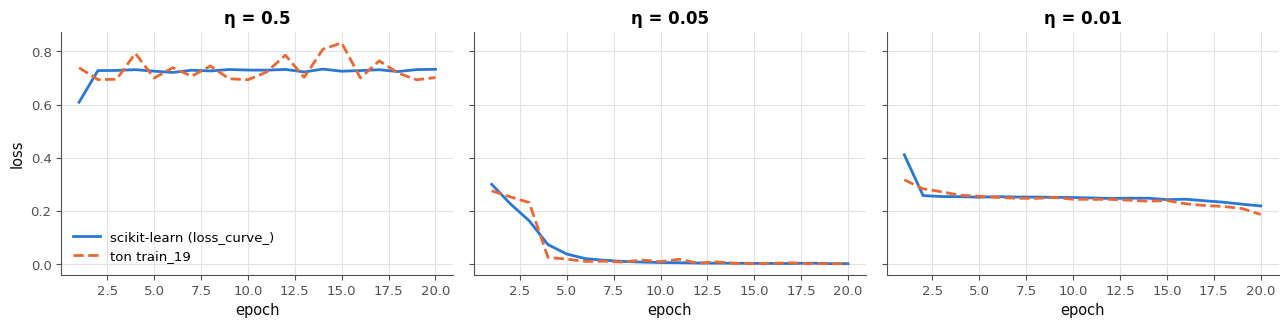

✅ Ex 18.20 : avec scikit-learn aussi, η = 0,5 bloque le réseau sur une seule classe, et η = 0,05 apprend.


In [41]:
def sk_20(lr, seed=0, epochs=EPOCHS_20):
    """A NEW MLPClassifier, fitted on (X_MOONS, y_MOONS), that reproduces the protocol of 18.19 as closely as
    scikit-learn allows (see the statement)."""
    model = MLPClassifier(hidden_layer_sizes=(4, 4), activation="relu", solver="sgd", learning_rate_init=lr,
                          batch_size=1, momentum=0.0, alpha=0.0, max_iter=epochs, shuffle=True,
                          tol=0.0, n_iter_no_change=epochs + 1, random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)   # max_iter is reached on purpose
        return model.fit(X_MOONS, y_MOONS)


SK_20 = {}
if True:
    for lr_20 in (0.5, 0.05, 0.01):
        model_20 = sk_20(lr_20)
        if not isinstance(model_20, MLPClassifier) or not hasattr(model_20, "loss_curve_"):
            print(f"❌ Ex 18.20 : sk_20 doit rendre un MLPClassifier entraîné, reçu {type(model_20).__name__}.")
            break
        p_20 = model_20.get_params()
        wrong_20 = {k: p_20[k] for k, v in {"solver": "sgd", "momentum": 0.0, "alpha": 0.0, "batch_size": 1,
                                             "hidden_layer_sizes": (4, 4), "activation": "relu"}.items()
                    if (tuple(p_20[k]) if k == "hidden_layer_sizes" else p_20[k]) != v}
        if wrong_20:
            print(f"❌ Ex 18.20 : réglages différents du protocole de 18.19 : {wrong_20} (relis l'énoncé).")
            break
        if model_20.n_iter_ != EPOCHS_20:
            print(f"❌ Ex 18.20 : {model_20.n_iter_} epochs au lieu de {EPOCHS_20} : " + (
                "l'arrêt anticipé de scikit-learn s'est déclenché (tol, n_iter_no_change)." if model_20.n_iter_ < EPOCHS_20
                else "max_iter doit valoir l'argument epochs."))
            break
        SK_20[lr_20] = model_20
        print(f"η = {lr_20:<5} scikit-learn accuracy {model_20.score(X_MOONS, y_MOONS):.4f}" +
              (f" · your train_19 (same epochs) {RUNS_19[lr_20][1]['accuracy'][EPOCHS_20 - 1]:.4f}" if lr_20 in RUNS_19 else ""))
if len(SK_20) == 3:
    fig_20, axes_20 = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
    for ax, (lr_20, model_20) in zip(axes_20, SK_20.items()):
        ax.plot(range(1, EPOCHS_20 + 1), model_20.loss_curve_, label="scikit-learn (loss_curve_)")
        if lr_20 in RUNS_19:
            ax.plot(range(1, EPOCHS_20 + 1), RUNS_19[lr_20][1]["loss"][:EPOCHS_20], "--", label="ton train_19")
        ax.set_title(f"η = {lr_20}")
        ax.set_xlabel("epoch")
    axes_20[0].set_ylabel("loss")
    axes_20[0].legend()
    plt.tight_layout()
    plt.show()
    verdict("18.20", SK_20[0.5].score(X_MOONS, y_MOONS) <= 0.55 < SK_20[0.05].score(X_MOONS, y_MOONS),
            "avec scikit-learn aussi, η = 0,5 bloque le réseau sur une seule classe, et η = 0,05 apprend.",
            "les accuracies de scikit-learn sont inattendues : vérifie les réglages (momentum, alpha, batch_size).")

💡 Les mêmes régimes apparaissent : avec $\eta = 0{,}5$, le `MLPClassifier` se bloque lui aussi sur une seule classe (accuracy 0,5), avec $\eta = 0{,}05$ il sépare les lunes, avec $\eta = 0{,}01$ il avance plus lentement. Les courbes diffèrent parce que les protocoles diffèrent : scikit-learn initialise les poids par une loi uniforme de Glorot (et non la loi normale de He de `init_mlp`), et son `loss_curve_` est la **moyenne des losses des exemples pendant l'epoch**, mesurée au fil des mises à jour, alors que `history["loss"]` est la loss de tout l'entraînement **après** l'epoch ; les graines et l'ordre des exemples ne sont pas non plus les mêmes.

### Ex 18.21 — Reproduire les figures 18.49 à 18.57 (η = 0,5 ; 0,05 ; 0,01) 🎨 ★★ ⏱️ 30 min
**Objectif :** tracer, pour chaque learning rate, les courbes d'apprentissage, la frontière et les poids de sortie, puis y lire trois faits.  
**Prérequis :** Ex 18.19 · ch. 15 (`plot_decision_boundary`) · fiche §18.11.1 · **Fil rouge :** synth · **Parcours :** C

Avec les trois entraînements de `RUNS_19` (Ex 18.19 ; `RUNS_19[lr]` est le couple `(params, history)`), trace une figure de trois lignes (une par learning rate) et trois colonnes : la loss et l'accuracy par epoch, la frontière de décision du réseau entraîné (`wb.plot.plot_decision_boundary(NetModel_21(params), X_MOONS, y_MOONS, ax=..., title=...)`), et les 5 paramètres de la couche de sortie par epoch. Puis calcule trois valeurs dans `RUNS_19` (par du code, pas à l'œil) :
a) `perfect_21` : avec $\eta = 0{,}05$, la première epoch (comptée à partir de 1) où l'accuracy vaut exactement 1 ;
b) `plateau_21` : avec $\eta = 0{,}01$, le nombre d'epochs où l'accuracy est strictement sous 0,9 ;
c) `moving_21` : avec $\eta = 0{,}5$, combien des 5 paramètres de la couche de sortie ont une valeur différente à la 1ʳᵉ et à la 40ᵉ epoch.

Dans tes notes : à $\eta = 0{,}5$, pourquoi certains paramètres de sortie ne bougent-ils plus du tout ? Que fait le biais de sortie, et quelle loss vise-t-il ? À $\eta = 0{,}01$, à quoi ressemble la frontière pendant le plateau ?

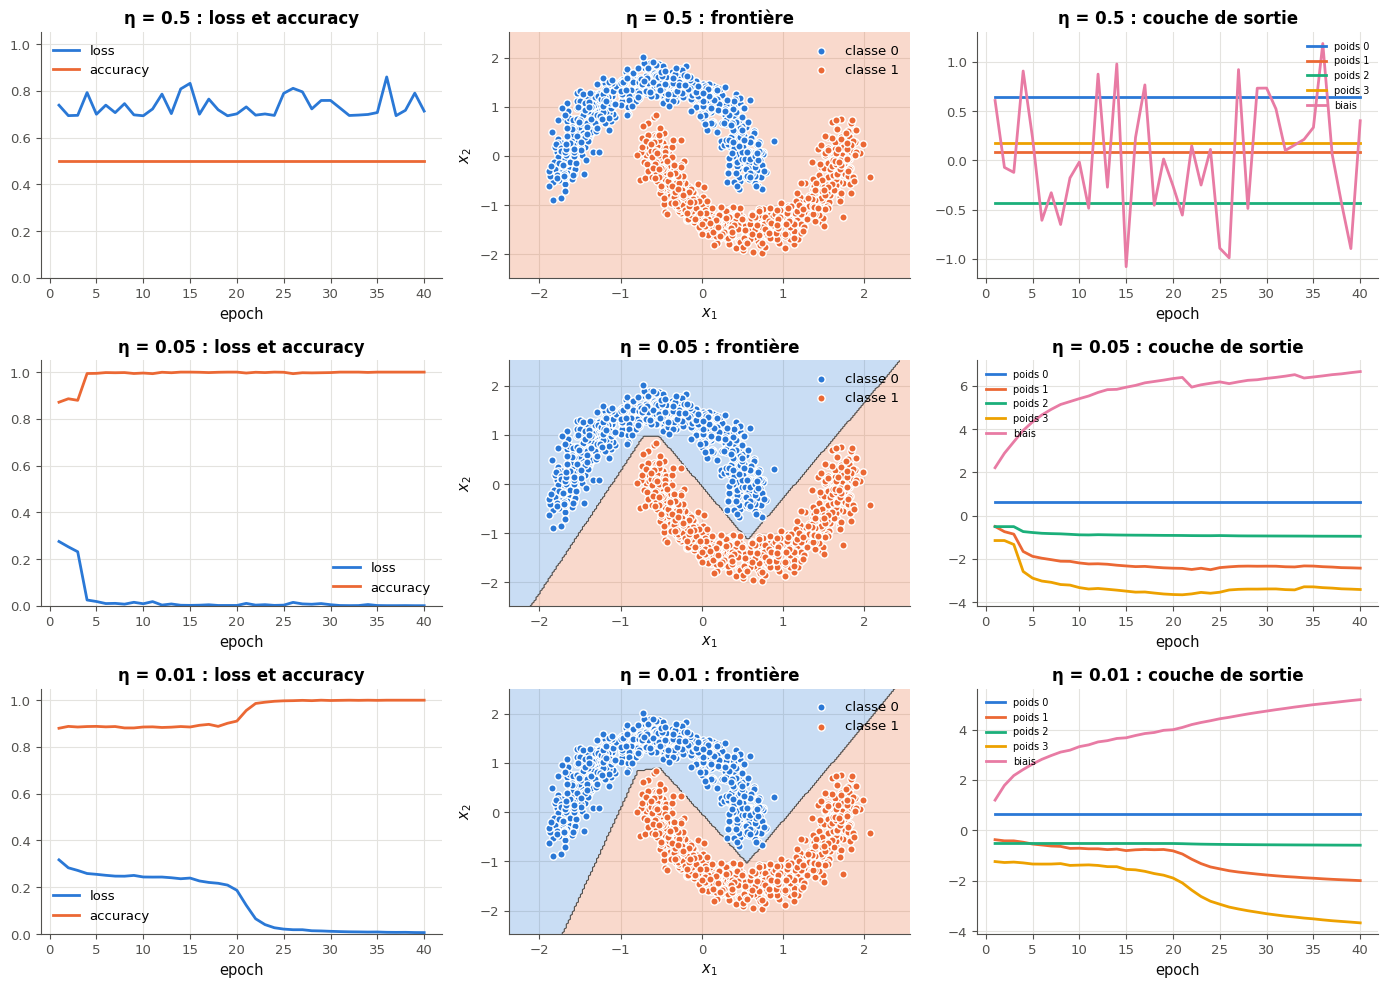

14 18 1


In [42]:
class NetModel_21:
    """Wrap trained params so that wb.plot.plot_decision_boundary can call .predict."""
    def __init__(self, params):
        self.params = params

    def predict(self, X):
        return (mylearn.nn.layers.mlp_forward(X, self.params, mylearn.nn.activations.relu)[:, 0] > 0).astype(int)


fig_21, axes_21 = plt.subplots(3, 3, figsize=(14, 10))
epochs_21 = np.arange(1, EPOCHS_19 + 1)
for row, lr_21 in zip(axes_21, (0.5, 0.05, 0.01)):
    params_21, history_21 = RUNS_19[lr_21]
    row[0].plot(epochs_21, history_21["loss"], label="loss")
    row[0].plot(epochs_21, history_21["accuracy"], label="accuracy")
    row[0].set_ylim(0, 1.05)
    row[0].set_title(f"η = {lr_21} : loss et accuracy")
    row[0].set_xlabel("epoch")
    row[0].legend()
    wb.plot.plot_decision_boundary(NetModel_21(params_21), X_MOONS, y_MOONS, ax=row[1], title=f"η = {lr_21} : frontière")
    out_21 = np.array(history_21["output_layer"])
    for k in range(5):
        row[2].plot(epochs_21, out_21[:, k], label=f"poids {k}" if k < 4 else "biais")
    row[2].set_title(f"η = {lr_21} : couche de sortie")
    row[2].set_xlabel("epoch")
    row[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

acc_05_21 = np.array(RUNS_19[0.05][1]["accuracy"])
perfect_21 = int(np.argmax(acc_05_21 == 1.0)) + 1
plateau_21 = int(np.sum(np.array(RUNS_19[0.01][1]["accuracy"]) < 0.9))
out_50_21 = np.array(RUNS_19[0.5][1]["output_layer"])
moving_21 = int(np.sum(out_50_21[0] != out_50_21[-1]))
print(perfect_21, plateau_21, moving_21)

In [43]:
wb.record("18.21a", perfect_21, mistakes={"compte les epochs à partir de 1 (l'indice Python commence à 0)": perfect_21 - 1,
                                          "une epoch de trop : la première epoch parfaite, numérotée à partir de 1 (indice + 1)": perfect_21 + 1})
wb.record("18.21b", plateau_21, mistakes={"compte les epochs où l'accuracy est SOUS 0,9, pas au-dessus": EPOCHS_19 - plateau_21,
                                          "c'est le numéro de la première epoch où l'accuracy atteint 0,9 ; on demande combien d'epochs restent sous 0,9": plateau_21 + 1})
wb.record("18.21c", moving_21, mistakes={"regarde la troisième figure de la première ligne : combien de courbes restent plates ?": 5,
                                         "le biais de sortie, lui, reçoit-il un gradient quand tous les neurones cachés sont éteints ?": 0,
                                         "il y a 5 paramètres : 4 poids et le biais ; combien bougent ?": 4})

WB_ANSWER {"hash": "69b4b6028b82e9e7c4c0a26adc339ce46b37f5e3836840cf482e5e588da32cf5", "id": "18.21a", "kind": "int", "magnitude": 1, "mistakes": {"b2180eb76229ea5b658d49f70c64051f4b8befdbe8d5c83f705bf7cabf65a554": "compte les epochs à partir de 1 (l'indice Python commence à 0)", "fe3e54423e34a5287b77ff39e77035d6cb623b5f5b7f55252150b758d13a760b": "une epoch de trop : la première epoch parfaite, numérotée à partir de 1 (indice + 1)"}, "sign": 1}
📝 Ex 18.21a : réponse enregistrée (int).
WB_ANSWER {"hash": "422b52223af1a7145e684e766c30facc87680d2fff1256bdd78efdbe71cf2973", "id": "18.21b", "kind": "int", "magnitude": 1, "mistakes": {"57ecb78747e94650e8458ad457b820a6c7acc7d0c69ff4035f014d861bb69bb3": "compte les epochs où l'accuracy est SOUS 0,9, pas au-dessus", "deb2a620b96ba6f622f62f9b607048e42fc64f352c52822130d474356fa592c5": "c'est le numéro de la première epoch où l'accuracy atteint 0,9 ; on demande combien d'epochs restent sous 0,9"}, "sign": 1}
📝 Ex 18.21b : réponse enregistrée (int)

💡 À $\eta = 0{,}5$, les quatre neurones de la seconde couche cachée sont éteints après la première epoch : leurs sorties valent 0 pour tous les points, les quatre poids de sortie ne reçoivent plus aucun gradient ($a_i\,\delta = 0$) et restent figés ; plus aucun gradient ne traverse la couche éteinte, et la première couche se fige aussi. Seul le biais de sortie bouge : chaque exemple le pousse vers sa propre classe, d'un pas de $\eta\,(\sigma(b) - y)$, et il saute d'un bord à l'autre (jusqu'à 2 d'une epoch à l'autre) autour de 0, la valeur qui minimise la loss d'un réseau constant ($\log 2$). C'est la figure du livre où « un poids de sortie saute ». À $\eta = 0{,}01$, pendant le plateau (18 epochs sous 0,9), la frontière est presque une droite qui coupe les deux lunes : les deux couches cachées ne font pas encore leur coude. Le premier neurone de la dernière couche cachée est mort dès le départ dans les trois entraînements (son poids de sortie reste à 0,639) : un cas de ReLU morte, que 🔬 18.24 étudiera.

## Partie C · Diagnostiquer un entraînement

Reconnaître un learning rate mal réglé ou un bug sur des courbes de loss (18.22), balayer le learning rate du réseau des lunes sur cinq graines (18.23), voir des neurones mourir ou saturer pendant un entraînement sur MNIST (18.24), puis écrire un test pytest qui attrape les gradients faux d'une couche (18.25).

### Ex 18.22 — Lire des courbes de loss : divergence, lenteur, plateau, bug 📈 ★★ ⏱️ 20 min
**Objectif :** reconnaître, sur une courbe de loss, un learning rate trop grand ou trop petit, un plateau et deux bugs.  
**Prérequis :** 18.Q8 · ✏️ 18.3 · fiche §18.11, §18.11.1, §18.12.8 · **Fil rouge :** synth · **Parcours :** R, M

Six entraînements d'un même classifieur à $K$ classes équilibrées (cross-entropy moyenne en nats, tracée à chaque epoch ; les courbes sont fabriquées, mais leurs formes sont celles qu'on rencontre). Chacun souffre d'un des problèmes ci-dessous, sauf un qui se passe bien. Pour chaque question, la **lettre** de la courbe :
a) `too_large_22` : un learning rate beaucoup trop grand ;
b) `too_small_22` : un learning rate beaucoup trop petit ;
c) `plateau_22` : une région presque plate de la surface de la loss, traversée puis quittée ;
d) `sign_22` : une erreur de signe dans la mise à jour, $w \leftarrow w + \eta\,\partial L / \partial w$ ;
e) `frozen_22` : des poids qui ne sont jamais mis à jour (mise à jour oubliée, ou $\eta = 0$) ;
f) `classes_22` : toutes les courbes partent de la loss d'un réseau qui donne la même probabilité $\frac1K$ à chaque classe ; combien de classes le problème compte-t-il ?

Dans tes notes : pour chaque problème, le premier geste que tu ferais (fiche §18.12.8) ; quelle courbe pourrait aussi venir d'un gradient faux, et comment le vérifier ?

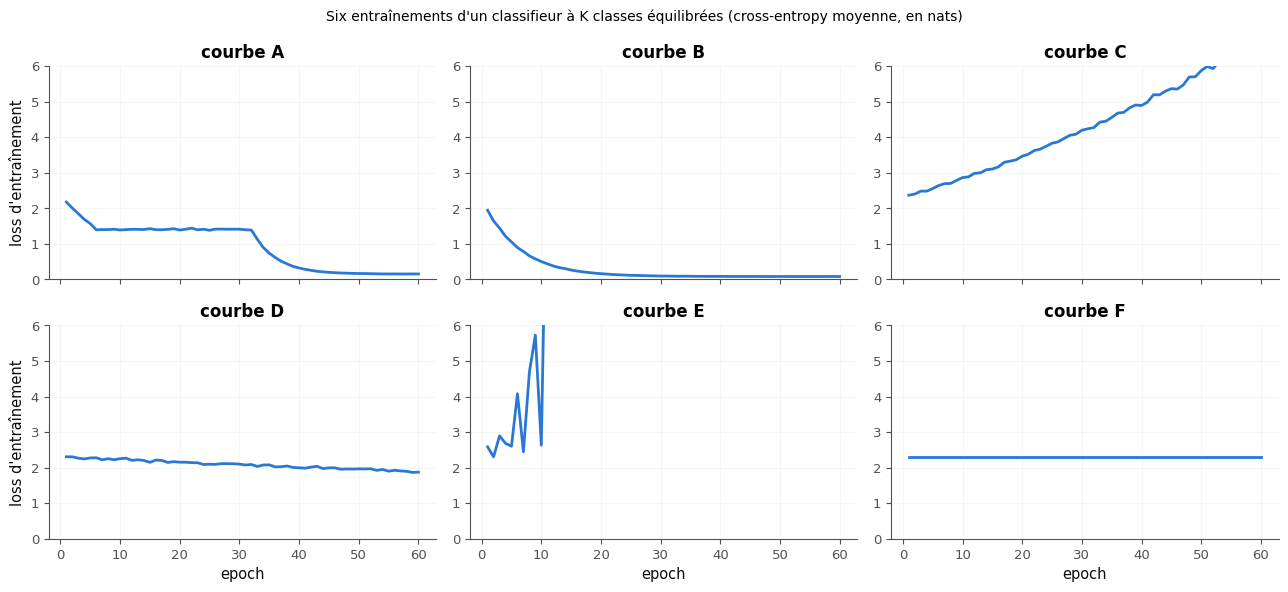

In [44]:
def curves_22():
    """Six synthetic training curves of a 10-class classifier (mean cross-entropy per epoch), labelled A to F."""
    rng = np.random.default_rng(1822)
    t = np.arange(1, 61, dtype=float)
    start = np.log(10.0)
    noise = lambda size=60: 1 + 0.01 * rng.normal(size=size)
    plateau = np.where(t < 6, start - (start - 1.4) * t / 6, 1.4)
    plateau = np.where(t > 32, 1.4 - 1.25 * (1 - np.exp(-(t - 32) / 4)), plateau) * noise()
    explode = start + 0.12 * 1.4 ** t * (1 + np.sin(2.4 * t))
    explode[t > 11] = np.nan                                  # the loss became inf, then nan
    return {"A": plateau,
            "B": (0.08 + (start - 0.08) * np.exp(-t / 6)) * noise(),
            "C": (start + 0.05 * t + 0.0004 * t ** 2) * noise(),
            "D": (start - 0.007 * t) * noise(),
            "E": explode,
            "F": np.full(60, start)}


CURVES_22 = curves_22()
fig_22, axes_22 = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, (name, curve) in zip(axes_22.ravel(), CURVES_22.items()):
    ax.plot(np.arange(1, 61), curve, color="#2a78d6")
    ax.set_title(f"courbe {name}")
    ax.set_ylim(0, 6)
    ax.grid(alpha=0.3)
for ax in axes_22[1]:
    ax.set_xlabel("epoch")
for ax in axes_22[:, 0]:
    ax.set_ylabel("loss d'entraînement")
fig_22.suptitle("Six entraînements d'un classifieur à K classes équilibrées (cross-entropy moyenne, en nats)", fontsize=10)
plt.tight_layout()
plt.show()

In [45]:
too_large_22, too_small_22, plateau_22, sign_22, frozen_22, classes_22 = "E", "D", "A", "C", "F", 10

In [46]:
wb.record("18.22a", "E", mistakes={"cette courbe baisse vite, reste longtemps à plat, puis baisse de nouveau : relis la définition de chaque cas": "A", "cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien": "B", "cette courbe monte régulièrement, sans osciller : relis ce que fait chaque erreur": "C", "cette courbe baisse, mais très peu : relis la définition de chaque cas": "D", "cette courbe ne bouge pas du tout : relis la définition de chaque cas": "F"})
wb.record("18.22b", "D", mistakes={"cette courbe baisse vite, reste longtemps à plat, puis baisse de nouveau : relis la définition de chaque cas": "A", "cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien": "B", "cette courbe monte régulièrement, sans osciller : relis ce que fait chaque erreur": "C", "cette courbe oscille de plus en plus fort, puis s'interrompt : relis la définition de chaque cas": "E", "cette courbe ne bouge pas du tout : relis la définition de chaque cas": "F"})
wb.record("18.22c", "A", mistakes={"cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien": "B", "cette courbe monte régulièrement, sans osciller : relis ce que fait chaque erreur": "C", "cette courbe baisse, mais très peu : relis la définition de chaque cas": "D", "cette courbe oscille de plus en plus fort, puis s'interrompt : relis la définition de chaque cas": "E", "cette courbe ne bouge pas du tout : relis la définition de chaque cas": "F"})
wb.record("18.22d", "C", mistakes={"cette courbe baisse vite, reste longtemps à plat, puis baisse de nouveau : relis la définition de chaque cas": "A", "cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien": "B", "cette courbe baisse, mais très peu : relis la définition de chaque cas": "D", "cette courbe oscille de plus en plus fort, puis s'interrompt : relis la définition de chaque cas": "E", "cette courbe ne bouge pas du tout : relis la définition de chaque cas": "F"})
wb.record("18.22e", "F", mistakes={"cette courbe baisse vite, reste longtemps à plat, puis baisse de nouveau : relis la définition de chaque cas": "A", "cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien": "B", "cette courbe monte régulièrement, sans osciller : relis ce que fait chaque erreur": "C", "cette courbe baisse, mais très peu : relis la définition de chaque cas": "D", "cette courbe oscille de plus en plus fort, puis s'interrompt : relis la définition de chaque cas": "E"})
wb.record("18.22f", 10, fractional="compte des classes : un nombre entier, K = e^L pour la loss L de départ",
          mistakes={"la loss d'un réseau qui répond 1/K à chaque classe vaut log K, en nats (logarithme népérien) : pas log2 K": 5,
                    "log K vaut la loss de départ : K = e^L, pas L lui-même": 2})

WB_ANSWER {"hash": "c01be78fcb3f5e40a7f57def088248531faed4c25099d63d17643c0a2149fb8c", "id": "18.22a", "kind": "str", "mistakes": {"3ff974f898fdfc31f6b5f619ebfd823441099091d3b1d634d71a9687c6231568": "cette courbe ne bouge pas du tout : relis la définition de chaque cas", "630d6235cbf4568d69c41520ae92b99d798f18cadfe22019b80e3640ecb0968c": "cette courbe baisse, mais très peu : relis la définition de chaque cas", "7f76d6c4123d153f7293b23497121678a82a09f00e1a20d648a3730938952b35": "cette courbe baisse vite et régulièrement : c'est un entraînement qui se passe bien", "ba31086d4dd861eb82939ec82d2579b3d46d3301e8f72e98ad50e75561619309": "cette courbe baisse vite, reste longtemps à plat, puis baisse de nouveau : relis la définition de chaque cas", "c90d323d67b359259613b0ff54abbd3cdceb5b029dce63027bbb329d8a418719": "cette courbe monte régulièrement, sans osciller : relis ce que fait chaque erreur"}}
📝 Ex 18.22a : réponse enregistrée (str).
WB_ANSWER {"hash": "461c109c814ba13fd746f95234794d746461

💡 E oscille de plus en plus fort, puis s'interrompt quand la loss devient infinie (`nan` ensuite) : le pas saute par-dessus le creux, comme sur la parabole de ✏️ 18.3 avec $|1 - \eta a| > 1$ ; on divise $\eta$ par 10. D baisse, mais si peu qu'au bout de 60 epochs la loss n'a perdu que 0,4 : on multiplie $\eta$ par 3 ou par 10. A baisse, reste à plat de la 6ᵉ à la 32ᵉ epoch, puis repart : un plateau, que la patience (ou un optimiseur du ch. 19) traverse. C monte régulièrement, sans osciller : chaque pas va **dans le sens** du gradient, une erreur de signe (un gradient faux ferait la même chose : `gradient_check` tranche). F ne bouge pas : la loss reste exactement celle de départ. Toutes partent de $\log K = 2{,}30$ nats, soit $K = e^{2{,}30} = 10$ classes. B, enfin, est l'entraînement sain.

### Ex 18.23 — Balayage du learning rate sur cinq graines 🔬 ★★★ ⏱️ 40 min
**Objectif :** balayer le learning rate du réseau des lunes sur une grille logarithmique et cinq graines, et lire la plage utile.  
**Prérequis :** Ex 18.19 · fiche §18.11 (encadré sur le choix du learning rate), §18.12.8 · **Fil rouge :** synth · **Parcours :** C

Écris `sweep_23(lrs, seeds, epochs)`, qui entraîne le réseau de 18.19 (avec **ton** `train_19`, `batch_size=1`) pour chaque learning rate de `lrs` et chaque graine de `seeds`, et rend deux tableaux de forme `(len(lrs), len(seeds))` : la loss et l'accuracy sur `(X_MOONS, y_MOONS)` après la dernière epoch. La vérification lance 25 entraînements de 10 epochs (une minute environ), affiche le tableau, puis trace la loss médiane avec sa dispersion et l'accuracy de chaque graine, en fonction de $\eta$ (échelle logarithmique).

Puis réponds, d'après le tableau affiché :
a) `best_23` : la valeur de `LRS_23` qui donne la plus petite loss **médiane** ;
b) `stuck_23` : avec $\eta = 0{,}3$, combien des cinq graines finissent avec une accuracy d'au plus 0,55 (un réseau qui répond presque toujours la même classe) ?

Dans tes notes : pourquoi regarder la médiane et la dispersion plutôt qu'une seule graine ? La plus petite loss de **toutes** les graines est-elle obtenue au même $\eta$ que la plus petite médiane ? Quel $\eta$ choisirais-tu pour un nouveau réseau, et pourquoi pas le plus grand qui marche parfois ?

In [47]:
LRS_23 = [0.003, 0.01, 0.03, 0.1, 0.3]
SEEDS_23 = [0, 1, 2, 3, 4]
EPOCHS_23 = 10

25 entraînements en 72 s
η = 0.003  losses [0.267, 0.086, 0.269, 0.079, 0.215] · median 0.215 · accuracies [0.887, 0.99, 0.896, 0.99, 0.899]
η = 0.01   losses [0.244, 0.017, 0.067, 0.016, 0.009] · median 0.017 · accuracies [0.885, 0.999, 0.985, 0.999, 0.999]
η = 0.03   losses [0.008, 0.005, 0.003, 0.005, 0.001] · median 0.005 · accuracies [0.999, 0.999, 1.0, 1.0, 1.0]
η = 0.1    losses [0.228, 0.007, 0.003, 0.047, 0.0] · median 0.007 · accuracies [0.9, 0.997, 0.999, 0.983, 1.0]
η = 0.3    losses [0.693, 0.35, 0.74, 0.816, 0.698] · median 0.698 · accuracies [0.5, 0.889, 0.5, 0.5, 0.5]


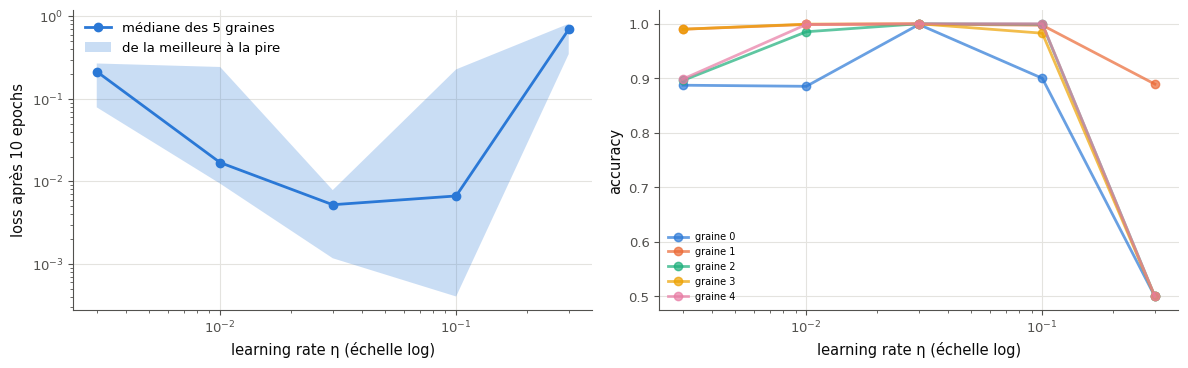

In [48]:
def sweep_23(lrs, seeds, epochs):
    """Train the network of 18.19 (YOUR train_19, batch_size=1) for every learning rate and every seed.

    Returns (losses, accuracies): two arrays of shape (len(lrs), len(seeds)), the loss and the accuracy on
    (X_MOONS, y_MOONS) after the last epoch.
    """
    losses = np.zeros((len(lrs), len(seeds)))
    accuracies = np.zeros((len(lrs), len(seeds)))
    for i, lr in enumerate(lrs):
        for j, seed in enumerate(seeds):
            _, history = train_19(X_MOONS, y_MOONS, lr, epochs, seed=seed)
            losses[i, j], accuracies[i, j] = history["loss"][-1], history["accuracy"][-1]
    return losses, accuracies

SWEEP_23 = None
if True:
    started_23 = time.perf_counter()
    result_23 = sweep_23(LRS_23, SEEDS_23, EPOCHS_23)
    shape_23 = (len(LRS_23), len(SEEDS_23))
    if not (isinstance(result_23, tuple) and len(result_23) == 2 and all(np.shape(r) == shape_23 for r in result_23)):
        print(f"❌ Ex 18.23 : sweep_23 doit rendre le tuple (losses, accuracies) de deux tableaux de forme {shape_23}.")
    else:
        SWEEP_23 = tuple(np.asarray(r, dtype=float) for r in result_23)
        print(f"{len(LRS_23) * len(SEEDS_23)} entraînements en {time.perf_counter() - started_23:.0f} s")
if SWEEP_23 is not None:
    losses_23, accuracies_23 = SWEEP_23
    for lr_23, l_23, a_23 in zip(LRS_23, losses_23, accuracies_23):
        print(f"η = {lr_23:<6} losses {np.round(l_23, 3).tolist()} · median {np.median(l_23):.3f} · accuracies {np.round(a_23, 3).tolist()}")
    fig_23, (ax_l, ax_a) = plt.subplots(1, 2, figsize=(12, 3.8))
    ax_l.plot(LRS_23, np.median(losses_23, axis=1), "o-", label="médiane des 5 graines")
    ax_l.fill_between(LRS_23, losses_23.min(axis=1), losses_23.max(axis=1), alpha=0.25, label="de la meilleure à la pire")
    ax_l.set_xscale("log")
    ax_l.set_yscale("log")
    ax_l.set_xlabel("learning rate η (échelle log)")
    ax_l.set_ylabel(f"loss après {EPOCHS_23} epochs")
    ax_l.legend()
    for j_23, seed_23 in enumerate(SEEDS_23):
        ax_a.plot(LRS_23, accuracies_23[:, j_23], "o-", alpha=0.7, label=f"graine {seed_23}")
    ax_a.set_xscale("log")
    ax_a.set_xlabel("learning rate η (échelle log)")
    ax_a.set_ylabel("accuracy")
    ax_a.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

In [49]:
best_23 = LRS_23[int(np.argmin(np.median(SWEEP_23[0], axis=1)))]
stuck_23 = int(np.sum(SWEEP_23[1][LRS_23.index(0.3)] <= 0.55))
print(best_23, stuck_23)

0.03 4


In [50]:
wb.record("18.23a", best_23, decimals=3, choices=LRS_23,
          mistakes={"c'est la valeur de la meilleure graine, pas de la meilleure médiane : relis la colonne median": 0.1,
                    "relis la question : la plus petite loss médiane, pas la plus grande": 0.3,
                    "relis la colonne median : une loss plus petite existe ailleurs dans la grille": 0.01,
                    "le plus petit learning rate n'est pas forcément le meilleur après 10 epochs : relis la colonne median": 0.003})
wb.record("18.23b", stuck_23, mistakes={"compte les accuracies AU PLUS 0,55 sur la ligne η = 0,3": 5,
                                        "compte les accuracies au plus 0,55, pas les autres": 5 - stuck_23})

WB_ANSWER {"choices": ["0.003", "0.010", "0.030", "0.100", "0.300"], "decimals": 3, "hash": "4a707055c96f92ca551d8c91415cb5c19092724e3e6469e01f873d73a31ea7e8", "hash_coarse": "07c805f847e850e5878111302776e286ab44e49404e3e523377bdfcd3d0fb4e7", "id": "18.23a", "kind": "float", "magnitude": -2, "mistakes": {"0cd9a9dfc3a0920a324f7c51b0c0e92bcaa3e0da98aa3e19058397ee2e0caae3": "le plus petit learning rate n'est pas forcément le meilleur après 10 epochs : relis la colonne median", "0fc82292b1f55ebf7cf16291f7b4ee4113039481c4a88233eb67a96176e7ca2f": "relis la colonne median : une loss plus petite existe ailleurs dans la grille", "1339322a00e8165bb4a4d9d2272bd4782d4921402639b36cadffeb3f88a1d92b": "relis la question : la plus petite loss médiane, pas la plus grande", "26dc2979afde7a1d69c06910dc89447da1930943d683ff983a49b363b505d1c3": "c'est la valeur de la meilleure graine, pas de la meilleure médiane : relis la colonne median"}, "sign": 1}
📝 Ex 18.23a : réponse enregistrée (float, 3 décimale(s))

💡 Avec 10 epochs, la loss médiane est la plus petite pour $\eta = 0{,}03$, où les cinq graines séparent presque parfaitement les lunes. $\eta = 0{,}1$ donne la plus petite loss d'une seule graine, mais une autre reste bloquée vers 0,9 d'accuracy : sa médiane est un peu moins bonne et sa dispersion bien plus grande. Avec $\eta = 0{,}3$, quatre graines sur cinq finissent avec un réseau éteint (accuracy 0,5) : le « meilleur cas » d'un grand $\eta$ ne dit rien de son cas typique. À l'autre bout, $\eta = 0{,}003$ avance trop lentement (médiane 0,215) : trois graines sur cinq sont encore sur le plateau, sous 0,9. On choisit donc un $\eta$ au milieu de la plage où **toutes** les graines marchent, en échelle logarithmique, et on le vérifie sur d'autres graines.

### Ex 18.24 — Neurones saturés et ReLU mortes pendant l'entraînement 🔬 ★★★ ⏱️ 45 min
**Objectif :** mesurer, pendant un entraînement sur MNIST, la part de neurones ReLU morts et de valeurs sigmoïdes saturées.  
**Prérequis :** Ex 18.19 · ch. 16 (initialisations) · ch. 17 (saturation) · fiche §18.12.4 · **Fil rouge :** MNIST · **Parcours :** C

Sur 10 000 images de MNIST, un MLP 784-100-100-10 est entraîné 5 epochs par `train_24` (fournie, avec **ta** librairie : `init_weights`, `mlp_forward`, `softmax_cross_entropy`, `mlp_backward`), qui garde, avant l'entraînement puis après chaque epoch, les pré-activations des deux couches cachées sur 1 000 images (`PROBE_24`). Trois réglages : ReLU, poids de He et $\eta = 0{,}05$ ; ReLU, poids de He et $\eta = 1$ ; sigmoïde, poids tirés de $\mathcal{N}(0 ;\ 1)$ et $\eta = 0{,}5$.

Écris deux mesures, qui reçoivent un tableau `z` de forme `(n_exemples, n_neurones)` :
- `dead_fraction_24(z)` : la part des **neurones** (les colonnes) dont la pré-activation est $\le 0$ pour **tous** les exemples : les ReLU mortes de ce batch ;
- `saturated_fraction_24(z, threshold=4.6)` : la part des **valeurs** de `z` telles que $|z| > 4{,}6$ (là, $\sigma'(z) < 0{,}01$ : une sigmoïde saturée).

La vérification essaie tes deux mesures sur un petit tableau, lance les trois entraînements (une dizaine de secondes), trace l'accuracy, la part de neurones morts des deux réseaux ReLU et la part de valeurs saturées du réseau sigmoïde, et contrôle deux ordres de grandeur.

Dans tes notes : que devient le réseau ReLU avec $\eta = 1$, et pourquoi ses neurones morts ne reviennent-ils pas ? Le réseau sigmoïde apprend-il malgré la saturation, et à quelle vitesse ? Quel remède de la fiche (§18.12.4) appliquerais-tu à chacun ?

In [51]:
X_24, Y_24 = wb.datasets.load_mnist("train", n=10_000, flatten=True, normalize=True, seed=1824)
PROBE_24 = X_24[:1000]                              # the images on which the neurons are watched


def train_24(activation, method, lr, epochs=5, scale=0.05, seed=0, batch_size=64):
    """Train a 784-100-100-10 MLP on X_24 with YOUR library (softmax cross-entropy, SGD), and keep, before training
    and after every epoch, the pre-activations of the two hidden layers on PROBE_24 and the accuracy on X_24."""
    A, L, B = mylearn.nn.activations, mylearn.nn.layers, mylearn.nn.backward
    f, df = A.get_activation(activation)
    rng = np.random.default_rng(seed)
    sizes = [784, 100, 100, 10]
    params = [(L.init_weights(a, b, method, rng, scale=scale), np.zeros(b)) for a, b in zip(sizes[:-1], sizes[1:])]
    record = {"z": [], "accuracy": []}
    for epoch in range(epochs + 1):
        if epoch > 0:
            for idx in mylearn.utils.iterate_minibatches(len(X_24), batch_size, rng=rng):
                out, cache = L.mlp_forward(X_24[idx], params, f, None, return_cache=True)
                _, dout = B.softmax_cross_entropy(out, Y_24[idx])
                grads = B.mlp_backward(dout, cache, params, activation_derivative=df)
                params = [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)]
        _, cache = L.mlp_forward(PROBE_24, params, f, None, return_cache=True)
        record["z"].append([z for _, z in cache[:-1]])           # two arrays of shape (1000, 100)
        record["accuracy"].append(float(np.mean(L.mlp_forward(X_24, params, f).argmax(axis=1) == Y_24)))
    return record


CONFIGS_24 = {"ReLU, He, η = 0,05": ("relu", "he_normal", 0.05, 0.05),
              "ReLU, He, η = 1": ("relu", "he_normal", 1.0, 0.05),
              "sigmoïde, N(0, 1), η = 0,5": ("sigmoid", "normal", 0.5, 1.0)}
print("MNIST:", X_24.shape, "· probe:", PROBE_24.shape)

MNIST: (10000, 784) · probe: (1000, 784)


✅ Ex 18.24 : dead_fraction_24 : 2 neurons sur 4 jamais actifs (z ≤ 0 partout, 0 compris), soit 0,5.
✅ Ex 18.24 : saturated_fraction_24 : 2 valeurs sur 12 au-delà de 4,6 en valeur absolue.


three trainings in 84 s
ReLU, He, η = 0,05           accuracy [0.135, 0.82, 0.889, 0.924, 0.937, 0.935]
                             layer 1: dead [0.0, 0.0, 0.0, 0.0, 0.0, 0.0] · saturated [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
                             layer 2: dead [0.01, 0.02, 0.02, 0.02, 0.02, 0.03] · saturated [0.0, 0.01, 0.01, 0.01, 0.01, 0.01]
ReLU, He, η = 1              accuracy [0.135, 0.282, 0.306, 0.195, 0.297, 0.278]
                             layer 1: dead [0.0, 0.76, 0.86, 0.88, 0.9, 0.9] · saturated [0.0, 0.42, 0.48, 0.49, 0.52, 0.52]
                             layer 2: dead [0.01, 0.37, 0.79, 0.92, 0.9, 0.87] · saturated [0.0, 0.02, 0.02, 0.03, 0.07, 0.13]
sigmoïde, N(0, 1), η = 0,5   accuracy [0.112, 0.648, 0.711, 0.859, 0.874, 0.891]
                             layer 1: dead [0.0, 0.0, 0.0, 0.0, 0.0, 0.0] · saturated [0.62, 0.65, 0.66, 0.67, 0.67, 0.67]
                             layer 2: dead [0.03, 0.06, 0.07, 0.08, 0.08, 0.07] · saturated [0.5, 0.62, 0.64, 0.64

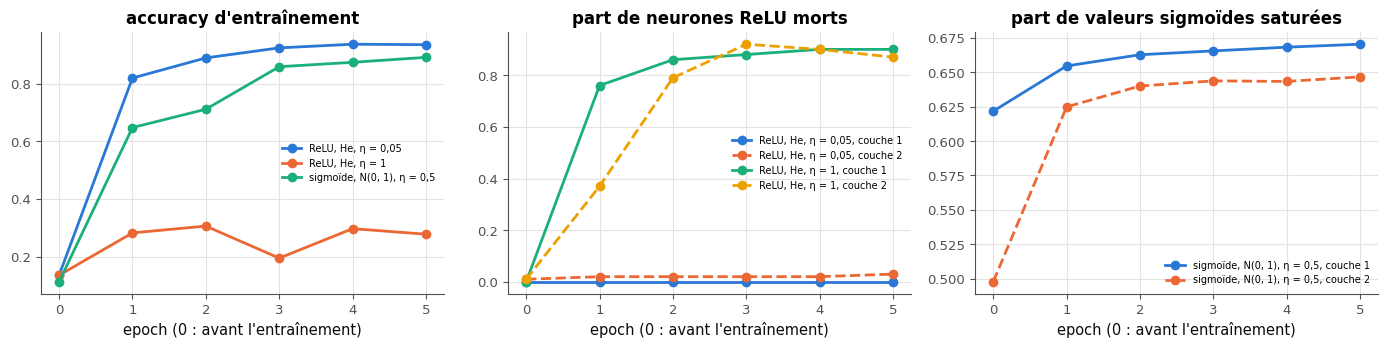

✅ Ex 18.24 : avec η = 1, une grande part des neurones ReLU de la première couche est morte ; avec η = 0,05, presque aucun.
✅ Ex 18.24 : avec des poids N(0, 1), plus d'un tiers des valeurs sigmoïdes de la première couche sont saturées dès le départ.


In [52]:
def dead_fraction_24(z):
    """The fraction of the neurons (columns of z, shape (n_samples, n_neurons)) whose pre-activation is <= 0 for
    EVERY sample: the dead ReLU neurons of this batch."""
    return float(np.mean(np.all(np.asarray(z) <= 0, axis=0)))


def saturated_fraction_24(z, threshold=4.6):
    """The fraction of the entries of z where |z| > threshold (for a sigmoid, sigma'(4.6) < 0.01: a saturated value)."""
    return float(np.mean(np.abs(np.asarray(z)) > threshold))


if True:
    small_24 = np.array([[-1.0, 2.0, 0.0, -3.0], [-0.5, -1.0, 0.0, 5.0], [-2.0, 0.5, 0.0, -6.0]])
    verdict("18.24", dead_fraction_24(small_24) == 0.5,
            "dead_fraction_24 : 2 neurons sur 4 jamais actifs (z ≤ 0 partout, 0 compris), soit 0,5.",
            f"dead_fraction_24 sur un petit exemple : {dead_fraction_24(small_24)!r}, attendu 0,5 "
            "(une colonne = un neurone ; mort si z ≤ 0 pour TOUS les exemples).")
    verdict("18.24", saturated_fraction_24(small_24) == 2 / 12,
            "saturated_fraction_24 : 2 valeurs sur 12 au-delà de 4,6 en valeur absolue.",
            f"saturated_fraction_24 sur un petit exemple : {saturated_fraction_24(small_24)!r}, attendu 2/12 (|z| > 4,6, parmi toutes les valeurs).")
RECORDS_24 = {}
if written(lambda: dead_fraction_24(np.zeros((1, 1)))) and written(lambda: saturated_fraction_24(np.zeros((1, 1)))):
    if True:
        started_24 = time.perf_counter()
        for name_24, (act_24, method_24, lr_24, scale_24) in CONFIGS_24.items():
            RECORDS_24[name_24] = train_24(act_24, method_24, lr_24, scale=scale_24)
        print(f"three trainings in {time.perf_counter() - started_24:.0f} s")
if len(RECORDS_24) == 3:
    fig_24, axes_24 = plt.subplots(1, 3, figsize=(14, 3.6))
    for name_24, record_24 in RECORDS_24.items():
        epochs_24 = range(len(record_24["accuracy"]))
        measure_24 = saturated_fraction_24 if "sigmo" in name_24 else dead_fraction_24
        axes_24[0].plot(epochs_24, record_24["accuracy"], "o-", label=name_24)
        for layer_24, ls_24 in ((0, "-"), (1, "--")):
            axes_24[1 if measure_24 is dead_fraction_24 else 2].plot(
                epochs_24, [measure_24(z[layer_24]) for z in record_24["z"]], ls_24, marker="o",
                label=f"{name_24}, couche {layer_24 + 1}")
        print(f"{name_24:28s} accuracy {[round(a, 3) for a in record_24['accuracy']]}")
        for layer_24 in (0, 1):
            print(f"{'':28s} layer {layer_24 + 1}: dead {[round(dead_fraction_24(z[layer_24]), 2) for z in record_24['z']]}"
                  f" · saturated {[round(saturated_fraction_24(z[layer_24]), 2) for z in record_24['z']]}")
    axes_24[0].set_title("accuracy d'entraînement")
    axes_24[1].set_title("part de neurones ReLU morts")
    axes_24[2].set_title("part de valeurs sigmoïdes saturées")
    for ax in axes_24:
        ax.set_xlabel("epoch (0 : avant l'entraînement)")
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()
    relu_big_24 = RECORDS_24["ReLU, He, η = 1"]
    verdict("18.24", dead_fraction_24(relu_big_24["z"][-1][0]) > 0.3 > dead_fraction_24(RECORDS_24["ReLU, He, η = 0,05"]["z"][-1][0]),
            "avec η = 1, une grande part des neurones ReLU de la première couche est morte ; avec η = 0,05, presque aucun.",
            "les parts de neurones morts sont inattendues : vérifie ta librairie (18.18, 18.14) et dead_fraction_24.")
    verdict("18.24", saturated_fraction_24(RECORDS_24["sigmoïde, N(0, 1), η = 0,5"]["z"][0][0]) > 0.3,
            "avec des poids N(0, 1), plus d'un tiers des valeurs sigmoïdes de la première couche sont saturées dès le départ.",
            "la part de valeurs saturées au départ est inattendue : relis saturated_fraction_24.")

💡 Avec $\eta = 0{,}05$, presque aucun neurone ne meurt (2 à 3 % dans la seconde couche) et l'accuracy monte à 0,94. Avec $\eta = 1$, la première epoch projette les poids si loin que les trois quarts des neurones de la première couche ne s'allument plus pour aucune image (76 %, puis environ 90 %), et la seconde suit : le réseau reste vers 0,3 d'accuracy. Un neurone mort ne reçoit plus aucun gradient ($\mathrm{ReLU}'(z) = 0$ partout) : ses poids d'entrée ne bougent plus, et seul un changement des couches d'avant pourrait le rallumer. Remède : un learning rate plus petit (et une bonne initialisation). Avec des poids $\mathcal{N}(0 ;\ 1)$, 62 % des valeurs sigmoïdes de la première couche sont saturées au départ, et le restent (65 à 67 %) : le réseau apprend quand même, plus lentement (0,89 après 5 epochs, contre 0,92 pour une initialisation de Glorot), grâce aux neurones qui restent dans la partie utile. Remède : l'initialisation de Glorot (ch. 16), ou une activation sans plateau.

### Ex 18.25 — Écrire un test pytest de gradient pour une couche 🛠️ ★★ ⏱️ 25 min
**Objectif :** écrire des tests pytest, dont un paramétré, qui comparent la passe arrière d'une couche aux différences finies et attrapent cinq bugs.  
**Prérequis :** Ex 18.16 · ch. 17 (🛠️ 17.22, tests paramétrés) · 0A (`wb.run_pytest`) · fiche, section sur la vérification d'un gradient · **Parcours :** C

La fonction `layer_ok(dout, x, W, b)` (fournie) est la passe arrière, juste, de la couche $\mathbf{a} = \tanh(\mathbf{x}\mathbf{W} + \mathbf{b})$ : elle reçoit `dout` $= \partial L / \partial \mathbf{a}$ et rend `(dx, dW, db)`, sans modifier ses entrées ; `layer_forward(x, W, b)` calcule la passe avant. Écris une **batterie de tests** pytest pour une fonction `layer_backward(dout, x, W, b)` qui a ce contrat : au moins un test **paramétré** (`@pytest.mark.parametrize`, par exemple sur plusieurs formes), et un test qui compare les trois gradients à des **différences finies centrées** d'une loss $L = \sum \mathbf{G} \odot \mathbf{a}$ (dont le gradient en $\mathbf{a}$ vaut exactement $\mathbf{G}$).

Range tes tests dans la liste `my_tests_25`. Comme en 17.22, la vérification lance vraiment pytest : tes tests doivent **passer** sur `layer_ok` et **échouer** sur chacune des cinq versions buggées fournies, `layer_bug_1` à `layer_bug_5` (lis-les : que fait chacune de travers ?). Tes tests ne peuvent utiliser que `layer_backward`, `layer_forward`, `np`, `math` et `pytest` ; s'ils ont besoin d'une fonction à toi (des différences finies), définis-la sous le nom `numeric_25`, la vérification la copie avec eux. Cet exercice se corrige avec `05_solutions.md`.

Dans tes notes : pour chaque version buggée, le test qui l'attrape. Laquelle passerait un test de différences finies écrit sur une seule forme carrée ?

In [53]:
import math

import pytest                                     # for the @pytest.mark.parametrize decorators of your tests


def layer_forward(x, W, b):
    """Forward pass of the layer: a = tanh(x @ W + b)."""
    return np.tanh(x @ W + b)


def layer_ok(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (correct)."""
    z = x @ W + b
    delta = dout * (1 - np.tanh(z) ** 2)
    return delta @ W.T, x.T @ delta, delta.sum(axis=0)


def layer_bug_1(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (with one bug)."""
    z = x @ W + b
    delta = dout * (1 - np.tanh(z) ** 2)
    return delta @ W.T, x.T @ dout, delta.sum(axis=0)


def layer_bug_2(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (with one bug)."""
    z = x @ W + b
    delta = dout * (1 - np.tanh(np.tanh(z)) ** 2)
    return delta @ W.T, x.T @ delta, delta.sum(axis=0)


def layer_bug_3(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (with one bug)."""
    z = x @ W + b
    delta = dout * (1 - np.tanh(z) ** 2)
    return delta @ W.T, x.T @ delta, delta.mean(axis=0)


def layer_bug_4(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (with one bug)."""
    z = x @ W + b
    delta = dout * (1 - np.tanh(z) ** 2)
    return dout @ W.T, x.T @ delta, delta.sum(axis=0)


def layer_bug_5(dout, x, W, b):
    """Backward pass of the layer a = tanh(x @ W + b): given dout = dL/da, returns (dx, dW, db) (with one bug)."""
    z = x @ W + b
    dout *= 1 - np.tanh(z) ** 2         # "saves" a copy
    delta = dout
    return delta @ W.T, x.T @ delta, delta.sum(axis=0)

In [54]:
def numeric_25(f, array, eps=1e-6):
    """Central differences of the scalar f() for every entry of `array` (changed in place, then restored)."""
    grad = np.zeros_like(array)
    for idx in np.ndindex(array.shape):
        old = array[idx]
        array[idx] = old + eps
        plus = f()
        array[idx] = old - eps
        minus = f()
        array[idx] = old
        grad[idx] = (plus - minus) / (2 * eps)
    return grad


@pytest.mark.parametrize("n, n_in, n_out", [(1, 3, 2), (5, 4, 4), (6, 2, 3)])
def test_gradients_match_central_differences(n, n_in, n_out):
    rng = np.random.default_rng(n * 100 + n_in * 10 + n_out)
    x, W, b = rng.normal(size=(n, n_in)), rng.normal(size=(n_in, n_out)), rng.normal(size=n_out)
    G = rng.normal(size=(n, n_out))                                   # L = sum(G * a), so dL/da = G
    loss = lambda: float(np.sum(G * layer_forward(x, W, b)))
    dx, dW, db = layer_backward(G.copy(), x.copy(), W.copy(), b.copy())
    for got, array in ((dx, x), (dW, W), (db, b)):
        assert np.shape(got) == array.shape
        assert np.allclose(got, numeric_25(loss, array), rtol=1e-6, atol=1e-8)


def test_inputs_are_left_unchanged():
    rng = np.random.default_rng(25)
    arrays = [rng.normal(size=(4, 2)), rng.normal(size=(4, 3)), rng.normal(size=(3, 2)), rng.normal(size=2)]
    copies = [a.copy() for a in arrays]
    layer_backward(*arrays)
    assert all(np.array_equal(a, c) for a, c in zip(arrays, copies))


my_tests_25 = [test_gradients_match_central_differences, test_inputs_are_left_unchanged]
def parametrized_25(tests):
    """True when at least one test function carries a pytest.mark.parametrize mark."""
    return any(mark.name == "parametrize" for t in tests for mark in getattr(t, "pytestmark", []))


if my_tests_25 is ...:
    print("⏳ Ex 18.25 : tests pas encore écrits.")
elif not isinstance(my_tests_25, (list, tuple)) or not all(callable(t) for t in my_tests_25):
    print("❌ Ex 18.25 : my_tests_25 doit être la liste de tes fonctions de test.")
else:
    helpers_25 = [layer_forward] + ([numeric_25] if "numeric_25" in globals() else [])
    good_25 = wb.run_pytest(my_tests_25, subject=layer_ok, name="layer_backward", extra=helpers_25)
    verdict("18.25", parametrized_25(my_tests_25), "au moins un de tes tests est paramétré.",
            "aucun de tes tests n'est paramétré : utilise @pytest.mark.parametrize (sur des formes, par exemple).")
    verdict("18.25", good_25.ok, f"tes tests passent sur la version juste ({good_25.passed} cas).",
            "tes tests doivent tous passer sur layer_ok, la version juste (voir le détail au-dessus).")
    if good_25.ok:
        for bug_25 in [layer_bug_1, layer_bug_2, layer_bug_3, layer_bug_4, layer_bug_5]:
            result_25 = wb.run_pytest(my_tests_25, subject=bug_25, name="layer_backward", extra=helpers_25, quiet=True)
            verdict("18.25", result_25.failed + result_25.errors > 0, f"{bug_25.__name__} est attrapé ({result_25.failed} cas en échec).",
                    f"tes tests passent sur {bug_25.__name__}, qui est faux : lis-le, puis ajoute un test qui le fait échouer.")

pytest : 4 passed in 0.17s
✅ Ex 18.25 : au moins un de tes tests est paramétré.
✅ Ex 18.25 : tes tests passent sur la version juste (4 cas).


✅ Ex 18.25 : layer_bug_1 est attrapé (3 cas en échec).


✅ Ex 18.25 : layer_bug_2 est attrapé (3 cas en échec).


✅ Ex 18.25 : layer_bug_3 est attrapé (2 cas en échec).


✅ Ex 18.25 : layer_bug_4 est attrapé (3 cas en échec).


✅ Ex 18.25 : layer_bug_5 est attrapé (1 cas en échec).


💡 Deux tests suffisent. Les différences finies attrapent `layer_bug_1` (`dW` calculé avec `dout` au lieu du delta : la dérivée de tanh est oubliée), `layer_bug_2` (la dérivée prise en $\tanh(z)$ au lieu de $z$), `layer_bug_3` (une moyenne au lieu d'une somme pour `db` ; invisible avec un seul exemple, d'où l'intérêt de plusieurs formes, dont $n > 1$) et `layer_bug_4` (`dx` sans la dérivée). `layer_bug_5` rend les **bons** gradients, mais modifie `dout` sur place : seul un test « les entrées sont intactes » l'attrape. Sur une seule forme carrée avec $n = 1$, `layer_bug_3` passerait : la moyenne d'une seule ligne est cette ligne.

## Partie D · Le micro-autograd, puis le défi

Écrire un micro-autograd, la classe `Value` (18.26), comparer quatre façons d'obtenir les mêmes gradients (18.27), assembler des `Value` en un petit réseau entraînable, `MiniMLP` (18.28), puis relever le défi MNIST avec ton MLP NumPy (18.29).

### Ex 18.26 — Micro-autograd : la classe Value 🔨 ★★★ ⏱️ 90 min
**Objectif :** écrire un scalaire qui enregistre ses opérations et calcule tous ses gradients en remontant le graphe.  
**Prérequis :** ch. 16 (`topological_order`) · 0B (règle de la chaîne à plusieurs chemins) · 0A (classes) · fiche, section sur le micro-autograd (encadré sur la surcharge d'opérateurs et les fermetures) · **mylearn :** `autograd_mini.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/autograd_mini.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_autograd_mini.py -q` les lance tous dans un terminal.

Écris la classe `Value` : ses opérateurs `+`, `-`, `*`, `/`, `**`, le moins unaire, leurs versions « à droite » (`2 * x`, `1 - x`, `3 / x`), les méthodes `exp`, `log`, `tanh`, `relu`, `sigmoid`, et `backward`. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- chaque opération crée une **nouvelle** `Value`, dont `_prev` contient ses parents dans l'ordre (`(a * a)._prev == (a, a)`), et lui attache une fonction `_backward` qui **ajoute** (`+=`) à chaque parent sa part du gradient ;
- un opérande qui n'est ni une `Value` ni un nombre réel (une chaîne, `None`, une liste) lève `TypeError`, comme `x ** Value(...)` : l'exposant de `**` est un nombre ;
- `log` d'une valeur $\le 0$ lève `ValueError` ; $\mathrm{ReLU}'(0) = 0$, comme PyTorch ; `sigmoid(±1000)` ne déborde pas ;
- `backward()` range le graphe dans un ordre topologique en visitant **chaque nœud une seule fois**, met `self.grad` à 1 (sans l'ajouter), puis appelle les `_backward` dans l'ordre inverse ; il ne remet aucun autre gradient à 0 : deux appels de suite additionnent les gradients, comme dans PyTorch ;
- les tests vont jusqu'à des graphes de quelques centaines de niveaux.

La vérification essaie l'exemple de la docstring, compare les trois gradients d'une expression compliquée à des différences finies, essaie un graphe où chaque nœud sert deux fois, des opérandes interdits, puis lance les tests (`-k test_value_`).

Dans tes notes : pourquoi faut-il `+=` et non `=` dans chaque `_backward` ? Que deviendrait le gradient de `a` dans `c = a * b + a` avec `=` ?

In [55]:
if True:
    V = mylearn.autograd_mini.Value
    a_26, b_26 = V(2.0), V(-3.0)
    c_26 = a_26 * b_26 + a_26                    # a is used twice: its gradients add up
    c_26.backward()
    same("18.26", "(c.data, a.grad, b.grad) pour c = a b + a (docstring)", [c_26.data, a_26.grad, b_26.grad], [-4.0, -2.0, 2.0])
    same("18.26", "(1 - a / 4).data", [(1 - a_26 / 4).data], [0.5])
if True:
    V = mylearn.autograd_mini.Value
    point_26 = [0.7, -1.3, 2.1]

    def expression_26(x, y, w):
        """The same expression for Values and for floats (math)."""
        if isinstance(x, float):
            return math.tanh(x * y + math.exp(w / 3)) / (y ** 2 + 1) - 2 / (w + x) + math.log(w)
        return (x * y + (w / 3).exp()).tanh() / (y ** 2 + 1) - 2 / (w + x) + w.log()

    values_26 = [V(v) for v in point_26]
    out_26 = expression_26(*values_26)
    out_26.backward()
    numeric_26 = []
    for k_26 in range(3):
        plus_26, minus_26 = list(point_26), list(point_26)
        plus_26[k_26] += 1e-6
        minus_26[k_26] -= 1e-6
        numeric_26.append((expression_26(*plus_26) - expression_26(*minus_26)) / 2e-6)
    same("18.26", "la valeur de tanh(xy + e^(w/3)) / (y² + 1) - 2 / (w + x) + log w", [out_26.data], [expression_26(*point_26)])
    same("18.26", "ses trois gradients contre les différences finies", [v.grad for v in values_26], numeric_26, rtol=1e-6, atol=1e-8)
    x_26 = V(0.5)
    y_26 = x_26
    for _ in range(12):
        y_26 = y_26 * 0.5 + y_26 * 0.5           # each level uses the previous one twice
    y_26.backward()
    verdict("18.26", abs(x_26.grad - 1.0) < 1e-12, "un graphe de 12 niveaux où chaque nœud sert deux fois : x.grad vaut 1.",
            f"un graphe de 12 niveaux où chaque nœud sert deux fois : x.grad vaut {x_26.grad!r}, attendu 1 "
            "(chaque nœud doit être visité une seule fois, et ses gradients s'additionner).")
    refuses("18.26", "Value(1.0) + \"a\"", lambda: V(1.0) + "a", TypeError)
    refuses("18.26", "Value(-1.0).log()", lambda: V(-1.0).log(), ValueError)
if written(lambda: mylearn.autograd_mini.Value(1.0) + 1.0):
    run_mylearn_tests(impl="ref", module="autograd_mini", keyword="test_value_")
else:
    print("⏳ Ex 18.26 : les tests attendent ta classe.")

✅ Ex 18.26 : (c.data, a.grad, b.grad) pour c = a b + a (docstring) : [-4.0, -2.0, 2.0], comme attendu.
✅ Ex 18.26 : (1 - a / 4).data : [0.5], comme attendu.
✅ Ex 18.26 : la valeur de tanh(xy + e^(w/3)) / (y² + 1) - 2 / (w + x) + log w : [0.32573451], comme attendu.
✅ Ex 18.26 : ses trois gradients contre les différences finies : [0.08255102, 0.38102194, 0.82038869], comme attendu.
✅ Ex 18.26 : un graphe de 12 niveaux où chaque nœud sert deux fois : x.grad vaut 1.
✅ Ex 18.26 : Value(1.0) + "a" : TypeError levée (unsupported operand for Value: str (use a Value, an int or a float)).
✅ Ex 18.26 : Value(-1.0).log() : ValueError levée (log of a non-positive value (-1.0)).


pytest: 74 passed, 22 deselected in 1.54s


💡 Dans `c = a * b + a`, `a` arrive dans `c` par deux chemins : le produit (contribution $b = -3$) et l'addition (contribution 1). La règle de la chaîne à plusieurs chemins **additionne** les deux : $\partial c / \partial a = b + 1 = -2$. Avec `=`, la seconde `_backward` appelée **écraserait** la première : `a.grad` vaudrait $-3$ ou $1$ selon l'ordre de parcours, jamais $-2$. C'est aussi pourquoi un `backward()` appelé deux fois additionne les gradients, et qu'il faut les remettre à 0 entre deux pas (le `zero_grad()` de PyTorch).

### Ex 18.27 — À la main, Value, mlp_backward, différences finies : quatre gradients identiques ? 🔮 ★★ ⏱️ 20 min
**Objectif :** prédire de combien diffèrent quatre façons de calculer les mêmes gradients, et ce qui se passe sur un coude de ReLU.  
**Prérequis :** Ex 18.26 · Ex 18.18 · ✏️ 18.4 · fiche, sections sur la vérification d'un gradient et sur le micro-autograd · **Parcours :** M, C

Reprends le réseau de ✏️ 18.4 (deux entrées, deux neurones cachés sans activation, deux sorties linéaires, sans biais, $\mathbf{x} = (1 ;\ 2)$, label $(1 ;\ 0)$, $L = \frac12\sum (\hat{y}_k - y_k)^2$). `four_gradients_27` (fournie) calcule les gradients de $\mathbf{W}_1$ et $\mathbf{W}_2$ par **ton** `mlp_backward` (sur le cache de ton `mlp_forward`, avec `dout = out − y`), par **ta** classe `Value`, et par des différences finies centrées ($\varepsilon = 10^{-6}$) ; l'expérience les compare aussi à tes réponses de 18.4 f et g (partie 0), si tu les as remplies.

Prédis, **avant** d'exécuter :
a) `exact_27` : le plus grand écart entre `mlp_backward` et `Value` : (A) exactement 0 ; (B) non nul, mais moins de $10^{-12}$ ; (C) entre $10^{-12}$ et $10^{-6}$ ; (D) plus de $10^{-6}$ ;
b) `finite_27` : le plus grand écart entre `mlp_backward` et les différences finies, avec les mêmes choix ;
c) `kink_27` : on donne maintenant une ReLU aux neurones cachés, et l'on change un poids pour que la pré-activation de $A$ vaille **exactement** 0. L'erreur relative (la mesure de `gradient_check`) entre `mlp_backward` et les différences finies sur $\mathbf{W}_1$ : (A) moins de $10^{-7}$ ; (B) environ $\frac13$ ; (C) environ 1.

Puis exécute l'expérience : elle affiche les écarts entre les méthodes (et avec tes réponses de 18.4, si tu les as remplies), l'expérience du coude, et vérifie tes prédictions.

In [56]:
X_27 = np.array([[1.0, 2.0]])                       # the example of ✏️ 18.4, its label (1, 0)
Y_27 = np.array([[1.0, 0.0]])
W1_27 = np.array([[0.5, 1.0], [-0.5, 0.25]])          # rows X, Y ; columns A, B
W2_27 = np.array([[1.0, -1.0], [0.5, 0.5]])           # rows A, B ; columns C, D


def four_gradients_27(W1, W2, hidden="identity"):
    """The gradients of L = 1/2 sum (out - y)^2 with respect to W1 and W2 (no bias), by three methods.

    Returns {"mlp_backward": [dW1, dW2], "Value": [dW1, dW2], "differences": [dW1, dW2]}: YOUR mlp_backward on the
    cache of YOUR mlp_forward, YOUR Value, and central differences (eps = 1e-6) computed here with NumPy.
    hidden = "identity" or "relu" (the activation of A and B; the outputs C and D stay linear).
    """
    A, L, B, V = mylearn.nn.activations, mylearn.nn.layers, mylearn.nn.backward, mylearn.autograd_mini.Value
    f, df = (None, None) if hidden == "identity" else (A.relu, A.relu_derivative)
    params = [(W1.copy(), np.zeros(2)), (W2.copy(), np.zeros(2))]
    out, cache = L.mlp_forward(X_27, params, f, None, return_cache=True)
    by_backward = [dW for dW, _ in B.mlp_backward(out - Y_27, cache, params, activation_derivative=df)]

    w1 = [[V(float(v)) for v in row] for row in W1]
    w2 = [[V(float(v)) for v in row] for row in W2]
    hidden_values = [V(0.0) + X_27[0, 0] * w1[0][j] + X_27[0, 1] * w1[1][j] for j in range(2)]
    if hidden == "relu":
        hidden_values = [h.relu() for h in hidden_values]
    outputs = [hidden_values[0] * w2[0][k] + hidden_values[1] * w2[1][k] for k in range(2)]
    loss = 0.5 * ((outputs[0] - Y_27[0, 0]) ** 2 + (outputs[1] - Y_27[0, 1]) ** 2)
    loss.backward()
    by_value = [np.array([[v.grad for v in row] for row in w]) for w in (w1, w2)]

    def numpy_loss(M1, M2):
        h = X_27 @ M1
        h = h if hidden == "identity" else np.maximum(h, 0.0)
        return 0.5 * float(np.sum((h @ M2 - Y_27) ** 2))

    M1, M2 = W1.copy(), W2.copy()
    by_differences = [numeric_grad(lambda: numpy_loss(M1, M2), M) for M in (M1, M2)]
    return {"mlp_backward": by_backward, "Value": by_value, "differences": by_differences}


def gap_27(first, second):
    """The largest absolute gap between two lists [dW1, dW2]."""
    return float(max(np.max(np.abs(np.asarray(a) - np.asarray(b))) for a, b in zip(first, second)))

In [57]:
exact_27, finite_27, kink_27 = "A", "C", "C"   # the answers, for the record

In [58]:
wb.record("18.27a", "A", mistakes={"tous les nombres de ce réseau (0,5 ; 0,25 ; 1 ; 2…) s'écrivent exactement en binaire : y a-t-il un arrondi ?": "B",
                                   "les deux méthodes appliquent la même règle de la chaîne, sur des nombres exacts en binaire : regarde les écarts affichés": "C",
                                   "deux méthodes justes qui calculent la même chose : un écart de plus de 1e-6 voudrait dire qu'une des deux se trompe": "D"})
wb.record("18.27b", "C", mistakes={"une différence finie est une approximation, calculée en flottants : peut-elle être exacte ?": "A",
                                   "la loss est quadratique : l'erreur de troncature s'annule, mais l'arrondi de L(w ± ε), divisé par 2ε, reste : quel ordre de grandeur ?": "B",
                                   "la loss est quadratique en chaque poids : la différence centrée y est exacte, à l'arrondi près": "D"})
wb.record("18.27c", "C", mistakes={"sur un coude, la pente à gauche et la pente à droite diffèrent : relis la section sur la vérification d'un gradient": "A",
                                   "1/3, c'est un facteur 2 entre les deux gradients ; ici, que vaut le gradient analytique avec ReLU'(0) = 0 ?": "B"})

WB_ANSWER {"hash": "5b46309b697d939158f2511b20c42607982bf5508d42554736b7426befbb2b32", "id": "18.27a", "kind": "str", "mistakes": {"1d4fbcf1e7fc92eb89514f3d0938dd37ce5145ff5e37ee56116874d1f7ece404": "deux méthodes justes qui calculent la même chose : un écart de plus de 1e-6 voudrait dire qu'une des deux se trompe", "77c60745b30a85ee951c01bba26481b7b4e2fdefc4780665548303f1ef8dd26a": "tous les nombres de ce réseau (0,5 ; 0,25 ; 1 ; 2…) s'écrivent exactement en binaire : y a-t-il un arrondi ?", "7f9c3e938c1a4af1c755c2d8142360699241b8230c8a5d99df688793bdc72a09": "les deux méthodes appliquent la même règle de la chaîne, sur des nombres exacts en binaire : regarde les écarts affichés"}}
📝 Ex 18.27a : réponse enregistrée (str).
WB_ANSWER {"hash": "29fbb43003294b720b0980fc822004bb5e81a346a1548b2f926f12c379d1d173", "id": "18.27b", "kind": "str", "mistakes": {"05bba2b2f85ad647c8ab9ae038244443fbce1b83bb1a54829288564d20f3ff4f": "la loss est quadratique en chaque poids : la différence centrée y es

In [59]:
if any(answer is ... or answer is None for answer in [exact_27, finite_27, kink_27]):
    print("⏳ Ex 18.27 : écris d'abord tes trois prédictions, puis relance cette cellule.")
else:
    with wb.attempt("18.27"):
        grads_27 = four_gradients_27(W1_27, W2_27)
        if filled(globals().get("answer_18_4f"), globals().get("answer_18_4g")):
            try:
                hand_27 = [np.reshape(np.asarray(answer_18_4g, dtype=float), (2, 2)), np.reshape(np.asarray(answer_18_4f, dtype=float), (2, 2))]
                print(f"{'by hand':13s} (your answers to 18.4 g and f, part 0) · largest gap with mlp_backward: "
                      f"{gap_27(hand_27, grads_27['mlp_backward']):.3g}")
            except (TypeError, ValueError):
                print("(tes réponses à 18.4 f et g, en partie 0, ne sont pas des listes de 4 nombres : comparaison à la main sautée)")
        print(f"largest gap mlp_backward / Value: {gap_27(grads_27['mlp_backward'], grads_27['Value']):.3g} · "
              f"mlp_backward / differences: {gap_27(grads_27['mlp_backward'], grads_27['differences']):.3g}")
        W1_kink_27 = W1_27.copy()
        W1_kink_27[0, 0] = 1.0                               # z_A = 1 x 1 + 2 x (-0.5) = 0 exactly: on the kink of ReLU
        kink_grads_27 = four_gradients_27(W1_kink_27, W2_27, hidden="relu")
        print("ReLU hidden layer, z_A = 0 · dW1 by mlp_backward:", np.round(kink_grads_27["mlp_backward"][0], 6).tolist(),
              "· by differences:", np.round(kink_grads_27["differences"][0], 6).tolist())
        kink_error_27 = relative_error(kink_grads_27["mlp_backward"][0], kink_grads_27["differences"][0])
        print(f"relative error on dW1 (the measure of gradient_check): {kink_error_27:.3g}")
    wb.check("18.27a", exact_27)
    wb.check("18.27b", finite_27)
    wb.check("18.27c", kink_27)

largest gap mlp_backward / Value: 0 · mlp_backward / differences: 1.07e-10
ReLU hidden layer, z_A = 0 · dW1 by mlp_backward: [[0.0, 0.25], [0.0, 0.5]] · by differences: [[-0.499999, 0.25], [-0.999998, 0.5]]
relative error on dW1 (the measure of gradient_check): 1
✅ Ex 18.27a : C'est ça !
✅ Ex 18.27b : Parfait !
✅ Ex 18.27c : Bravo !


Dans tes notes : d'où vient l'écart des différences finies, et pourquoi a-t-il cet ordre de grandeur ? Sur le coude, quelle valeur donne la différence centrée pour les poids qui arrivent dans $A$, et pourquoi ? Que dit l'expérience sur la façon de tester un gradient de ReLU ?

💡 a) Exactement 0 : les poids, l'entrée et le label sont des multiples de $\frac14$, et tous les calculs (produits, sommes, $\hat{y} - y$) restent exacts en binaire ; `mlp_backward` et `Value` appliquent la même règle de la chaîne et tombent sur les mêmes nombres, bit à bit. b) Environ $10^{-10}$ : la loss est quadratique en chaque poids, donc la différence centrée n'a aucune erreur de troncature ; reste l'arrondi de $L(w \pm \varepsilon)$, de l'ordre de $10^{-16}$, divisé par $2\varepsilon = 2 \times 10^{-6}$ : quelques $10^{-11}$ à $10^{-10}$. c) 1 : avec $\mathrm{ReLU}'(0) = 0$, `mlp_backward` donne un gradient nul aux poids qui arrivent dans $A$, alors que la différence centrée voit la ReLU passer de 0 à $\varepsilon$ d'un côté et rester à 0 de l'autre : elle mesure la **moyenne** des deux pentes, la moitié du gradient de droite ($-0{,}5$ et $-1$ ici). Erreur relative $\frac{|0 - n|}{0 + |n|} = 1$ : une fausse alarme, qui ne dit rien de `mlp_backward`. On teste donc un gradient de ReLU sur des points tirés loin des coudes.

### Ex 18.28 — MiniMLP : entraîner un petit réseau fait de Value 🔨 ★★★ ⏱️ 45 min
**Objectif :** assembler des Value en neurones et en couches, puis entraîner ce petit réseau sur les lunes.  
**Prérequis :** Ex 18.26 · ch. 16 (`mlp_forward`, formes des poids) · fiche §18.9, §18.12.1, section sur le micro-autograd · **Fil rouge :** synth · **mylearn :** `autograd_mini.py` · **Parcours :** C

> **Mode d'emploi mylearn** (comme aux chapitres précédents) : ouvre `mon_travail/mylearn/autograd_mini.py` (créé par `python tools/start_chapter.py 18`), lis la docstring de la fonction, remplace le `raise NotImplementedError(...)` par ton code et **enregistre**. NumPy et la bibliothèque standard seulement ; PyTorch et SciPy sont les **oracles** des tests (sans PyTorch, les tests qui en ont besoin sont ignorés). La cellule de vérification recharge ta librairie, essaie les exemples de la docstring, compare quelques résultats à des calculs indépendants, puis lance les tests de l'exercice ; `python -m pytest tests/test_ch18_autograd_mini.py -q` les lance tous dans un terminal.

Le constructeur de `MiniMLP(n_in, layer_sizes, activation="relu", random_state=None)` est fourni : il crée les poids (`weights_`, une liste de matrices de `Value` de forme `n_in × n_out` par couche) et les biais (`biases_`). Écris ses quatre méthodes. **Contrat** (les docstrings, plus ces précisions que vérifient les tests) :
- `model(x)` reçoit une suite de `n_in` nombres ou `Value` (une autre longueur lève `ValueError`), calcule $z_j = b_j + \sum_i x_i W_{ij}$ couche par couche, applique `activation` aux couches cachées (`"linear"` : aucune), laisse la dernière couche **linéaire**, et rend une `Value` seule si la dernière couche a une sortie, une liste sinon ;
- `parameters()` rend les `Value` **elles-mêmes** (pas des copies), poids de chaque couche ligne par ligne puis ses biais, couche après couche ;
- `zero_grad()` remet à 0 le gradient de **tous** les paramètres, biais compris ;
- `to_params()` rend des **copies** `float64` lues au moment de l'appel : la liste des `(W, b)` de formes `(n_in, n_out)` et `(n_out,)`, prête pour `mlp_forward`.

La vérification compare les sorties d'un `MiniMLP` 3-5-4-2 à ton `mlp_forward` sur `to_params()`, vérifie `zero_grad`, entraîne un `MiniMLP` 2-8-1 (tanh) sur 100 lunes par `train_28` (fournie : la loss logistique moyenne, $\log(1 + e^{-s\,\hat{y}})$ pour un label $s = \pm 1$, et une descente de gradient sur tout le batch ; une dizaine de secondes, car chaque nombre est un objet Python), trace sa loss et sa frontière, puis lance les tests (`-k test_mini_mlp_`).

Dans tes notes : combien de `Value` le graphe d'un pas d'entraînement contient-il environ ? Combien de temps prendrait le même pas avec `mlp_forward` et `mlp_backward` ? Pourquoi PyTorch construit-il son graphe sur des tenseurs plutôt que sur des nombres ?

In [60]:
N_28, STEPS_28 = (100, 60) if FAST_MODE else (200, 150)
X_28, y_28 = wb.synth.make_moons(n=N_28, noise=0.1, seed=1828)
X_28 = (X_28 - X_28.mean(axis=0)) / X_28.std(axis=0)
SIGNS_28 = 2.0 * y_28 - 1.0                           # labels -1 and +1


def train_28(model, steps, lr=0.5):
    """Full-batch gradient descent of a MiniMLP with ONE output on the logistic loss mean log(1 + exp(-s * out)),
    s = -1 or +1. Returns the loss before each step (floats)."""
    losses = []
    for _ in range(steps):
        total = None
        for x, s in zip(X_28, SIGNS_28):
            term = ((-s) * model([float(v) for v in x])).exp() + 1.0
            total = term.log() if total is None else total + term.log()
        loss = total / len(X_28)
        model.zero_grad()
        loss.backward()
        for p in model.parameters():
            p.data -= lr * p.grad
        losses.append(loss.data)
    return losses

✅ Ex 18.28 : MiniMLP(2, [3, 1]) : formes [(2, 3), (3, 1)] et 13 paramètres, comme la docstring.
✅ Ex 18.28 : les sorties d'un MiniMLP 3-5-4-2 contre mlp_forward sur to_params() : [0.10078192, 0.11115034], comme attendu.
✅ Ex 18.28 : zero_grad remet tous les gradients à 0.


60 steps on 100 points in 7.0 s · loss 0.674 -> 0.216
✅ Ex 18.28 : le MiniMLP apprend : loss divisée par 3.1, accuracy 0.920.


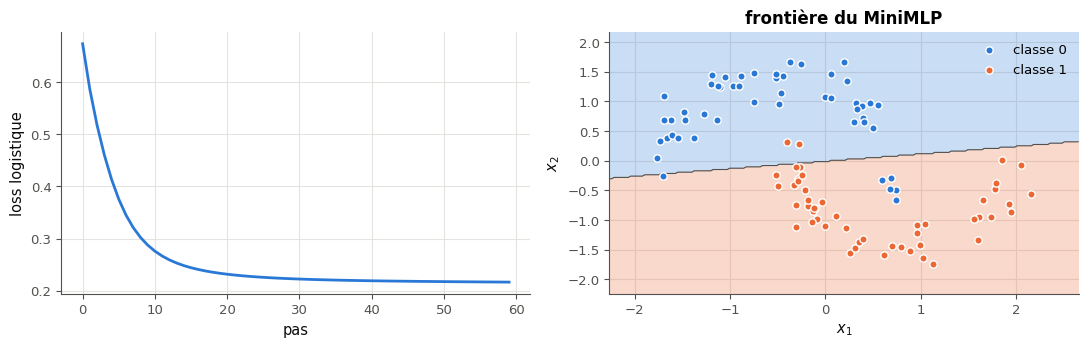

pytest: 22 passed, 74 deselected in 1.23s


In [61]:
if True:
    M = mylearn.autograd_mini.MiniMLP
    model_28 = M(2, [3, 1], activation="tanh", random_state=0)
    verdict("18.28", [W.shape for W, b in model_28.to_params()] == [(2, 3), (3, 1)] and len(model_28.parameters()) == 13,
            "MiniMLP(2, [3, 1]) : formes [(2, 3), (3, 1)] et 13 paramètres, comme la docstring.",
            "MiniMLP(2, [3, 1]) : to_params() doit rendre des W de formes [(2, 3), (3, 1)], et parameters() 13 Value.")
    model_28 = M(3, [5, 4, 2], activation="tanh", random_state=1828)
    x_28 = [0.3, -1.2, 0.8]
    outputs_28 = model_28(x_28)
    mine_28 = [o.data for o in outputs_28] if isinstance(outputs_28, list) else None
    want_28 = mylearn.nn.layers.mlp_forward(np.array([x_28]), model_28.to_params(), np.tanh)[0]
    if mine_28 is None:
        print(f"❌ Ex 18.28 : un MiniMLP à 2 sorties doit rendre une liste de 2 Value, reçu {type(outputs_28).__name__}.")
    else:
        same("18.28", "les sorties d'un MiniMLP 3-5-4-2 contre mlp_forward sur to_params()", mine_28, want_28)
    outputs_28[0].backward() if isinstance(outputs_28, list) else None
    model_28.zero_grad()
    verdict("18.28", all(p.grad == 0.0 for p in model_28.parameters()), "zero_grad remet tous les gradients à 0.",
            "après zero_grad, au moins un paramètre a encore un gradient non nul.")
CURVE_28 = None
if written(lambda: mylearn.autograd_mini.MiniMLP(2, [1], random_state=0)([0.0, 0.0])):
    if True:
        net_28 = mylearn.autograd_mini.MiniMLP(2, [8, 1], activation="tanh", random_state=1828)
        started_28 = time.perf_counter()
        CURVE_28 = train_28(net_28, STEPS_28)
        print(f"{STEPS_28} steps on {N_28} points in {time.perf_counter() - started_28:.1f} s · loss {CURVE_28[0]:.3f} -> {CURVE_28[-1]:.3f}")
        W_28 = net_28.to_params()
        acc_28 = float(np.mean((mylearn.nn.layers.mlp_forward(X_28, W_28, np.tanh)[:, 0] > 0) == y_28))
        verdict("18.28", CURVE_28[-1] < 0.5 * CURVE_28[0] and acc_28 >= 0.85,
                f"le MiniMLP apprend : loss divisée par {CURVE_28[0] / CURVE_28[-1]:.1f}, accuracy {acc_28:.3f}.",
                f"le MiniMLP n'apprend pas assez (loss {CURVE_28[0]:.3f} -> {CURVE_28[-1]:.3f}, accuracy {acc_28:.3f}) : "
                "vérifie parameters() (les Value elles-mêmes) et le signe de la mise à jour.")
        fig_28, (ax_c, ax_b) = plt.subplots(1, 2, figsize=(11, 3.6))
        ax_c.plot(CURVE_28)
        ax_c.set_xlabel("pas")
        ax_c.set_ylabel("loss logistique")
        wb.plot.plot_decision_boundary(type("Net", (), {"predict": lambda self, X: (mylearn.nn.layers.mlp_forward(X, W_28, np.tanh)[:, 0] > 0).astype(int)})(),
                                       X_28, y_28, ax=ax_b, title="frontière du MiniMLP")
        plt.tight_layout()
        plt.show()
    run_mylearn_tests(impl="ref", module="autograd_mini", keyword="test_mini_mlp_")
else:
    print("⏳ Ex 18.28 : les tests attendent ta classe.")

💡 Pour un exemple, la couche cachée crée environ $8 \times 5 = 40$ `Value` (deux produits, deux sommes et un tanh par neurone), la sortie une vingtaine, la loss quelques-unes : 65 `Value` par exemple (comptées sur le graphe), soit 6 500 pour un pas sur 100 exemples, chacune avec sa fonction `_backward` et un passage dans le tri topologique. Le même pas avec `mlp_forward` et `mlp_backward` fait une poignée de produits matriciels sur des tableaux $(100, 8)$ : moins d'une milliseconde, des centaines de fois plus vite. PyTorch garde l'idée du graphe, mais chaque nœud y est une opération sur un **tenseur** entier (un produit matriciel, une activation), avec sa formule de retour matricielle (celles de ∂ 18.7) : le nombre de nœuds ne dépend plus de la taille des données.

### Ex 18.29 — Défi MNIST : au moins 97 % avec ton MLP NumPy 🏆 ★★★★ ⏱️ 120 min
**Objectif :** entraîner un MLP avec ta propre librairie, sans PyTorch ni scikit-learn, jusqu'à 97 % d'accuracy sur le test de MNIST.  
**Prérequis :** Ex 18.19 · Ex 18.14 · ch. 16 (initialisations) · fiche §18.11, §18.12.5 · **Fil rouge :** MNIST · **Parcours :** C

Les 60 000 images d'entraînement de MNIST (`X_TRAIN_29`, valeurs dans $[0, 1]$, et leurs labels), et un **test caché** de 10 000 images. Écris `train_29(X, y)`, qui entraîne un MLP avec **ta** librairie (`init_mlp`, `mlp_forward`, une loss de 18.14, `mlp_backward` ; NumPy, aucune autre bibliothèque d'apprentissage) et rend le couple `(params, activation)` : la liste des `(W, b)` (784 entrées, 10 sorties, les logits) et la fonction d'activation cachée que `mlp_forward` doit utiliser. Tu choisis l'architecture, l'initialisation, la loss, le learning rate et son évolution, la taille des mini-batches et le nombre d'epochs.

Règles : l'entraînement dure **au plus 3 minutes** sur ta machine (la vérification le mesure) ; le défi est réussi avec une accuracy d'au moins **97 %** sur le test caché ; palier 🌟 : au moins 98 %. Règle d'honneur : n'utilise pas le test caché pour régler ta méthode (garde, par exemple, les 10 000 dernières images d'entraînement comme validation pendant tes essais) ; la vérification ne le révèle qu'une fois par session, et fige le résultat.

Dans tes notes : ta démarche (ce que tu as essayé, dans quel ordre, avec quelle validation), le temps d'une epoch, et ce qui a le plus compté : la taille du réseau, le learning rate, la taille des batches ou le nombre d'epochs ?

In [62]:
X_TRAIN_29, Y_TRAIN_29 = wb.datasets.load_mnist("train", flatten=True, normalize=True)
X_HIDDEN_29, Y_HIDDEN_29 = wb.datasets.load_mnist("test", flatten=True, normalize=True)   # the hidden test: do not look at it
TIME_LIMIT_29 = 180.0                                  # seconds of training, on your machine
print("train:", X_TRAIN_29.shape, X_TRAIN_29.dtype, "· hidden test:", X_HIDDEN_29.shape)

train: (60000, 784) float32 · hidden test: (10000, 784)


In [63]:
def train_29(X, y):
    """Train an MLP with YOUR library (mylearn.nn: init_mlp, mlp_forward, a loss of 18.14, mlp_backward; NumPy only)
    on the images X (shape (60000, 784), values in [0, 1]) and their labels y.

    Returns (params, activation): the trained [(W, b), ...] (784 inputs, 10 outputs: the logits) and the hidden
    activation function used by mlp_forward (for example mylearn.nn.activations.relu).
    """
    A, L, B = mylearn.nn.activations, mylearn.nn.layers, mylearn.nn.backward
    rng = np.random.default_rng(29)
    params = L.init_mlp([784, 256, 128, 10], "he_normal", rng)
    lr = 0.1
    for epoch in range(6):
        for idx in mylearn.utils.iterate_minibatches(len(X), 64, rng=rng):
            logits, cache = L.mlp_forward(X[idx], params, A.relu, None, return_cache=True)
            _, dout = B.softmax_cross_entropy(logits, y[idx])
            grads = B.mlp_backward(dout, cache, params, activation_derivative=A.relu_derivative)
            params = [(W - lr * dW, b - lr * db) for (W, b), (dW, db) in zip(params, grads)]
        lr *= 0.9                                      # a gentle decay: smaller steps once the network is close
    return params, A.relu
if True:
    started_29 = time.perf_counter()
    result_29 = train_29(X_TRAIN_29, Y_TRAIN_29)
    seconds_29 = time.perf_counter() - started_29
    ok_29 = isinstance(result_29, tuple) and len(result_29) == 2 and callable(result_29[1])
    if not ok_29:
        print("❌ Ex 18.29 : train_29 doit rendre le tuple (params, activation), activation étant une fonction.")
    else:
        params_29, activation_29 = result_29
        shapes_29 = [np.shape(W) for W, _ in params_29] if isinstance(params_29, list) else []
        ok_29 = (len(shapes_29) >= 2 and shapes_29[0][0] == 784 and shapes_29[-1][1] == 10
                 and all(a[1] == b[0] for a, b in zip(shapes_29[:-1], shapes_29[1:])))
        verdict("18.29", ok_29, f"un MLP {[784] + [s[1] for s in shapes_29]}, entraîné en {seconds_29:.0f} s.",
                f"params doit être une liste de (W, b) qui va de 784 entrées à 10 sorties ; reçu les formes {shapes_29}.")
        verdict("18.29", seconds_29 <= TIME_LIMIT_29, f"entraînement en moins de {TIME_LIMIT_29:.0f} s.",
                f"entraînement en {seconds_29:.0f} s : le défi demande moins de {TIME_LIMIT_29:.0f} s (moins d'epochs, un réseau plus petit, des batches plus grands).")
        ok_29 = ok_29 and seconds_29 <= TIME_LIMIT_29
    if ok_29:
        train_acc_29 = float(np.mean(mylearn.nn.layers.mlp_forward(X_TRAIN_29[:10_000], params_29, activation_29).argmax(axis=1)
                                     == Y_TRAIN_29[:10_000]))
        print(f"accuracy on 10 000 training images: {train_acc_29:.4f}")
        if globals().get("REVEALED_29") is None:              # revealed once per session (an honour rule)
            hidden_acc_29 = float(np.mean(mylearn.nn.layers.mlp_forward(X_HIDDEN_29, params_29, activation_29).argmax(axis=1) == Y_HIDDEN_29))
            REVEALED_29 = (hidden_acc_29, [784] + [s[1] for s in shapes_29], round(seconds_29))
        test_29, sizes_29, time_29 = REVEALED_29
        print(f"hidden test: {test_29:.4f} (revealed once per session, for the network {sizes_29} trained in {time_29} s)")
        verdict("18.29", test_29 >= 0.97,
                "défi réussi : au moins 97 % sur les 10 000 images du test caché." + (" 🌟 Palier atteint : au moins 98 %." if test_29 >= 0.98 else ""),
                "pas encore : il faut au moins 97 % sur le test caché.")

✅ Ex 18.29 : un MLP [784, 256, 128, 10], entraîné en 396 s.
❌ Ex 18.29 : entraînement en 396 s : le défi demande moins de 180 s (moins d'epochs, un réseau plus petit, des batches plus grands).


💡 La référence : un MLP 784-256-128-10 à ReLU, poids de He, cross-entropy softmax sur les logits, mini-batches de 64, $\eta = 0{,}1$ diminué de 10 % à chaque epoch, 6 epochs. Le détail des chiffres (temps, accuracy de validation et de test) est dans `05_solutions.md`.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu dérouler à la main la passe avant, les deltas et un pas de mise à jour d'un petit réseau ?
2. Sais-tu écrire les gradients d'une couche dense pour un mini-batch, et vérifier leurs formes ?
3. Sais-tu vérifier un gradient par différences finies, et reconnaître un learning rate mal réglé ?

**Pour aller plus loin** : le chapitre 2 du livre de M. Nielsen, les notes de CS231n et micrograd d'A. Karpathy, cités dans la fiche. La suite : le ch. 19, où les optimiseurs remplaceront la mise à jour $w \leftarrow w - \eta g$.